# Examen Parcial · Redes Neuronales y Aprendizaje Profundo · UNI FIIS 2026-II

**Integrantes**
1. Cánepa Maceda, Jhafet
2. Coaguila Berrios, Hipólito
3. Herrera Padilla, Lenin
4. Gutierrez Brenis, Berthing
5. Luque Canaza, Glenn
6. Mantari Martinez, Mario



## 1. Entorno

| Línea | Qué hace |
|---|---|
| `pip install` condicional | Instala `pydicom`, `timm` y `tifffile` solo si faltan (Colab ya trae torch, sklearn, matplotlib) |
| `Path(...).mkdir` | Crea las carpetas `knee_ws/` y `floods/` donde `%%writefile` dejará los módulos |
| `timed()` | *Context manager* que mide cada bloque de ejecución, lo imprime y lo registra en `CELL_TIMES` para la verificación final |
| `BUDGET_S = 10` | Presupuesto de tiempo por celda exigido |

In [97]:
import importlib, subprocess, sys, time, warnings
from contextlib import contextmanager
from pathlib import Path

for pkg, spec in (("pydicom", "pydicom>=2.4"), ("timm", "timm>=0.9"), ("tifffile", "tifffile>=2023.1")):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec], check=True)

for d in ("knee_ws", "floods"):
    Path(d).mkdir(exist_ok=True)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
BUDGET_S = 10.0
CELL_TIMES: dict[str, float] = {}


@contextmanager
def timed(label: str):
    t0 = time.perf_counter()
    yield
    dt = time.perf_counter() - t0
    CELL_TIMES[label] = dt
    print(f"⏱ {label}: {dt:.2f} s {'✓' if dt <= BUDGET_S else '✗ excede el presupuesto'}")

print(sys.version.split()[0])


3.13.15


## 2. Pregunta 1 · módulos del paquete `knee_ws`

Los módulos se escriben a disco y luego se importan. El orden respeta las dependencias internas (`config → textlabels → dicom → data → models → losses → train → explain → pipeline → experiments → plots → mock`).

### 2.1 `knee_ws/config.py` · configuración


| Bloque | Qué hace |
|---|---|
| `LABELS` | Las 12 etiquetas con el nombre exacto de las columnas de `train.csv` de la competencia |
| `detect_data_root()` | Busca los datos en `/kaggle/input/...`, luego en `KNEE_DATA_ROOT`, luego en `data/rsna-knee` |
| `Config` (`dataclass`) | Único punto de verdad: rutas, muestreo de cortes, arquitectura, pérdida, estrategia de ruido, hiperparámetros. Cada experimento de la ablación es un `dataclasses.replace(cfg, ...)`, así solo cambia el factor estudiado |
| `monitor = "holdout"` | **Corrección metodológica:** el *early stopping* vigila el AUC del *holdout* débil, nunca el dorado, que queda como validación limpia |
| `cache_dir` | Carpeta `cache_<img_size>` con un `.npz` por estudio; agnóstica al plano para no reprocesar al añadir el coronal |
| `seed_everything(seed, cudnn_benchmark)` | Fija semillas de `random`, `numpy` y `torch`; `cudnn.benchmark=False` en demo evita el autotuning de 15–20 s que aparecía en la primera época |
| `warmup_device()` | Un forward/backward mínimo en CUDA para pagar la inicialización del contexto fuera de las celdas cronometradas |

In [98]:
%%writefile knee_ws/config.py
from __future__ import annotations

import os
import random
from dataclasses import dataclass, field, asdict
from pathlib import Path

import numpy as np

LABELS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]


def detect_data_root() -> Path:
    kaggle = Path("/kaggle/input/rsna-knee-abnormality-detection")
    if kaggle.exists():
        return kaggle
    env = os.environ.get("KNEE_DATA_ROOT")
    if env:
        return Path(env)
    return Path("data/rsna-knee")


@dataclass
class Config:
    data_root: Path = field(default_factory=detect_data_root)
    work_dir: Path = Path("work")
    seed: int = 42

    report_col: str | None = None
    n_train_studies: int = 400
    min_pos_per_label: int = 15
    n_weak_holdout: int = 60

    planes: tuple[str, ...] = ("Sagittal",)
    prefer_fluid_sensitive: bool = True
    prefer_fat_suppression: bool = True
    target_slices: int = 32
    img_size: int = 224
    slices_per_study: int = 8
    triplet_gap: int = 1
    depth_range: tuple[float, float] = (0.10, 0.90)
    window_pct: tuple[float, float] = (1.0, 99.0)

    arch: str = "scratch"
    backbone: str = "resnet50"
    pretrained: bool = True
    pool: str = "attention"
    dropout: float = 0.3

    loss: str = "bce"
    focal_gamma: float = 2.0
    focal_alpha: float = 0.25
    noise_strategy: str = "weighted"
    high_conf_threshold: float = 0.7
    use_pos_weight: bool = False
    pos_weight_cap: float = 8.0
    oversample_rare: bool = True

    epochs: int = 12
    batch_size: int = 8
    lr: float = 3e-4
    backbone_lr_scale: float = 0.1
    weight_decay: float = 1e-4
    warmup_epochs: int = 1
    patience: int = 4
    monitor: str = "holdout"
    grad_clip: float = 2.0
    amp: bool = True
    num_workers: int = 2

    mock: bool = False
    mock_studies: int = 90
    mock_slices: int = 14
    mock_size: int = 64

    def __post_init__(self) -> None:
        self.data_root = Path(self.data_root)
        self.work_dir = Path(self.work_dir)
        self.work_dir.mkdir(parents=True, exist_ok=True)

    @property
    def cache_dir(self) -> Path:
        d = self.work_dir / f"cache_{self.img_size}"
        d.mkdir(parents=True, exist_ok=True)
        return d

    @property
    def dicom_dir(self) -> Path:
        return self.data_root / "train_series"

    def to_dict(self) -> dict:
        d = asdict(self)
        d["data_root"] = str(self.data_root)
        d["work_dir"] = str(self.work_dir)
        return d


def seed_everything(seed: int, cudnn_benchmark: bool = True) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch

        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = cudnn_benchmark
    except ImportError:
        pass


def warmup_device() -> str:
    import torch

    if not torch.cuda.is_available():
        return "cpu"
    x = torch.randn(2, 3, 32, 32, device="cuda", requires_grad=True)
    conv = torch.nn.Conv2d(3, 8, 3, padding=1).cuda()
    with torch.autocast(device_type="cuda"):
        conv(x).float().sum().backward()
    torch.cuda.synchronize()
    return torch.cuda.get_device_name(0)


Overwriting knee_ws/config.py


### 2.2 `knee_ws/textlabels.py` · etiquetas débiles multilingües (Entregable 1)


| Bloque | Qué hace |
|---|---|
| `normalize()` | Minúsculas, translitera `ı ł ø đ ß œ`, elimina diacríticos latinos y griegos pero **conserva los cirílicos** (NFKD descompondría `й`) |
| `detect_language()` | Identifica idioma por escritura (cirílico, griego) o por *stopwords* de 10 idiomas; solo se usa para el análisis de sesgo |
| `NEG_PRE` / `NEG_POST` / `NEG_WORD` + `NEGATABLE` | Negación **bidireccional**: cues antes del término anatómico, cues posteriores (turco `izlenmedi`, `saptanmadı`) y negación "a la derecha" solo si va seguida de algo negable (patología, "alteraciones") |
| `NORMAL_CUES`, `UNCERTAIN_CUES`, `PATHO_CUES`, `STRONG_POS`, `MINOR_CUES`, `MAJOR_CUES`, `CHRONIC_CUES` | Léxicos por función semántica, no por idioma: normalidad, incertidumbre, patología, severidad fuerte/menor/mayor y cronicidad |
| `ANATOMY` | Patrones por etiqueta en 12 idiomas; para las artrosis exige co-ocurrencia compartimento + cartílago/artrosis en la misma cláusula |
| `_max_size_cm()` | Parsea tamaños (`3.5 x 2 cm`, `12 mm`) para aplicar el criterio oficial "moderado o grande" en derrame y quiste de Baker |
| `_classify_clause()` | Decide el estado (`pos_strong`, `pos`, `uncertain`, `below_cut`, `neg`, `ambiguous`, `unmentioned`) con prioridad: negación → normalidad → cronicidad → severidad |
| `extract_study()` | Divide el reporte en frases y cláusulas; para cada etiqueta conserva el estado de mayor evidencia y el fragmento que lo justifica |
| `build_weak_labels()` | Convierte estados en **target suave** `p_*` y **peso de confianza** `w_*` por celda, más idioma y evidencia |
| `agreement_report()` / `agreement_by_language()` | Acuerdo, kappa, precisión/recall/F1 y AUC del target contra el conjunto dorado, global y por idioma |
| `TfidfLabeler` | Etiquetador de contraste: n-gramas de caracteres (3–5) + regresión logística uno-contra-resto, independiente del idioma |

In [99]:
%%writefile knee_ws/textlabels.py
from __future__ import annotations

import re
import unicodedata
from dataclasses import dataclass

import numpy as np
import pandas as pd

from .config import LABELS

_TRANSLIT = str.maketrans({"ı": "i", "ł": "l", "ø": "o", "đ": "d", "ß": "ss", "µ": "μ", "œ": "oe", "æ": "ae"})


def normalize(text: str) -> str:
    if not isinstance(text, str):
        return ""
    out: list[str] = []
    for c in unicodedata.normalize("NFKD", text.lower().translate(_TRANSLIT)):
        if unicodedata.combining(c) and not (out and "\u0400" <= out[-1] <= "\u04ff"):
            continue
        out.append(c)
    t = unicodedata.normalize("NFC", "".join(out))
    return re.sub(r"[ \t]+", " ", t)


_STOPWORDS = {
    "en": "the and of with is are no there normal without right left knee tear seen",
    "es": "el la de los las con sin del se no hay derecha izquierda rodilla una observa",
    "pt": "o a os as de do da com sem nao joelho direito esquerdo uma observa",
    "fr": "le la les des du de et avec sans pas genou droit gauche une est",
    "de": "der die das und mit ohne kein keine nicht im knie rechts links ist",
    "it": "il la di del della con senza non ginocchio destro sinistro una e",
    "nl": "de het van en met zonder geen niet knie rechter linker een is",
    "pl": "i w z na nie bez brak kolano prawe lewe jest oraz",
    "tr": "ve ile izlenmedi izlendi saptanmadi saptandi diz sag sol mevcut olarak",
    "hr": "i u na s bez nema koljeno desno lijevo je uredan uredna te",
}
_STOP_SETS = {k: set(v.split()) for k, v in _STOPWORDS.items()}


def detect_language(text: str) -> str:
    raw = text if isinstance(text, str) else ""
    if re.search(r"[Ѐ-ӿ]", raw):
        return "ru"
    if re.search(r"[Ͱ-Ͽ]", raw):
        return "el"
    tokens = re.findall(r"[a-z]+", normalize(raw))
    if not tokens:
        return "unknown"
    scores = {lang: sum(t in sw for t in tokens) for lang, sw in _STOP_SETS.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] >= 2 else "unknown"


def _rx(*alts: str) -> re.Pattern:
    return re.compile("|".join(alts))


NEG_PRE = _rx(
    r"\bno\b", r"\bsin\b", r"\bausencia\b", r"\bnot\b", r"\bwithout\b", r"\bfree of\b",
    r"\bnegative for\b", r"\bkein\w*\b", r"\bnicht\b", r"\bohne\b", r"\bpas d[e']", r"\bsans\b",
    r"\babsence\b", r"\bnessun\w*\b", r"\bassenza\b", r"\bnon\b", r"\bgeen\b", r"\bzonder\b",
    r"\bbrak\b", r"\bnie\b", r"\bbez\b", r"\bнет\b", r"\bбез\b", r"\bне\b", r"\bδεν\b",
    r"\bχωρις\b", r"\bnema\b", r"\bnao\b", r"\bnem\b", r"\bsem\b", r"\bni\b", r"\bnor\b", r"\bnoch\b",
    r"\bne\b", r"\bani\b", r"\bни\b", r"\bουτε\b", r"\bniti\b", r"\bexclu\w*\b", r"\bdescart\w*\b",
    r"\bausgeschlossen\b", r"\bnegativ\w*\b",
)
NEG_POST = _rx(
    r"izlenmedi", r"izlenmemistir", r"saptanmadi", r"saptanmamistir", r"gorulmedi",
    r"mevcut degil", r"bulunmamaktadir", r"\byok\b", r"\bnegativ\w*\b", r"not seen", r"not identified",
    r"is not\b", r"are not\b", r"no se (?:observa|identifica|evidencia)", r"nao se (?:observa|identifica)",
    r"n'est pas", r"ne sont pas", r"non si (?:osserva|evidenzia)", r"niet (?:aanwezig|zichtbaar)",
    r"nie stwierdz\w*", r"не (?:выявл|определ|визуализ)\w*", r"δεν (?:παρατηρ|διαπιστ)\w*",
    r"nije (?:vidljiv|uocen|nadjen)\w*", r"nem (?:lathato|eszlelheto)",
)
NORMAL_CUES = _rx(
    r"\bnormal\w*\b", r"\bintact\w*\b", r"\bintegr\w*\b", r"\bregelrecht\w*\b", r"\bunauffallig\w*\b",
    r"\bconservad\w*\b", r"\bpreservad\w*\b", r"\bpreserved\b", r"\bsaglam\b", r"\bintakt\w*\b",
    r"\bprawidlow\w*\b", r"\bnienaruszon\w*\b", r"\bцел\w*\b", r"\bнормальн\w*\b", r"\bсохранен\w*\b",
    r"\bне изменен\w*\b", r"\bφυσιολογ\w*\b", r"\bακεραι\w*\b", r"\bured[an]\w*\b", r"\bocuvan\w*\b",
    r"\bintatt\w*\b", r"\bunremarkable\b", r"\bwithin normal limits\b", r"\bphysiolog\w*\b",
    r"\bfisiolog\w*\b", r"\bfizjolog\w*\b", r"\bfizyolojik\b", r"\bфизиологич\w*\b", r"\bfiziolos\w*\b",
    r"\bhomogene\w*\b", r"\bindemne\b", r"\bindenne\b", r"\bnei limiti\b", r"\bnella norma\b",
    r"\bdans les limites\b", r"\bin ordnung\b", r"\bw normie\b", r"\bв пределах нормы\b", r"\bsinirlar\w*\b",
    r"\bu granicama\b", r"\bsin particularidades\b", r"\bsem particularidades\b", r"\bno abnormalit\w*\b",
)
UNCERTAIN_CUES = _rx(
    r"\bpossibl\w*\b", r"\bposibl\w*\b", r"\bprobabl\w*\b", r"\blikely\b", r"\bsuspect\w*\b",
    r"\bsospech\w*\b", r"\bcannot (?:be )?exclude\w*\b", r"\bno se descarta\b", r"\bmay represent\b",
    r"\bkonnte\b", r"\bmoglich\w*\b", r"\bverdacht\w*\b", r"\bsuspicion\b", r"\bsuspicieu\w*\b",
    r"\bpossibil\w*\b", r"\bsospett\w*\b", r"\bmogelijk\w*\b", r"\bverdenking\b", r"\bmozliw\w*\b",
    r"\bpodejrzen\w*\b", r"\bolasi\b", r"\bsuphe\w*\b", r"\bвозможн\w*\b", r"\bподозрен\w*\b",
    r"\bπιθαν\w*\b", r"\bmoguc\w*\b", r"\bsumnj\w*\b", r"\?", r"\bequivocal\b", r"\bdudos\w*\b",
    r"\bversus\b", r"\bvs\.?\b", r"\bpartial\w*\b", r"\bparcial\w*\b", r"\bpartiel\w*\b",
    r"\bparzial\w*\b", r"\bpartiel\w*\b", r"\bteilruptur\w*\b", r"\bteil\w*\b", r"\bkismi\b",
    r"\bczesciow\w*\b", r"\bчастичн\w*\b", r"\bμερικ\w*\b", r"\bdjelomic\w*\b",
)
PATHO_CUES = _rx(
    r"\btear\w*\b", r"\btorn\b", r"\brotur\w*\b", r"\bruptur\w*\b", r"\bdesgarr\w*\b", r"\blesion\w*\b",
    r"\binjur\w*\b", r"\briss\b", r"\bdechirur\w*\b", r"\blaceraz\w*\b", r"\bscheur\w*\b",
    r"\bletsel\b", r"\buszkodz\w*\b", r"\bpekniec\w*\b", r"\byirtik\w*\b", r"\bhasar\w*\b",
    r"\bразрыв\w*\b", r"\bповрежден\w*\b", r"\bρηξ\w*\b", r"\bβλαβ\w*\b", r"\bostecen\w*\b",
    r"\bedema\w*\b", r"\bedem\b", r"\bodem\w*\b", r"\boedem\w*\b", r"\bobrzek\w*\b", r"\bотек\w*\b",
    r"\bοιδημ\w*\b", r"\bsprain\w*\b", r"\besguinc\w*\b", r"\bdistors\w*\b", r"\bdegenera\w*\b",
    r"\bchondromalac\w*\b", r"\bcondromalac\w*\b", r"\bchondropath\w*\b", r"\bcondropat\w*\b",
    r"\bcartilage loss\b", r"\bperdida\b", r"\bthinning\b", r"\badelgaz\w*\b", r"\bosteofit\w*\b",
    r"\bosteophyt\w*\b", r"\bsubchondral\w*\b", r"\bsubcondral\w*\b", r"\bnarrowing\b",
    r"\bestrechamiento\b", r"\bgrade\b", r"\bgrado\b", r"\bgrad\b", r"\bfissur\w*\b", r"\bfisur\w*\b",
    r"\bdefect\w*\b", r"\bdefekt\w*\b", r"\bfull[- ]thickness\b", r"\bespesor total\b",
    r"\bcomplex\w*\b", r"\bcomplej\w*\b", r"\bbucket\b", r"\basa de balde\b", r"\bextru\w*\b",
    r"\btruncat\w*\b", r"\bdisplac\w*\b", r"\bdesplaz\w*\b", r"\bdiscontinu\w*\b", r"\babsent\b",
    r"\bausent\w*\b", r"\bavuls\w*\b", r"\barthros\w*\b", r"\bartros\w*\b", r"\bosteoarthr\w*\b",
    r"\bgonarthr\w*\b", r"\bgonartr\w*\b", r"\bdegenerativ\w*\b", r"\bsurface\b", r"\bsuperficie\b",
    r"\bradial\b", r"\bhorizontal\b", r"\bflap\b", r"\bkellgren\b", r"\bчастичн\w*\b",
    r"\bдегенерат\w*\b", r"\bистончен\w*\b", r"\bεκφυλ\w*\b", r"\bdegenerac\w*\b", r"\bzwyrodnien\w*\b",
    r"\bdejenera\w*\b", r"\bkopma\w*\b", r"\bincelme\w*\b", r"\bdisruption\b", r"\bdisrupt\w*\b",
    r"\bhigh[- ]grade\b", r"\balto grado\b", r"\bcomplet\w*\b", r"\bvollstandig\w*\b", r"\btam kat\b",
    r"\bkayb\w*\b", r"\badvanced\b", r"\bavanzad\w*\b", r"\bfortgeschritten\w*\b", r"\bevolue\w*\b",
    r"\bavance\w*\b", r"\bavanzat\w*\b", r"\bgevorderd\w*\b", r"\bzaawansowan\w*\b", r"\bileri\b",
    r"\bschaden\b", r"\bknorpelschaden\b", r"\bkaybi\b",
)
NEGATABLE = _rx(
    PATHO_CUES.pattern, r"\balterac\w*\b", r"\balterazion\w*\b", r"\banomal\w*\b",
    r"\babnormal\w*\b", r"\bafwijking\w*\b", r"\bzmian\w*\b", r"\bpromjen\w*\b", r"\bизменен\w*\b",
    r"\bαλλοιωσ\w*\b", r"\bbefund\w*\b", r"\bchange\w*\b", r"\bcambio\w*\b", r"\bevidence\b",
    r"\bevidencia\b", r"\bsignos?\b", r"\bsign\w*\b", r"\bsinais\b", r"\bsegni\b", r"\bnachweis\b",
    r"\bparticularit\w*\b", r"\bhallazgo\w*\b", r"\bpatholog\w*\b", r"\bpatolog\w*\b", r"\bsignificant\w*\b",
)
NEG_WORD = _rx(
    r"\bno\b", r"\bnot\b", r"\bwithout\b", r"\bsin\b", r"\bsem\b", r"\bsans\b", r"\bsenza\b", r"\bnon\b",
    r"\bohne\b", r"\bkein\w*\b", r"\bnicht\b", r"\bzonder\b", r"\bgeen\b", r"\bniet\b", r"\bbez\b",
    r"\bbrak\b", r"\bnie\b", r"\bбез\b", r"\bнет\b", r"\bне\b", r"\bχωρις\b", r"\bδεν\b", r"\bnema\b",
    r"\bnao\b", r"\bnem\b", r"\bfree of\b", r"\bnegative for\b",
)
STRONG_POS = _rx(
    r"\bcomplete\b", r"\bcomplet[ao]s?\b", r"\bcomplete tear\b", r"\bkomplett\w*\b", r"\bvollstandig\w*\b",
    r"\bcomplete\b", r"\bcompl[eè]t\w*\b", r"\bvolledig\w*\b", r"\bcalkowit\w*\b", r"\btam\b",
    r"\bполн\w*\b", r"\bπληρ\w*\b", r"\bpotpun\w*\b", r"\bdiscontinu\w*\b", r"\babsent\b",
    r"\bausent\w*\b", r"\bfull[- ]thickness\b", r"\bespesor total\b", r"\bbucket\b", r"\basa de balde\b",
    r"\bdisplaced\b", r"\bdesplazad\w*\b", r"\bhigh[- ]grade\b", r"\balto grado\b", r"\bgrade (?:3|iii)\b",
    r"\bgrado (?:3|iii)\b", r"\bgrad (?:3|iii)\b", r"\bexposed bone\b", r"\bhueso expuesto\b",
    r"\bbone on bone\b",
)
MINOR_CUES = _rx(
    r"\btrace\b", r"\bsmall\b", r"\bminim\w*\b", r"\bmild\w*\b", r"\bleve\w*\b", r"\bpequen\w*\b",
    r"\bescas\w*\b", r"\bscant\b", r"\bklein\w*\b", r"\bgering\w*\b", r"\bdiskret\w*\b",
    r"\bminime\b", r"\bpetit\w*\b", r"\bfaible\b", r"\bpiccol\w*\b", r"\blieve\w*\b", r"\bmodest\w*\b",
    r"\bniewielk\w*\b", r"\bmal[aey]\b", r"\baz miktar\w*\b", r"\bhafif\b", r"\bнебольш\w*\b",
    r"\bнезначительн\w*\b", r"\bмал\w*\b", r"\bμικρ\w*\b", r"\bελαχιστ\w*\b", r"\bneznatn\w*\b",
    r"\bmanj\w*\b", r"\bgrade (?:1|i)\b", r"\bgrado (?:1|i)\b", r"\bgrad (?:1|i)\b", r"\blow[- ]grade\b",
    r"\bbajo grado\b", r"\bintrasubstan\w*\b", r"\bintrasustanc\w*\b", r"\bmucoid\w*\b",
    r"\bmyxoid\w*\b", r"\bmixoid\w*\b", r"\bincipient\w*\b", r"\bsutil\w*\b", r"\bsubtle\b",
    r"\bfocal\w*\b", r"\bsuperficial\w*\b", r"\bslight\w*\b", r"\bligero\w*\b", r"\bligera\w*\b",
    r"\bdiscret\w*\b", r"\bsuave\b",
)
MAJOR_CUES = _rx(
    r"\bmoderat\w*\b", r"\blarge\b", r"\bgrande?s?\b", r"\babundant\w*\b", r"\bmarked\b",
    r"\bmarcad\w*\b", r"\bsignificant\w*\b", r"\bsignificativ\w*\b", r"\bmassig\w*\b", r"\bmittel\w*\b",
    r"\bgross\w*\b", r"\bausgepragt\w*\b", r"\bmoder\w*\b", r"\bimportant\w*\b", r"\bvolumineu\w*\b",
    r"\babbondant\w*\b", r"\babondant\w*\b", r"\bcospicu\w*\b", r"\bmatig\w*\b", r"\bfors\w*\b", r"\bumiarkowan\w*\b",
    r"\bduz\w*\b", r"\borta\b", r"\bbuyuk\b", r"\bbelirgin\b", r"\bумеренн\w*\b", r"\bвыраженн\w*\b",
    r"\bзначительн\w*\b", r"\bбольш\w*\b", r"\bμετρι\w*\b", r"\bμεγαλ\w*\b", r"\bumjeren\w*\b",
    r"\bvelik\w*\b", r"\bobiln\w*\b", r"\bextens\w*\b", r"\bsever[aeo]\w*\b", r"\bgrave\w*\b",
    r"\bgrade (?:2|3|ii|iii|4|iv)\b", r"\bgrado (?:2|3|ii|iii|4|iv)\b", r"\bgrad (?:2|3|ii|iii|4|iv)\b",
    r"\bdiffuse\w*\b", r"\bdifus\w*\b", r"\bkellgren\b", r"\bfull[- ]thickness\b", r"\bileri\b",
    r"\badvanced\b", r"\bavanzad\w*\b", r"\bfortgeschritten\w*\b", r"\bevolue\w*\b", r"\bavance\w*\b",
    r"\bavanzat\w*\b", r"\bgevorderd\w*\b", r"\bzaawansowan\w*\b", r"\btam kat\b",
)
CHRONIC_CUES = _rx(
    r"\bold\b", r"\bantigu\w*\b", r"\bchronic\w*\b", r"\bcronic\w*\b", r"\bhealed\b", r"\bconsolidat\w*\b",
    r"\balt(?:e|en|er|es)?\b", r"\bancien\w*\b", r"\bpregress\w*\b", r"\bguarit\w*\b", r"\boud\w*\b", r"\bgenezen\b",
    r"\bstar\w*\b", r"\bzagojon\w*\b", r"\beski\b", r"\biyilesmis\b", r"\bстар\w*\b", r"\bконсолидир\w*\b",
    r"\bпалаι\w*\b", r"\bεπουλωμ\w*\b", r"\bzacijelj\w*\b", r"\bremote\b", r"\bsequel\w*\b",
    r"\bsecuel\w*\b", r"\bpost[- ]?traumat\w*\b", r"\bprevious\b", r"\bprevi\w*\b", r"\bresidual\w*\b",
)

CARTILAGE = (
    r"cartilag|cartilaj|kartilaj|knorpel|chondr|condr|osteoarthr|artros|arthros|gonarthr|gonartr|"
    r"osteofit|osteophyt|degenerativ|degenerac|zwyrodnien|joint space|espacio articular|"
    r"gelenkspalt|interligne|rima articolare|szpara stawowa|eklem araligi|суставн\w* щел|хондр|"
    r"артроз|остеоартр|остеофит|χονδρ|οστεοαρθρ|αρθρ|hrskavic|artroz|kondr|kikirdak|osteoartrit|kraakbeen|chrzastk"
)

ANATOMY: dict[str, list[str]] = {
    "ACL": [
        r"anterior cruciate", r"\bacl\b", r"\blca\b", r"ligamento cruzado anterior", r"cruzado anterior",
        r"vorder\w* kreuzband", r"\bvkb\b", r"ligament croise anterieur", r"\blcae?\b",
        r"legamento crociato anteriore", r"crociato anteriore", r"voorste kruisband",
        r"wiezadl\w* krzyzow\w* przedni\w*", r"\bon capraz bag\w*", r"\boçb\b", r"\bocb\b",
        r"передн\w* крестообразн\w*", r"\bпкс\b", r"προσθι\w* χιαστ\w*", r"\bπχσ\b",
        r"prednj\w* ukrizen\w*", r"\bpuk\b", r"cruzado anterior",
    ],
    "MCL": [
        r"medial collateral", r"\bmcl\b", r"\blcm\b", r"\blci\b", r"ligamento colateral medial",
        r"colateral (?:medial|interno|tibial)", r"innenband", r"medial\w* seitenband", r"\bmsb\b",
        r"\bmcl\b", r"ligament collateral (?:medial|interne|tibial)", r"\blli\b",
        r"legamento collaterale mediale", r"collaterale mediale", r"mediale collaterale band",
        r"\bmcb\b", r"wiezadl\w* poboczn\w* piszczelow\w*", r"wiezadl\w* poboczn\w* przysrodkow\w*",
        r"medial kollateral", r"\bmkl\b", r"ic yan bag", r"медиальн\w* коллатеральн\w*",
        r"большеберцов\w* коллатеральн\w*", r"\bмкс\b", r"εσω πλαγι\w*", r"medijaln\w* kolateraln\w*",
        r"unutarnj\w* kolateraln\w*",
    ],
    "Medial Meniscus": [
        r"medial meniscus", r"medial meniscal", r"menisco medial", r"menisco interno", r"menisco mediale",
        r"menisque interne", r"menisque medial", r"innenmeniskus", r"medial\w* meniskus",
        r"mediale meniscus", r"lakotk\w* przysrodkow\w*", r"lakotk\w* wewnetrzn\w*",
        r"ic menisk\w*", r"medial menisk\w*", r"медиальн\w* мениск\w*", r"внутренн\w* мениск\w*",
        r"εσω μηνισκ\w*", r"medijaln\w* menisk\w*", r"unutarnj\w* menisk\w*", r"cuerno posterior del menisco medial",
    ],
    "Lateral Meniscus": [
        r"lateral meniscus", r"lateral meniscal", r"menisco lateral", r"menisco externo", r"menisco laterale",
        r"menisque externe", r"menisque lateral", r"aussenmeniskus", r"lateral\w* meniskus",
        r"laterale meniscus", r"lakotk\w* boczn\w*", r"lakotk\w* zewnetrzn\w*", r"dis menisk\w*",
        r"lateral menisk\w*", r"латеральн\w* мениск\w*", r"наружн\w* мениск\w*", r"εξω μηνισκ\w*",
        r"lateraln\w* menisk\w*", r"vanjsk\w* menisk\w*",
    ],
    "Medial OA": [
        rf"medial\w* (?:compartm\w*|compartim\w*|kompartm\w*|kompartiment\w*|tibiofemoral|femorotibial|femoro-?tibial\w*)(?:[^.;]{{0,80}}?)(?:{CARTILAGE})",
        rf"(?:{CARTILAGE})(?:[^.;]{{0,80}}?)medial (?:compartment|tibiofemoral|femorotibial|femoral condyle|tibial plateau)",
        rf"compartim\w* (?:medial|interno|femorotibial medial|tibiofemoral medial)(?:[^.;]{{0,80}}?)(?:{CARTILAGE})",
        rf"(?:{CARTILAGE})(?:[^.;]{{0,80}}?)compartim\w* (?:medial|interno|femorotibial medial|tibiofemoral medial)",
        rf"(?:{CARTILAGE})(?:[^.;]{{0,60}}?)(?:condilo|condyle|condyl|kondyl\w*|platillo|plateau|meseta|tibial) (?:femoral )?(?:medial|interno|interne|mediale|medial\w*)",
        rf"medial\w* kompartiment(?:[^.;]{{0,80}}?)(?:{CARTILAGE})", rf"(?:{CARTILAGE})(?:[^.;]{{0,80}}?)medial\w* kompartiment",
        rf"(?:{CARTILAGE})(?:[^.;]{{0,80}}?)(?:medial\w*|interne|mediale|medijaln\w*|przysrodkow\w*|ic|медиальн\w*|εσω)",
        r"medial\w* (?:gonarthrose|gonartrosi|osteoarthritis|osteoarthrosis|artrosis|arthrose)",
        r"(?:gonarthrose|gonartrosi|artros\w*|arthros\w*) (?:medial|interne|del compartimento medial|femorotibial medial)",
    ],
    "Lateral OA": [
        rf"lateral\w* (?:compartm\w*|compartim\w*|kompartm\w*|kompartiment\w*|tibiofemoral|femorotibial|femoro-?tibial\w*)(?:[^.;]{{0,80}}?)(?:{CARTILAGE})",
        rf"(?:{CARTILAGE})(?:[^.;]{{0,80}}?)lateral (?:compartment|tibiofemoral|femorotibial|femoral condyle|tibial plateau)",
        rf"compartim\w* (?:lateral|externo|femorotibial lateral|tibiofemoral lateral)(?:[^.;]{{0,80}}?)(?:{CARTILAGE})",
        rf"(?:{CARTILAGE})(?:[^.;]{{0,80}}?)compartim\w* (?:lateral|externo|femorotibial lateral|tibiofemoral lateral)",
        rf"(?:{CARTILAGE})(?:[^.;]{{0,60}}?)(?:condilo|condyle|condyl|kondyl\w*|platillo|plateau|meseta|tibial) (?:femoral )?(?:lateral|externo|externe|laterale|lateral\w*)",
        rf"lateral\w* kompartiment(?:[^.;]{{0,80}}?)(?:{CARTILAGE})", rf"(?:{CARTILAGE})(?:[^.;]{{0,80}}?)lateral\w* kompartiment",
        rf"(?:{CARTILAGE})(?:[^.;]{{0,80}}?)(?:lateral\w*|externe|laterale|lateraln\w*|boczn\w*|dis|латеральн\w*|εξω)",
        r"lateral\w* (?:gonarthrose|gonartrosi|osteoarthritis|osteoarthrosis|artrosis|arthrose)",
        r"(?:gonarthrose|gonartrosi|artros\w*|arthros\w*) (?:lateral|externe|del compartimento lateral|femorotibial lateral)",
    ],
    "PF OA": [
        rf"(?:patell?o?[- ]?femoral|patelofemoral|femoro[- ]?patel\w*|retropatel\w*|femoropatelar|patellofemoral\w*|femoropatellar\w*|retropatellar\w*)(?:[^.;]{{0,80}}?)(?:{CARTILAGE})",
        rf"(?:{CARTILAGE})(?:[^.;]{{0,80}}?)(?:patell?o?[- ]?femoral|patelofemoral|femoro[- ]?patel\w*|retropatel\w*|femoropatelar|patellofemoral\w*|femoropatellar\w*|retropatellar\w*|patel\w*|rotul\w*|kniescheib\w*|rzepk\w*|надколенник\w*|επιγονατιδ\w*|patela\w*|ivericka\w*|troclea\w*|trochle\w*)",
        rf"(?:patel\w*|rotul\w*|kniescheib\w*|rzepk\w*|надколенник\w*|επιγονατιδ\w*|troclea\w*|trochle\w*)(?:[^.;]{{0,60}}?)(?:{CARTILAGE})",
        r"chondromalac\w* (?:patel|rotul)\w*", r"condromalac\w* (?:patel|rotul)\w*", r"chondropathia patell\w*",
    ],
    "Effusion": [
        r"effusion", r"derrame", r"epanchement", r"erguss", r"versament\w*", r"hydrops", r"hydarthros\w*",
        r"hidrartros\w*", r"gewrichtsvocht", r"vocht in het gewricht", r"wysiek", r"plyn w stawie",
        r"efuzyon\w*", r"eklem (?:ici )?sivi\w*", r"выпот\w*", r"жидкост\w* в (?:полости )?сустав\w*",
        r"υγρ\w* (?:στην )?αρθρ\w*", r"συλλογ\w* υγρ\w*", r"izljev\w*", r"efuzij\w*",
        r"joint fluid", r"intra[- ]?articular fluid", r"liquido articular", r"liquido intraarticular",
        r"liquido (?:endo)?articolare", r"liquide (?:intra-?)?articulaire", r"gelenkfluss\w*",
        r"gelenkerguss", r"(?:trace|small|moderate|large|minimal|physiologic\w*|increased) (?:amount of )?(?:joint )?fluid",
        r"fluid in the (?:joint|suprapatellar)", r"suprapatellar (?:fluid|recess distension)",
    ],
    "Synovitis": [
        r"synovit\w*", r"sinovit\w*", r"synovialit\w*", r"zapalenie blony maziowej", r"синовит\w*",
        r"υμενιτιδ\w*", r"synovial (?:thickening|hypertrophy|proliferation|enhancement)",
        r"engrosamiento sinovial", r"hipertrofia sinovial", r"proliferacion sinovial",
        r"synovialverdickung", r"synovialhypertrophie", r"epaississement synovial", r"hypertrophie synoviale",
        r"ispessimento sinoviale", r"ipertrofia sinoviale", r"synoviale verdikking", r"pogrubienie blony maziowej",
        r"sinovyal (?:kalinlasma|hipertrofi|proliferasyon)", r"утолщени\w* синовиальн\w*",
        r"гипертрофи\w* синовиальн\w*", r"παχυνσ\w* (?:του )?υμεν\w*", r"zadebljanje sinovij\w*",
    ],
    "Baker's": [
        r"baker", r"popliteal cyst", r"quiste popliteo", r"quisto popliteo", r"cisto popliteo", r"kyste poplite",
        r"poplitealzyste", r"popliteal\w* zyste", r"cisti poplitea", r"popliteale cyste", r"torbiel podkolanow\w*",
        r"popliteal kist\w*", r"киста бейкера", r"подколенн\w* кист\w*", r"κυστ\w* (?:baker|μπεικερ|ιγνυακ\w*)",
        r"bakerova cist\w*", r"poplitealn\w* cist\w*", r"popliteal bursa (?:distension|fluid)",
        r"bursitis semimembranos\w*", r"semimembranos\w*[- ]gastrocnemi\w* burs\w*",
    ],
    "Contusion": [
        r"contusion\w*", r"contusao", r"contusione", r"kontusion\w*", r"kontuzyon\w*", r"bone bruis\w*",
        r"bone marrow (?:edema|oedema)", r"marrow (?:edema|oedema)", r"edema (?:oseo|de medula osea|medular|de la medular|intraoseo|trabecular)",
        r"edema osseo", r"edema della spongiosa", r"edema (?:midollare|subcondrale)", r"knochenmarkodem\w*",
        r"knochenkontusion\w*", r"knochenodem\w*", r"(?:oedeme|edeme) (?:osseux|medullaire|de la moelle)",
        r"botcontusie", r"beenmergoedeem", r"stluczenie kosci", r"obrzek szpiku", r"kemik iligi odemi",
        r"kemik odemi", r"ушиб\w* кост\w*", r"отек\w* костного мозга", r"трабекулярн\w* отек\w*",
        r"οστικ\w* οιδημ\w*", r"θλασ\w*", r"nagnjecenje kosti", r"edem kostane srzi", r"trabecular (?:edema|oedema)",
        r"edema trabecular", r"marrow signal abnormality", r"bone marrow lesion",
    ],
    "Fracture": [
        r"fractur\w*", r"fratur\w*", r"fraktur\w*", r"frattur\w*", r"fractuur", r"zlamani\w*", r"kirik\w*",
        r"перелом\w*", r"καταγμ\w*", r"prijelom\w*", r"\blom\b", r"avulsion\w*", r"avulsao", r"avulsione",
        r"segond", r"insufficiency", r"insuficienc\w*", r"stress (?:fracture|reaction|injury)",
        r"cortical (?:break|disruption|step)", r"trazo de fractura", r"linea de fractura", r"fracture line",
    ],
}

PATHO_TERM_LABELS = {"Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"}
SEVERITY_LABELS = {"Effusion", "Baker's"}
COMPILED = {k: _rx(*v) for k, v in ANATOMY.items()}

_CLAUSE_SPLIT = re.compile(r"[,;]|\b(?:and|y|e|et|und|en|i|ve|oraz|и|και|te)\b")
_SENT_SPLIT = re.compile(r"(?<=[.!?])\s+|\n+|•|•|\s-\s")

STATES = ["pos_strong", "pos", "uncertain", "below_cut", "neg", "ambiguous", "unmentioned"]
STATE_TARGET = {"pos_strong": 0.95, "pos": 0.85, "uncertain": 0.60, "below_cut": 0.25,
                "neg": 0.05, "ambiguous": 0.35, "unmentioned": 0.05}
STATE_WEIGHT = {"pos_strong": 1.0, "pos": 0.85, "uncertain": 0.5, "below_cut": 0.6,
                "neg": 1.0, "ambiguous": 0.3, "unmentioned": 0.35}
_STATE_RANK = {s: i for i, s in enumerate(STATES)}
_SIZE = re.compile(r"(\d+(?:[.,]\d+)?)\s*(?:x\s*\d+(?:[.,]\d+)?\s*)*(cm|mm)\b")


@dataclass
class Evidence:
    state: str
    snippet: str


def _max_size_cm(clause: str) -> float | None:
    sizes = [float(v.replace(",", ".")) / (10.0 if u == "mm" else 1.0) for v, u in _SIZE.findall(clause)]
    return max(sizes) if sizes else None


def _negated_after(post: str) -> bool:
    m = NEG_WORD.search(post)
    return bool(m) and bool(NEGATABLE.search(post[m.end():]))


def _classify_clause(label: str, clause: str, pre: str, post: str) -> str:
    if NEG_PRE.search(pre) or NEG_POST.search(post) or _negated_after(post):
        return "neg"
    has_patho = bool(PATHO_CUES.search(clause))
    if NORMAL_CUES.search(clause) and not has_patho:
        return "neg"
    if label == "Fracture" and CHRONIC_CUES.search(clause):
        return "below_cut"
    uncertain = bool(UNCERTAIN_CUES.search(clause))
    if label in SEVERITY_LABELS:
        size = _max_size_cm(clause)
        if MAJOR_CUES.search(clause) or (size is not None and size >= 3.0):
            return "uncertain" if uncertain else "pos_strong"
        if MINOR_CUES.search(clause) or (size is not None and size < 1.5):
            return "below_cut"
        return "uncertain" if uncertain else "pos"
    if label in PATHO_TERM_LABELS:
        return "uncertain" if uncertain else "pos"
    if STRONG_POS.search(clause):
        return "pos_strong"
    if uncertain:
        return "uncertain"
    if MINOR_CUES.search(clause) and not MAJOR_CUES.search(clause):
        return "below_cut"
    if has_patho:
        return "pos"
    return "ambiguous"


def extract_study(text: str) -> tuple[dict[str, str], dict[str, Evidence]]:
    norm = normalize(text)
    states = {lab: "unmentioned" for lab in LABELS}
    evidence: dict[str, Evidence] = {}
    for sent in _SENT_SPLIT.split(norm):
        sent = sent.strip()
        if not sent:
            continue
        clauses = [c.strip() for c in _CLAUSE_SPLIT.split(sent) if c and c.strip()]
        for clause in clauses:
            for lab, rx in COMPILED.items():
                m = rx.search(clause)
                if not m:
                    continue
                pre, post = clause[: m.start()], clause[m.end():]
                st = _classify_clause(lab, clause, pre, post)
                if _STATE_RANK[st] < _STATE_RANK[states[lab]]:
                    states[lab] = st
                    evidence[lab] = Evidence(st, clause[:160])
    return states, evidence


def build_weak_labels(df: pd.DataFrame, report_col: str) -> pd.DataFrame:
    rows = []
    for uid, txt in zip(df["StudyInstanceUID"], df[report_col]):
        states, ev = extract_study(txt)
        row = {"StudyInstanceUID": uid, "language": detect_language(txt)}
        for lab in LABELS:
            st = states[lab]
            row[f"state_{lab}"] = st
            row[f"p_{lab}"] = STATE_TARGET[st]
            row[f"w_{lab}"] = STATE_WEIGHT[st]
            row[f"ev_{lab}"] = ev[lab].snippet if lab in ev else ""
        rows.append(row)
    return pd.DataFrame(rows)


def find_report_column(df: pd.DataFrame, explicit: str | None = None) -> str:
    if explicit and explicit in df.columns:
        return explicit
    for cand in ("Report", "report", "Report_Text", "report_text", "Radiology_Report", "text", "Text"):
        if cand in df.columns:
            return cand
    obj_cols = [c for c in df.columns if c != "StudyInstanceUID" and c not in LABELS and df[c].dtype == object]
    if not obj_cols:
        raise ValueError("No free-text report column found in train.csv")
    return max(obj_cols, key=lambda c: df[c].astype(str).str.len().median())


def agreement_report(weak: pd.DataFrame, gold: pd.DataFrame) -> pd.DataFrame:
    from sklearn.metrics import cohen_kappa_score, f1_score, precision_score, recall_score, roc_auc_score

    merged = gold.merge(weak, on="StudyInstanceUID", how="inner")
    rows = []
    for lab in LABELS:
        y = merged[lab].astype(int).to_numpy()
        p = merged[f"p_{lab}"].to_numpy()
        yhat = (p >= 0.5).astype(int)
        auc = roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
        rows.append({
            "label": lab, "n_gold": len(y), "gold_pos": int(y.sum()),
            "agreement": float((yhat == y).mean()),
            "kappa": float(cohen_kappa_score(y, yhat)) if len(np.unique(y)) == 2 else np.nan,
            "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat, zero_division=0),
            "f1": f1_score(y, yhat, zero_division=0),
            "auc_soft": auc,
            "unmentioned_rate": float((merged[f"state_{lab}"] == "unmentioned").mean()),
        })
    out = pd.DataFrame(rows)
    summary = {"label": "MACRO", "n_gold": len(merged), "gold_pos": int(merged[LABELS].to_numpy().sum())}
    for c in ("agreement", "kappa", "precision", "recall", "f1", "auc_soft", "unmentioned_rate"):
        summary[c] = float(out[c].mean(skipna=True))
    return pd.concat([out, pd.DataFrame([summary])], ignore_index=True)


def agreement_by_language(weak: pd.DataFrame, gold: pd.DataFrame) -> pd.DataFrame:
    merged = gold.merge(weak, on="StudyInstanceUID", how="inner")
    rows = []
    for lang, g in merged.groupby("language"):
        y = g[LABELS].astype(int).to_numpy()
        yhat = (g[[f"p_{l}" for l in LABELS]].to_numpy() >= 0.5).astype(int)
        rows.append({"language": lang, "n_studies": len(g), "cell_agreement": float((y == yhat).mean()),
                     "overcall_rate": float(((yhat == 1) & (y == 0)).mean()),
                     "undercall_rate": float(((yhat == 0) & (y == 1)).mean())})
    return pd.DataFrame(rows).sort_values("n_studies", ascending=False).reset_index(drop=True)


class TfidfLabeler:
    def __init__(self, min_df: int = 2, C: float = 2.0) -> None:
        from sklearn.feature_extraction.text import TfidfVectorizer
        from sklearn.linear_model import LogisticRegression
        from sklearn.multiclass import OneVsRestClassifier
        from sklearn.pipeline import make_pipeline

        self.model = make_pipeline(
            TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=min_df, sublinear_tf=True, max_features=200_000),
            OneVsRestClassifier(LogisticRegression(C=C, max_iter=2000, class_weight="balanced")),
        )
        self.trained_labels: list[str] = []

    def fit(self, texts: list[str], y: np.ndarray) -> "TfidfLabeler":
        keep = [i for i in range(y.shape[1]) if len(np.unique(y[:, i])) == 2]
        self.trained_labels = [LABELS[i] for i in keep]
        self.model.fit([normalize(t) for t in texts], y[:, keep])
        return self

    def predict_proba(self, texts: list[str]) -> np.ndarray:
        proba = self.model.predict_proba([normalize(t) for t in texts])
        out = np.full((len(texts), len(LABELS)), 0.05, dtype=np.float32)
        for j, lab in enumerate(self.trained_labels):
            out[:, LABELS.index(lab)] = proba[:, j]
        return out


Overwriting knee_ws/textlabels.py


### 2.3 `knee_ws/dicom.py` · selección de series y caché


| Bloque | Qué hace |
|---|---|
| `_orientation_key()` | Ordena cortes proyectando `ImagePositionPatient` sobre la normal de `ImageOrientationPatient`; *fallback* a `InstanceNumber` |
| `_pixel_array()` | Aplica `RescaleSlope/Intercept`, invierte `MONOCHROME1`, toma el frame central en multiframe |
| `window_and_resize()` | Recorte al percentil 1–99 del volumen, reescalado con `area` (reduce aliasing al bajar resolución) y cuantización a `uint8` |
| `select_series()` | Por estudio y plano: prioridad `Fluid_Sensitive` + `Fat_Suppression`, desempate por cercanía a 32 cortes |
| `build_cache()` | Un `.npz` por estudio, procesado en paralelo con `ProcessPoolExecutor`; incremental por plano |

In [100]:
%%writefile knee_ws/dicom.py
from __future__ import annotations

from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import pydicom
import torch
import torch.nn.functional as F

from .config import Config


def _orientation_key(ds: pydicom.Dataset, fallback: int) -> float:
    try:
        iop = np.asarray(ds.ImageOrientationPatient, dtype=np.float64)
        ipp = np.asarray(ds.ImagePositionPatient, dtype=np.float64)
        normal = np.cross(iop[:3], iop[3:])
        return float(np.dot(ipp, normal))
    except Exception:
        return float(getattr(ds, "InstanceNumber", fallback))


def _pixel_array(ds: pydicom.Dataset) -> np.ndarray:
    arr = ds.pixel_array.astype(np.float32)
    if arr.ndim == 3:
        arr = arr[arr.shape[0] // 2]
    slope = float(getattr(ds, "RescaleSlope", 1.0) or 1.0)
    intercept = float(getattr(ds, "RescaleIntercept", 0.0) or 0.0)
    arr = arr * slope + intercept
    if str(getattr(ds, "PhotometricInterpretation", "MONOCHROME2")).upper() == "MONOCHROME1":
        arr = arr.max() - arr
    return arr


def load_series_volume(series_dir: Path) -> np.ndarray:
    files = sorted(series_dir.glob("*.dcm"))
    if not files:
        raise FileNotFoundError(series_dir)
    slices = []
    for i, f in enumerate(files):
        ds = pydicom.dcmread(f, force=True)
        slices.append((_orientation_key(ds, i), _pixel_array(ds)))
    slices.sort(key=lambda t: t[0])
    shapes = {s.shape for _, s in slices}
    if len(shapes) > 1:
        h = min(s.shape[0] for _, s in slices)
        w = min(s.shape[1] for _, s in slices)
        slices = [(k, s[:h, :w]) for k, s in slices]
    return np.stack([s for _, s in slices], axis=0)


def window_and_resize(vol: np.ndarray, img_size: int, window_pct: tuple[float, float]) -> np.ndarray:
    lo, hi = np.percentile(vol, window_pct)
    hi = max(hi, lo + 1e-3)
    vol = np.clip((vol - lo) / (hi - lo), 0.0, 1.0).astype(np.float32)
    t = torch.from_numpy(vol)[:, None]
    mode = "area" if vol.shape[-1] >= img_size else "bilinear"
    kwargs = {} if mode == "area" else {"align_corners": False}
    t = F.interpolate(t, size=(img_size, img_size), mode=mode, **kwargs)[:, 0]
    return (t.numpy() * 255.0).round().astype(np.uint8)


def select_series(series: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    rows = []
    for study, g in series.groupby("StudyInstanceUID", sort=False):
        for plane in cfg.planes:
            cand = g[g["Anatomical_Plane"].astype(str).str.lower() == plane.lower()].copy()
            if cand.empty:
                continue
            cand["prio"] = 0
            if cfg.prefer_fluid_sensitive and "Fluid_Sensitive" in cand:
                cand["prio"] += 2 * cand["Fluid_Sensitive"].fillna(0).astype(int)
            if cfg.prefer_fat_suppression and "Fat_Suppression" in cand:
                cand["prio"] += cand["Fat_Suppression"].fillna(0).astype(int)
            cand["n_slices"] = [
                len(list((cfg.dicom_dir / study / s).glob("*.dcm"))) for s in cand["SeriesInstanceUID"]
            ]
            cand["dist"] = (cand["n_slices"] - cfg.target_slices).abs()
            best = cand.sort_values(["prio", "dist"], ascending=[False, True]).iloc[0]
            rows.append({"StudyInstanceUID": study, "plane": plane, "SeriesInstanceUID": best["SeriesInstanceUID"],
                         "n_slices": int(best["n_slices"]), "prio": int(best["prio"])})
    return pd.DataFrame(rows)


def _cache_one(args: tuple[str, dict[str, Path], int, tuple[float, float], Path]) -> tuple[str, bool, str]:
    study, plane_dirs, img_size, window_pct, out = args
    arrays: dict[str, np.ndarray] = {}
    if out.exists():
        with np.load(out) as z:
            arrays = {k: z[k] for k in z.files}
        if all(p in arrays for p in plane_dirs):
            return study, True, "cached"
    try:
        for plane, d in plane_dirs.items():
            if plane not in arrays:
                arrays[plane] = window_and_resize(load_series_volume(d), img_size, window_pct)
        np.savez_compressed(out, **arrays)
        return study, True, "ok"
    except Exception as exc:
        return study, False, f"{type(exc).__name__}: {exc}"


def build_cache(cfg: Config, selection: pd.DataFrame, workers: int | None = None) -> pd.DataFrame:
    jobs = []
    for study, g in selection.groupby("StudyInstanceUID", sort=False):
        plane_dirs = {r.plane: cfg.dicom_dir / study / r.SeriesInstanceUID for r in g.itertuples()}
        jobs.append((study, plane_dirs, cfg.img_size, cfg.window_pct, cfg.cache_dir / f"{study}.npz"))
    results = []
    workers = workers or max(1, cfg.num_workers)
    if workers == 1:
        results = [_cache_one(j) for j in jobs]
    else:
        with ProcessPoolExecutor(max_workers=workers) as ex:
            futs = [ex.submit(_cache_one, j) for j in jobs]
            for f in as_completed(futs):
                results.append(f.result())
    df = pd.DataFrame(results, columns=["StudyInstanceUID", "ok", "status"])
    failed = df[~df["ok"]]
    if len(failed):
        print(f"[cache] {len(failed)} studies failed:\n{failed.head()}")
    return df


def load_cached(cfg: Config, study: str) -> dict[str, np.ndarray]:
    with np.load(cfg.cache_dir / f"{study}.npz") as z:
        return {k: z[k] for k in z.files}


Overwriting knee_ws/dicom.py


### 2.4 `knee_ws/data.py` · dataset 2.5D


| Bloque | Qué hace |
|---|---|
| `sample_centers()` | Posiciones uniformes en el 10–90 % de la profundidad, con *jitter* solo en entrenamiento |
| `triplets()` | Para cada centro arma `[i-g, i, i+g]` como 3 canales (2.5D) |
| `study_affine()` | Misma transformación afín (rotación ±10°, escala 0.9–1.1, traslación) para todos los cortes del estudio: aumentación consistente, sin volteos |
| `KneeStudyDataset` | Devuelve `x:[K,3,H,W]`, target suave `y:[12]`, peso `w:[12]` e id; normalización ImageNet solo para backbones preentrenados |
| `make_sampler()` | `WeightedRandomSampler` que sobre-muestrea estudios con positivos raros (mitigación del desbalance) |
| `apply_noise_strategy()` | `weighted` (peso de confianza), `high_conf` (solo celdas con `w ≥ 0.7`) o `all` (sin ponderar) |

In [101]:
%%writefile knee_ws/data.py
from __future__ import annotations

import math

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, WeightedRandomSampler

from .config import LABELS, Config
from .dicom import load_cached

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def sample_centers(n: int, k: int, depth_range: tuple[float, float], jitter: bool, rng: np.random.Generator) -> np.ndarray:
    lo, hi = depth_range
    pos = np.linspace(lo, hi, k) * (n - 1)
    if jitter:
        pos = pos + rng.uniform(-0.5, 0.5, size=k) * max((hi - lo) * (n - 1) / max(k - 1, 1), 1.0)
    return np.clip(np.round(pos), 0, n - 1).astype(int)


def triplets(vol: np.ndarray, centers: np.ndarray, gap: int) -> np.ndarray:
    n = vol.shape[0]
    idx = np.stack([np.clip(centers - gap, 0, n - 1), centers, np.clip(centers + gap, 0, n - 1)], axis=1)
    return vol[idx]


def study_affine(x: torch.Tensor, rng: np.random.Generator) -> torch.Tensor:
    k = x.shape[0]
    angle = math.radians(rng.uniform(-10, 10))
    scale = rng.uniform(0.9, 1.1)
    tx, ty = rng.uniform(-0.06, 0.06, size=2)
    cos, sin = math.cos(angle) / scale, math.sin(angle) / scale
    theta = torch.tensor([[cos, -sin, tx], [sin, cos, ty]], dtype=x.dtype).unsqueeze(0).expand(k, 2, 3)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=False)


class KneeStudyDataset(Dataset):
    def __init__(self, cfg: Config, studies: list[str], targets: np.ndarray, weights: np.ndarray,
                 train: bool, imagenet_norm: bool) -> None:
        self.cfg, self.studies, self.train, self.imagenet_norm = cfg, list(studies), train, imagenet_norm
        self.targets = torch.as_tensor(targets, dtype=torch.float32)
        self.weights = torch.as_tensor(weights, dtype=torch.float32)

    def __len__(self) -> int:
        return len(self.studies)

    def __getitem__(self, i: int) -> dict:
        rng = np.random.default_rng(None if self.train else self.cfg.seed + i)
        vols = load_cached(self.cfg, self.studies[i])
        stacks = []
        for plane in self.cfg.planes:
            vol = vols[plane]
            centers = sample_centers(vol.shape[0], self.cfg.slices_per_study, self.cfg.depth_range, self.train, rng)
            stacks.append(triplets(vol, centers, self.cfg.triplet_gap))
        x = torch.from_numpy(np.concatenate(stacks, axis=0)).float() / 255.0
        if self.train:
            x = study_affine(x, rng)
            x = x * rng.uniform(0.85, 1.15) + rng.uniform(-0.08, 0.08)
            x = x.clamp(0, 1)
        x = (x - IMAGENET_MEAN) / IMAGENET_STD if self.imagenet_norm else (x - 0.5) / 0.25
        return {"x": x, "y": self.targets[i], "w": self.weights[i], "id": self.studies[i]}


def make_sampler(targets: np.ndarray, rare_boost: float = 3.0) -> WeightedRandomSampler:
    hard = (targets >= 0.5).astype(np.float32)
    prev = np.clip(hard.mean(axis=0), 1e-3, None)
    rarity = (1.0 / prev) / (1.0 / prev).max()
    w = 1.0 + rare_boost * (hard * rarity[None]).max(axis=1)
    return WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(w), replacement=True)


def apply_noise_strategy(p: np.ndarray, w: np.ndarray, strategy: str, threshold: float) -> tuple[np.ndarray, np.ndarray]:
    if strategy == "all":
        return p, np.ones_like(w)
    if strategy == "high_conf":
        return p, (w >= threshold).astype(np.float32)
    if strategy == "weighted":
        return p, w
    raise ValueError(strategy)


def prevalence_table(df: pd.DataFrame, cols: list[str] | None = None) -> pd.DataFrame:
    cols = cols or LABELS
    vals = df[cols].to_numpy()
    return pd.DataFrame({"label": cols, "n_pos": (vals >= 0.5).sum(axis=0).astype(int),
                         "prevalence": (vals >= 0.5).mean(axis=0), "n_total": len(df)})


Overwriting knee_ws/data.py


### 2.5 `knee_ws/models.py` · arquitecturas (Entregable 2)


| Bloque | Qué hace |
|---|---|
| `conv_block()` + `SqueezeExcite` | Bloque doble conv-BN-SiLU con recalibración de canales |
| `ScratchEncoder` | CNN desde cero: stem 5×5/2 + 4 etapas con *max-pool*; 1.3 M parámetros |
| `TimmEncoder` | Backbone ImageNet vía `timm` (`resnet50` por defecto); si no hay pesos cae a inicialización aleatoria avisando |
| `GatedAttentionPool` | *Gated attention MIL* (Ilse et al., 2018): pondera los cortes y devuelve el vector del estudio y los pesos de atención |
| `StudyNet` | Codificador compartido → *pooling* por atención/mean/max → `LayerNorm → Dropout → Linear(12)`; `param_groups()` aplica LR reducida al backbone |

In [102]:
%%writefile knee_ws/models.py
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F

from .config import LABELS, Config


def conv_block(cin: int, cout: int) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.SiLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.SiLU(inplace=True),
    )


class SqueezeExcite(nn.Module):
    def __init__(self, c: int, r: int = 8) -> None:
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(c, c // r), nn.SiLU(inplace=True), nn.Linear(c // r, c), nn.Sigmoid())

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        s = self.fc(x.mean(dim=(2, 3)))
        return x * s[:, :, None, None]


class ScratchEncoder(nn.Module):
    def __init__(self, widths: tuple[int, ...] = (32, 64, 128, 256), in_chans: int = 3) -> None:
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(in_chans, widths[0], 5, stride=2, padding=2, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.SiLU(inplace=True))
        layers, cin = [], widths[0]
        for i, w in enumerate(widths):
            layers += [conv_block(cin, w), SqueezeExcite(w)]
            if i < len(widths) - 1:
                layers.append(nn.MaxPool2d(2))
            cin = w
        self.body = nn.Sequential(*layers)
        self.num_features = widths[-1]

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.body(self.stem(x))


class TimmEncoder(nn.Module):
    def __init__(self, name: str, pretrained: bool) -> None:
        super().__init__()
        import timm

        try:
            self.net = timm.create_model(name, pretrained=pretrained, num_classes=0, global_pool="")
        except Exception as exc:
            print(f"[timm] pretrained weights unavailable ({type(exc).__name__}); falling back to random init")
            self.net = timm.create_model(name, pretrained=False, num_classes=0, global_pool="")
        self.num_features = self.net.num_features

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net.forward_features(x)


class GatedAttentionPool(nn.Module):
    def __init__(self, dim: int, hidden: int = 128) -> None:
        super().__init__()
        self.v = nn.Linear(dim, hidden)
        self.u = nn.Linear(dim, hidden)
        self.w = nn.Linear(hidden, 1)

    def forward(self, h: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        a = self.w(torch.tanh(self.v(h)) * torch.sigmoid(self.u(h))).squeeze(-1)
        a = torch.softmax(a, dim=1)
        return (a.unsqueeze(-1) * h).sum(dim=1), a


class StudyNet(nn.Module):
    def __init__(self, cfg: Config) -> None:
        super().__init__()
        self.encoder = ScratchEncoder() if cfg.arch == "scratch" else TimmEncoder(cfg.backbone, cfg.pretrained)
        d = self.encoder.num_features
        self.pool_mode = cfg.pool
        self.attn = GatedAttentionPool(d) if cfg.pool == "attention" else None
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(cfg.dropout), nn.Linear(d, len(LABELS)))

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        b, k = x.shape[:2]
        return self.encoder(x.flatten(0, 1)).mean(dim=(2, 3)).view(b, k, -1)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        h = self.encode(x)
        if self.attn is not None:
            z, a = self.attn(h)
        elif self.pool_mode == "max":
            z, a = h.max(dim=1).values, torch.full(h.shape[:2], 1.0 / h.shape[1], device=h.device)
        else:
            z, a = h.mean(dim=1), torch.full(h.shape[:2], 1.0 / h.shape[1], device=h.device)
        return self.head(z), a

    def param_groups(self, lr: float, backbone_scale: float, weight_decay: float) -> list[dict]:
        enc = list(self.encoder.parameters())
        enc_ids = {id(p) for p in enc}
        rest = [p for p in self.parameters() if id(p) not in enc_ids]
        return [{"params": enc, "lr": lr * backbone_scale, "weight_decay": weight_decay},
                {"params": rest, "lr": lr, "weight_decay": weight_decay}]


def count_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


Overwriting knee_ws/models.py


### 2.6 `knee_ws/losses.py`


| Bloque | Qué hace |
|---|---|
| `WeightedBCE` | BCE con logits y targets suaves, ponderada por el peso de confianza de cada celda |
| `FocalLoss` | Focal (Lin et al., 2017) con los mismos pesos; reduce la contribución de ejemplos fáciles |
| `compute_pos_weight()` | `neg/pos` por etiqueta acotado a `pos_weight_cap` para evitar el colapso por sobre-predicción |

In [103]:
%%writefile knee_ws/losses.py
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


class WeightedBCE(nn.Module):
    def __init__(self, pos_weight: torch.Tensor | None = None) -> None:
        super().__init__()
        self.register_buffer("pos_weight", pos_weight if pos_weight is not None else torch.tensor(1.0))

    def forward(self, logits: torch.Tensor, target: torch.Tensor, weight: torch.Tensor) -> torch.Tensor:
        loss = F.binary_cross_entropy_with_logits(logits, target, pos_weight=self.pos_weight, reduction="none")
        return (loss * weight).sum() / weight.sum().clamp_min(1.0)


class FocalLoss(nn.Module):
    def __init__(self, gamma: float = 2.0, alpha: float = 0.25) -> None:
        super().__init__()
        self.gamma, self.alpha = gamma, alpha

    def forward(self, logits: torch.Tensor, target: torch.Tensor, weight: torch.Tensor) -> torch.Tensor:
        p = torch.sigmoid(logits)
        ce = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
        p_t = p * target + (1 - p) * (1 - target)
        alpha_t = self.alpha * target + (1 - self.alpha) * (1 - target)
        loss = alpha_t * (1 - p_t).pow(self.gamma) * ce
        return (loss * weight).sum() / weight.sum().clamp_min(1.0)


def build_loss(name: str, pos_weight: torch.Tensor | None, gamma: float, alpha: float) -> nn.Module:
    if name == "bce":
        return WeightedBCE(pos_weight)
    if name == "focal":
        return FocalLoss(gamma, alpha)
    raise ValueError(name)


def compute_pos_weight(targets, cap: float) -> torch.Tensor:
    import numpy as np

    hard = (np.asarray(targets) >= 0.5)
    pos = hard.sum(axis=0).clip(1)
    neg = (~hard).sum(axis=0).clip(1)
    return torch.as_tensor(np.minimum(neg / pos, cap), dtype=torch.float32)


Overwriting knee_ws/losses.py


### 2.7 `knee_ws/train.py` · entrenamiento y métricas


| Bloque | Qué hace |
|---|---|
| `macro_auc()` | AUC-ROC por etiqueta (omite etiquetas sin ambas clases) y su promedio: métrica oficial |
| `predict()` | Inferencia con `autocast` en GPU, devuelve probabilidades, targets e ids |
| `choose_thresholds()` | Umbral por etiqueta que maximiza F1 en el **holdout débil** |
| `classification_report()` | AUC, precisión, recall y F1 por etiqueta y macro |
| `train_model()` | AdamW + warmup lineal + coseno por paso, AMP, recorte de gradiente, *early stopping* sobre `cfg.monitor` (`holdout`). `track` controla qué conjuntos se evalúan por época para ahorrar tiempo |

In [104]:
%%writefile knee_ws/train.py
from __future__ import annotations

import copy
import math
import time

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from torch.utils.data import DataLoader

from .config import LABELS, Config
from .data import KneeStudyDataset, make_sampler
from .losses import build_loss, compute_pos_weight
from .models import StudyNet, count_params


def device_of(cfg: Config) -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def macro_auc(y: np.ndarray, p: np.ndarray) -> tuple[float, dict[str, float]]:
    per = {}
    for j, lab in enumerate(LABELS):
        yj = (y[:, j] >= 0.5).astype(int)
        per[lab] = roc_auc_score(yj, p[:, j]) if len(np.unique(yj)) == 2 else float("nan")
    vals = [v for v in per.values() if not math.isnan(v)]
    return (float(np.mean(vals)) if vals else float("nan")), per


@torch.no_grad()
def predict(model: StudyNet, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray, list[str]]:
    model.eval()
    probs, ys, ids = [], [], []
    for batch in loader:
        x = batch["x"].to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            logits, _ = model(x)
        probs.append(torch.sigmoid(logits.float()).cpu().numpy())
        ys.append(batch["y"].numpy())
        ids += list(batch["id"])
    return np.concatenate(probs), np.concatenate(ys), ids


def choose_thresholds(y_ref: np.ndarray, p_ref: np.ndarray, grid: np.ndarray | None = None) -> np.ndarray:
    grid = grid if grid is not None else np.linspace(0.05, 0.95, 19)
    th = np.full(len(LABELS), 0.5)
    hard = (y_ref >= 0.5).astype(int)
    for j in range(len(LABELS)):
        if len(np.unique(hard[:, j])) < 2:
            continue
        scores = [f1_score(hard[:, j], (p_ref[:, j] >= t).astype(int), zero_division=0) for t in grid]
        th[j] = grid[int(np.argmax(scores))]
    return th


def classification_report(y: np.ndarray, p: np.ndarray, thresholds: np.ndarray) -> pd.DataFrame:
    hard = (y >= 0.5).astype(int)
    rows = []
    for j, lab in enumerate(LABELS):
        yhat = (p[:, j] >= thresholds[j]).astype(int)
        auc = roc_auc_score(hard[:, j], p[:, j]) if len(np.unique(hard[:, j])) == 2 else float("nan")
        rows.append({"label": lab, "n_pos": int(hard[:, j].sum()), "threshold": float(thresholds[j]), "auc": auc,
                     "precision": precision_score(hard[:, j], yhat, zero_division=0),
                     "recall": recall_score(hard[:, j], yhat, zero_division=0),
                     "f1": f1_score(hard[:, j], yhat, zero_division=0)})
    df = pd.DataFrame(rows)
    macro = {"label": "MACRO", "n_pos": int(df["n_pos"].sum()), "threshold": float("nan")}
    for c in ("auc", "precision", "recall", "f1"):
        macro[c] = float(df[c].mean(skipna=True))
    return pd.concat([df, pd.DataFrame([macro])], ignore_index=True)


def build_loaders(cfg: Config, train_ids, train_p, train_w, eval_sets: dict[str, tuple[list[str], np.ndarray]],
                  imagenet_norm: bool) -> tuple[DataLoader, dict[str, DataLoader]]:
    ds = KneeStudyDataset(cfg, train_ids, train_p, train_w, train=True, imagenet_norm=imagenet_norm)
    sampler = make_sampler(train_p) if cfg.oversample_rare else None
    pin = torch.cuda.is_available()
    train_loader = DataLoader(ds, batch_size=cfg.batch_size, sampler=sampler, shuffle=sampler is None,
                              num_workers=cfg.num_workers, pin_memory=pin, drop_last=len(ds) > cfg.batch_size,
                              persistent_workers=cfg.num_workers > 0)
    eval_loaders = {}
    for name, (ids, y) in eval_sets.items():
        eds = KneeStudyDataset(cfg, ids, y, np.ones_like(y), train=False, imagenet_norm=imagenet_norm)
        eval_loaders[name] = DataLoader(eds, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, pin_memory=pin)
    return train_loader, eval_loaders


def train_model(cfg: Config, train_ids: list[str], train_p: np.ndarray, train_w: np.ndarray,
                eval_sets: dict[str, tuple[list[str], np.ndarray]], monitor: str | None = None, verbose: bool = True,
                track: tuple[str, ...] | None = None) -> dict:
    monitor = monitor or cfg.monitor
    track = track or tuple(eval_sets)
    device = device_of(cfg)
    imagenet_norm = cfg.arch != "scratch"
    train_loader, eval_loaders = build_loaders(cfg, train_ids, train_p, train_w, eval_sets, imagenet_norm)
    model = StudyNet(cfg).to(device)
    pos_weight = compute_pos_weight(train_p, cfg.pos_weight_cap).to(device) if cfg.use_pos_weight else None
    criterion = build_loss(cfg.loss, pos_weight, cfg.focal_gamma, cfg.focal_alpha).to(device)
    scale = cfg.backbone_lr_scale if cfg.arch != "scratch" else 1.0
    opt = torch.optim.AdamW(model.param_groups(cfg.lr, scale, cfg.weight_decay))
    steps_per_epoch = max(len(train_loader), 1)
    total = cfg.epochs * steps_per_epoch
    warm = cfg.warmup_epochs * steps_per_epoch

    def lr_lambda(step: int) -> float:
        if step < warm:
            return (step + 1) / max(warm, 1)
        prog = (step - warm) / max(total - warm, 1)
        return 0.5 * (1 + math.cos(math.pi * prog))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = torch.amp.GradScaler(enabled=cfg.amp and device.type == "cuda")
    history, best_auc, best_state, best_epoch, bad = [], -1.0, None, -1, 0
    if verbose:
        print(f"[train] arch={cfg.arch} backbone={cfg.backbone if cfg.arch != 'scratch' else '-'} "
              f"params={count_params(model)/1e6:.2f}M loss={cfg.loss} noise={cfg.noise_strategy} "
              f"planes={cfg.planes} monitor={monitor}_auc device={device}")
    for epoch in range(cfg.epochs):
        model.train()
        t0, run_loss, n = time.time(), 0.0, 0
        for batch in train_loader:
            x = batch["x"].to(device, non_blocking=True)
            y = batch["y"].to(device, non_blocking=True)
            w = batch["w"].to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=cfg.amp and device.type == "cuda"):
                logits, _ = model(x)
            loss = criterion(logits.float(), y, w)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(opt)
            scaler.update()
            sched.step()
            run_loss += loss.item() * x.shape[0]
            n += x.shape[0]
        rec = {"epoch": epoch + 1, "train_loss": run_loss / max(n, 1), "lr": opt.param_groups[-1]["lr"], "time": time.time() - t0}
        for name, loader in eval_loaders.items():
            if name not in track and name != monitor:
                continue
            p, y, _ = predict(model, loader, device)
            rec[f"{name}_auc"], _ = macro_auc(y, p)
        history.append(rec)
        if verbose:
            print("  " + " | ".join(f"{k}={v:.4f}" if isinstance(v, float) else f"{k}={v}" for k, v in rec.items()))
        cur = rec.get(f"{monitor}_auc", -rec["train_loss"])
        if not math.isnan(cur) and cur > best_auc:
            best_auc, best_state, best_epoch, bad = cur, copy.deepcopy(model.state_dict()), epoch + 1, 0
        else:
            bad += 1
            if bad >= cfg.patience:
                if verbose:
                    print(f"  early stop at epoch {epoch + 1}")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    preds = {name: predict(model, loader, device) for name, loader in eval_loaders.items()}
    return {"model": model, "history": pd.DataFrame(history), "best_auc": best_auc, "best_epoch": best_epoch,
            "monitor": monitor, "preds": preds, "config": cfg.to_dict()}


Overwriting knee_ws/train.py


### 2.8 `knee_ws/explain.py` · Grad-CAM


| Bloque | Qué hace |
|---|---|
| `gradcam_study()` | Hook en la salida del codificador, gradiente del logit del hallazgo, promedio espacial de gradientes como pesos, ReLU y normalización por corte |
| `cam_stats()` | Fracción de la energía del mapa dentro de una región anatómica esperada (heurística de plausibilidad) |

In [105]:
%%writefile knee_ws/explain.py
from __future__ import annotations

import numpy as np
import torch
import torch.nn.functional as F

from .config import LABELS
from .models import StudyNet


def gradcam_study(model: StudyNet, x: torch.Tensor, label: str) -> dict:
    model.eval()
    j = LABELS.index(label)
    x = x.unsqueeze(0).requires_grad_(False)
    captured: dict[str, torch.Tensor] = {}

    def hook(_m, _i, out):
        out.retain_grad()
        captured["fmap"] = out

    handle = model.encoder.register_forward_hook(hook)
    logits, attn = model(x)
    handle.remove()
    fmap = captured["fmap"]
    model.zero_grad(set_to_none=True)
    logits[0, j].backward()
    grads = fmap.grad
    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * fmap).sum(dim=1))
    cam = F.interpolate(cam.unsqueeze(1), size=x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
    cam = cam / cam.amax(dim=(1, 2), keepdim=True).clamp_min(1e-6)
    return {"cam": cam.detach().cpu().numpy(), "attention": attn[0].detach().cpu().numpy(),
            "prob": float(torch.sigmoid(logits[0, j])), "top_slice": int(attn[0].argmax())}


def cam_stats(cam: np.ndarray, region: tuple[float, float, float, float]) -> float:
    h, w = cam.shape
    y0, y1, x0, x1 = int(region[0] * h), int(region[1] * h), int(region[2] * w), int(region[3] * w)
    inside = cam[y0:y1, x0:x1].sum()
    return float(inside / cam.sum().clip(1e-6))


Overwriting knee_ws/explain.py


### 2.9 `knee_ws/pipeline.py` · particiones sin fuga


| Bloque | Qué hace |
|---|---|
| `select_study_subset()` | Subconjunto estratificado: garantiza `min_pos_per_label` positivos (según etiqueta débil) por hallazgo y completa al azar |
| `prepare()` | Construye etiquetas, separa dorados, elige entrenamiento débil + holdout débil, selecciona series y construye la caché. Si no hay DICOM reutiliza una caché exportada. Guarda `weak_labels.csv`, `splits.json` y copias de los CSV |
| `fit_tfidf_labeler()` | Entrena el TF-IDF con las etiquetas de reglas de alta confianza y compara reglas vs. TF-IDF vs. promedio en el conjunto dorado |

In [106]:
%%writefile knee_ws/pipeline.py
from __future__ import annotations

import json
from dataclasses import dataclass

import numpy as np
import pandas as pd

from .config import LABELS, Config
from .data import apply_noise_strategy
from .dicom import build_cache, select_series
from .textlabels import (TfidfLabeler, agreement_by_language, agreement_report, build_weak_labels, find_report_column)


@dataclass
class Bundle:
    train: pd.DataFrame
    series: pd.DataFrame
    weak: pd.DataFrame
    gold: pd.DataFrame
    gold_ids: list[str]
    weak_train_ids: list[str]
    weak_holdout_ids: list[str]
    selection: pd.DataFrame
    report_col: str
    agreement: pd.DataFrame
    agreement_lang: pd.DataFrame

    def targets(self, ids: list[str], cfg: Config) -> tuple[np.ndarray, np.ndarray]:
        w = self.weak.set_index("StudyInstanceUID").loc[ids]
        p = w[[f"p_{l}" for l in LABELS]].to_numpy(dtype=np.float32)
        wt = w[[f"w_{l}" for l in LABELS]].to_numpy(dtype=np.float32)
        return apply_noise_strategy(p, wt, cfg.noise_strategy, cfg.high_conf_threshold)

    def gold_targets(self) -> np.ndarray:
        return self.gold.set_index("StudyInstanceUID").loc[self.gold_ids][LABELS].to_numpy(dtype=np.float32)


def select_study_subset(weak: pd.DataFrame, n: int, min_pos: int, seed: int) -> list[str]:
    rng = np.random.default_rng(seed)
    hard = (weak[[f"p_{l}" for l in LABELS]].to_numpy() >= 0.5)
    ids = weak["StudyInstanceUID"].to_numpy()
    chosen: list[int] = []
    counts = np.zeros(len(LABELS), dtype=int)
    order = np.argsort(hard.sum(axis=0))
    for j in order:
        need = min_pos - counts[j]
        if need <= 0:
            continue
        cand = [i for i in np.flatnonzero(hard[:, j]) if i not in chosen]
        rng.shuffle(cand)
        for i in cand[:need]:
            chosen.append(i)
            counts += hard[i]
    remaining = [i for i in rng.permutation(len(ids)) if i not in set(chosen)]
    chosen += remaining[: max(n - len(chosen), 0)]
    return list(ids[chosen[:max(n, len(chosen))]])


def prepare(cfg: Config, workers: int | None = None, verbose: bool = True) -> Bundle:
    train = pd.read_csv(cfg.data_root / "train.csv")
    series = pd.read_csv(cfg.data_root / "train_series.csv")
    report_col = find_report_column(train, cfg.report_col)
    train[report_col] = train[report_col].fillna("")
    weak = build_weak_labels(train, report_col)
    has_gold = train[LABELS].notna().all(axis=1)
    gold = train.loc[has_gold, ["StudyInstanceUID", *LABELS]].reset_index(drop=True)
    agreement = agreement_report(weak, gold)
    agreement_lang = agreement_by_language(weak, gold)
    gold_ids = gold["StudyInstanceUID"].tolist()
    weak_only = weak[~weak["StudyInstanceUID"].isin(gold_ids)].reset_index(drop=True)
    subset = select_study_subset(weak_only, cfg.n_train_studies + cfg.n_weak_holdout, cfg.min_pos_per_label, cfg.seed)
    rng = np.random.default_rng(cfg.seed)
    subset = list(rng.permutation(subset))
    holdout, train_ids = subset[: cfg.n_weak_holdout], subset[cfg.n_weak_holdout:]
    all_ids = gold_ids + train_ids + holdout
    if cfg.dicom_dir.exists():
        selection = select_series(series[series["StudyInstanceUID"].isin(all_ids)], cfg)
        status = build_cache(cfg, selection, workers=workers)
        ok = set(status.loc[status["ok"], "StudyInstanceUID"])
        planes_ok = selection.groupby("StudyInstanceUID")["plane"].nunique()
        ok &= set(planes_ok[planes_ok == len(cfg.planes)].index)
    else:
        print(f"[prepare] no DICOM directory at {cfg.dicom_dir}; using existing cache in {cfg.cache_dir}")
        selection = pd.DataFrame(columns=["StudyInstanceUID", "plane", "SeriesInstanceUID"])
        ok = set()
        for f in cfg.cache_dir.glob("*.npz"):
            with np.load(f) as z:
                if all(p in z.files for p in cfg.planes):
                    ok.add(f.stem)
    gold_ids = [i for i in gold_ids if i in ok]
    train_ids = [i for i in train_ids if i in ok]
    holdout = [i for i in holdout if i in ok]
    if verbose:
        print(f"[prepare] report column='{report_col}' studies={len(train)} gold={len(gold)} "
              f"train={len(train_ids)} weak-holdout={len(holdout)} planes={cfg.planes}")
        print(f"[prepare] languages: {weak['language'].value_counts().to_dict()}")
    meta = cfg.work_dir / "meta"
    meta.mkdir(exist_ok=True)
    train.to_csv(meta / "train.csv", index=False)
    series.to_csv(meta / "train_series.csv", index=False)
    weak.to_csv(cfg.work_dir / "weak_labels.csv", index=False)
    agreement.to_csv(cfg.work_dir / "weak_label_agreement.csv", index=False)
    (cfg.work_dir / "splits.json").write_text(json.dumps({"gold": gold_ids, "train": train_ids, "holdout": holdout}, indent=1))
    return Bundle(train, series, weak, gold, gold_ids, train_ids, holdout, selection, report_col, agreement, agreement_lang)


def fit_tfidf_labeler(bundle: Bundle, min_weight: float = 0.6) -> tuple[TfidfLabeler, pd.DataFrame]:
    weak = bundle.weak.set_index("StudyInstanceUID")
    train_ids = bundle.weak_train_ids + bundle.weak_holdout_ids
    texts = bundle.train.set_index("StudyInstanceUID").loc[train_ids, bundle.report_col].tolist()
    p = weak.loc[train_ids, [f"p_{l}" for l in LABELS]].to_numpy()
    w = weak.loc[train_ids, [f"w_{l}" for l in LABELS]].to_numpy()
    y = (p >= 0.5).astype(int)
    keep = (w >= min_weight).all(axis=1)
    if keep.sum() < 20:
        keep = np.ones(len(y), dtype=bool)
    labeler = TfidfLabeler().fit([t for t, k in zip(texts, keep) if k], y[keep])
    gold_texts = bundle.train.set_index("StudyInstanceUID").loc[bundle.gold_ids, bundle.report_col].tolist()
    proba = labeler.predict_proba(gold_texts)
    ensemble = pd.DataFrame({"StudyInstanceUID": bundle.gold_ids})
    rule = weak.loc[bundle.gold_ids, [f"p_{l}" for l in LABELS]].to_numpy()
    for j, lab in enumerate(LABELS):
        ensemble[f"p_{lab}"] = 0.5 * rule[:, j] + 0.5 * proba[:, j]
        ensemble[f"state_{lab}"] = weak.loc[bundle.gold_ids, f"state_{lab}"].to_numpy()
    tfidf_df = ensemble.copy()
    for j, lab in enumerate(LABELS):
        tfidf_df[f"p_{lab}"] = proba[:, j]
    report = pd.concat([
        agreement_report(bundle.weak, bundle.gold).assign(labeler="rules"),
        agreement_report(tfidf_df, bundle.gold).assign(labeler="tfidf"),
        agreement_report(ensemble, bundle.gold).assign(labeler="rules+tfidf"),
    ], ignore_index=True)
    return labeler, report


Overwriting knee_ws/pipeline.py


### 2.10 `knee_ws/experiments.py`


| Bloque | Qué hace |
|---|---|
| `run_experiment()` | Entrena, elige umbrales en holdout, evalúa en dorado, persiste modelo/historial/reporte en `runs/<nombre>/` |
| `run_ablation()` | Ejecuta una rejilla de `dataclasses.replace` y devuelve la tabla ordenada por macro AUC dorado |

In [107]:
%%writefile knee_ws/experiments.py
from __future__ import annotations

import dataclasses
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from .config import LABELS, Config
from .pipeline import Bundle
from .train import choose_thresholds, classification_report, macro_auc, train_model


def run_experiment(cfg: Config, bundle: Bundle, name: str, verbose: bool = True, track: tuple[str, ...] | None = None) -> dict:
    p, w = bundle.targets(bundle.weak_train_ids, cfg)
    hold_p, _ = bundle.targets(bundle.weak_holdout_ids, cfg)
    eval_sets = {"gold": (bundle.gold_ids, bundle.gold_targets()), "holdout": (bundle.weak_holdout_ids, hold_p)}
    out = train_model(cfg, bundle.weak_train_ids, p, w, eval_sets, verbose=verbose, track=track)
    p_gold, y_gold, _ = out["preds"]["gold"]
    p_hold, y_hold, _ = out["preds"]["holdout"]
    thresholds = choose_thresholds(y_hold, p_hold)
    report = classification_report(y_gold, p_gold, thresholds)
    report_05 = classification_report(y_gold, p_gold, np.full(len(LABELS), 0.5))
    auc, per = macro_auc(y_gold, p_gold)
    out.update({"name": name, "report": report, "report_05": report_05, "gold_macro_auc": auc, "per_label_auc": per,
                "thresholds": thresholds})
    run_dir = cfg.work_dir / "runs" / name
    run_dir.mkdir(parents=True, exist_ok=True)
    torch.save(out["model"].state_dict(), run_dir / "model.pt")
    out["history"].to_csv(run_dir / "history.csv", index=False)
    report.to_csv(run_dir / "gold_report.csv", index=False)
    (run_dir / "summary.json").write_text(json.dumps({
        "name": name, "gold_macro_auc": auc, "best_epoch": out["best_epoch"], "per_label_auc": per,
        "thresholds": thresholds.tolist(), "config": cfg.to_dict()}, indent=1, default=str))
    if verbose:
        print(f"[{name}] gold macro AUC={auc:.4f} (best epoch {out['best_epoch']})")
    return out


def run_ablation(base: Config, bundle: Bundle, grid: dict[str, dict], verbose: bool = True,
                 track: tuple[str, ...] | None = None) -> tuple[pd.DataFrame, dict[str, dict]]:
    rows, results = [], {}
    for name, overrides in grid.items():
        cfg = dataclasses.replace(base, **overrides)
        res = run_experiment(cfg, bundle, name, verbose=verbose, track=track)
        results[name] = res
        row = {"name": name, **overrides, "gold_macro_auc": res["gold_macro_auc"], "best_epoch": res["best_epoch"],
               "gold_f1_macro": float(res["report"].loc[res["report"]["label"] == "MACRO", "f1"].iloc[0])}
        rows.append(row)
    table = pd.DataFrame(rows).sort_values("gold_macro_auc", ascending=False).reset_index(drop=True)
    table.to_csv(base.work_dir / "ablation.csv", index=False)
    return table, results


Overwriting knee_ws/experiments.py


### 2.11 `knee_ws/plots.py`

Paleta oscura compartida, barras de prevalencia/acuerdo/AUC por etiqueta, curvas de entrenamiento (dorado y holdout), ablación horizontal y paneles Grad-CAM.

In [108]:
%%writefile knee_ws/plots.py
from __future__ import annotations

from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from .config import LABELS

FIG_BG, PANEL_BG, GRID, TEXT = "#0f0f17", "#1a1a2e", "#2e2e4a", "#c8c8d8"
ACCENT, ACCENT2, ACCENT3, WARN = "#4fc3f7", "#f06292", "#a5d6a7", "#ffcc02"


def style_ax(ax: plt.Axes, title: str) -> None:
    ax.set_facecolor(PANEL_BG)
    ax.tick_params(colors=TEXT, labelsize=8)
    for s in ax.spines.values():
        s.set_edgecolor(GRID)
    ax.grid(True, color=GRID, linewidth=0.5, linestyle="--", alpha=0.7)
    ax.set_title(title, color=TEXT, fontsize=9, fontweight="bold", pad=8)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)


def new_fig(title: str, size=(14, 5)) -> plt.Figure:
    fig = plt.figure(figsize=size, facecolor=FIG_BG)
    fig.suptitle(title, fontsize=13, fontweight="bold", color="#e0e0e0")
    return fig


def save(fig: plt.Figure, path: Path) -> None:
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())


def plot_prevalence(prev: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (12, 4.5))
    ax = fig.add_subplot(111)
    style_ax(ax, "Prevalencia por hallazgo (etiqueta ≥ 0.5)")
    order = prev.sort_values("prevalence", ascending=False)
    colors = [WARN if v < 0.1 else ACCENT for v in order["prevalence"]]
    bars = ax.bar(order["label"], order["prevalence"], color=colors, edgecolor=PANEL_BG)
    for b, n in zip(bars, order["n_pos"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, str(n), ha="center", color=TEXT, fontsize=7)
    ax.set_ylabel("prevalencia")
    ax.tick_params(axis="x", rotation=35)
    if path:
        save(fig, path)
    return fig


def plot_agreement(agr: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    body = agr[agr["label"] != "MACRO"]
    fig = new_fig(title, (13, 4.5))
    ax = fig.add_subplot(111)
    style_ax(ax, "Acuerdo etiqueta débil vs. etiqueta dorada")
    x = np.arange(len(body))
    ax.bar(x - 0.25, body["agreement"], width=0.25, color=ACCENT, label="acuerdo")
    ax.bar(x, body["f1"], width=0.25, color=ACCENT2, label="F1")
    ax.bar(x + 0.25, body["auc_soft"].fillna(0), width=0.25, color=ACCENT3, label="AUC (soft)")
    ax.set_xticks(x)
    ax.set_xticklabels(body["label"], rotation=35, ha="right")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7, facecolor=PANEL_BG, labelcolor=TEXT, edgecolor=GRID)
    if path:
        save(fig, path)
    return fig


def plot_history(histories: dict[str, pd.DataFrame], title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (13, 4.5))
    ax1, ax2 = fig.add_subplot(121), fig.add_subplot(122)
    style_ax(ax1, "Pérdida de entrenamiento")
    style_ax(ax2, "Macro AUC-ROC · dorado (línea) y holdout débil (punteada)")
    palette = [ACCENT, ACCENT2, ACCENT3, WARN, "#ce93d8", "#ffab91"]
    for (name, h), c in zip(histories.items(), palette):
        ax1.plot(h["epoch"], h["train_loss"], marker="o", ms=3, color=c, label=name)
        if "gold_auc" in h and h["gold_auc"].notna().any():
            ax2.plot(h["epoch"], h["gold_auc"], marker="o", ms=3, color=c, label=f"{name} · dorado")
        if "holdout_auc" in h:
            ax2.plot(h["epoch"], h["holdout_auc"], marker="x", ms=3, ls=":", color=c, label=f"{name} · holdout")
    for ax in (ax1, ax2):
        ax.set_xlabel("época")
        ax.legend(fontsize=7, facecolor=PANEL_BG, labelcolor=TEXT, edgecolor=GRID)
    if path:
        save(fig, path)
    return fig


def plot_per_label_auc(reports: dict[str, pd.DataFrame], title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (13, 4.5))
    ax = fig.add_subplot(111)
    style_ax(ax, "AUC-ROC por hallazgo en validación dorada")
    names = list(reports)
    x = np.arange(len(LABELS))
    width = 0.8 / max(len(names), 1)
    palette = [ACCENT, ACCENT2, ACCENT3, WARN, "#ce93d8"]
    for i, (name, rep) in enumerate(reports.items()):
        body = rep[rep["label"] != "MACRO"].set_index("label").reindex(LABELS)
        ax.bar(x + (i - len(names) / 2 + 0.5) * width, body["auc"].fillna(0), width=width, color=palette[i % 5], label=name)
    ax.axhline(0.5, color=WARN, linestyle="--", linewidth=1, label="azar")
    ax.set_xticks(x)
    ax.set_xticklabels(LABELS, rotation=35, ha="right")
    ax.set_ylim(0, 1.15)
    ax.legend(fontsize=7, facecolor=PANEL_BG, labelcolor=TEXT, edgecolor=GRID, loc="upper center", ncol=min(len(names) + 1, 5))
    if path:
        save(fig, path)
    return fig


def plot_ablation(table: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (12, 4.5))
    ax = fig.add_subplot(111)
    style_ax(ax, "Macro AUC-ROC dorado por configuración")
    t = table.sort_values("gold_macro_auc", ascending=True)
    colors = [ACCENT2 if i == len(t) - 1 else ACCENT for i in range(len(t))]
    bars = ax.barh(t["name"], t["gold_macro_auc"], color=colors, edgecolor=PANEL_BG)
    for b, v in zip(bars, t["gold_macro_auc"]):
        ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", color=TEXT, fontsize=8)
    ax.axvline(0.5, color=WARN, linestyle="--", linewidth=1)
    ax.set_xlim(0, 1.05)
    if path:
        save(fig, path)
    return fig


def plot_gradcam(x: np.ndarray, cams: np.ndarray, attention: np.ndarray, label: str, prob: float,
                 top_k: int = 4, path: Path | None = None) -> plt.Figure:
    order = np.argsort(-attention)[:top_k]
    fig = new_fig(f"Grad-CAM · {label} · p={prob:.2f}", (3.4 * top_k, 3.6))
    for i, k in enumerate(order):
        ax = fig.add_subplot(1, top_k, i + 1)
        style_ax(ax, f"corte {k} · atención {attention[k]:.2f}")
        ax.imshow(x[k, 1], cmap="gray")
        ax.imshow(cams[k], cmap="inferno", alpha=0.45)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    if path:
        save(fig, path)
    return fig


def plot_language_agreement(df: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (11, 4))
    ax = fig.add_subplot(111)
    style_ax(ax, "Acuerdo celda a celda vs. etiqueta dorada, por idioma del reporte")
    x = np.arange(len(df))
    ax.bar(x - 0.2, df["cell_agreement"], width=0.4, color=ACCENT, label="acuerdo")
    ax.bar(x + 0.2, df["overcall_rate"], width=0.4, color=ACCENT2, label="sobre-llamada")
    for i, n in enumerate(df["n_studies"]):
        ax.text(i, 1.0, f"n={n}", ha="center", color=TEXT, fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels(df["language"])
    ax.set_ylim(0, 1.08)
    ax.legend(fontsize=7, facecolor=PANEL_BG, labelcolor=TEXT, edgecolor=GRID)
    if path:
        save(fig, path)
    return fig


Overwriting knee_ws/plots.py


### 2.12 `knee_ws/mock.py` · fixture sintético

Genera DICOM válidos con `pydicom` (orientación, posición, rescale), series por plano con `Fluid_Sensitive/Fat_Suppression`, fantomas con lesiones sintéticas por etiqueta y reportes en 5 idiomas con ruido de etiqueta del 12 %. Solo se usa en `MODE == 'mock'`.

In [109]:
%%writefile knee_ws/mock.py
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd
import pydicom
from pydicom.dataset import Dataset, FileDataset
from pydicom.uid import ExplicitVRLittleEndian, generate_uid

from .config import LABELS

_TEMPLATES = {
    "en": {
        "ACL": ("Complete tear of the anterior cruciate ligament.", "The ACL is intact."),
        "MCL": ("High-grade tear of the medial collateral ligament.", "MCL is normal."),
        "Medial Meniscus": ("Complex tear of the posterior horn of the medial meniscus.", "Medial meniscus without tear."),
        "Lateral Meniscus": ("Radial tear of the lateral meniscus.", "Lateral meniscus is intact."),
        "Medial OA": ("Full-thickness cartilage loss in the medial compartment with osteophytes.", "Medial compartment cartilage preserved."),
        "Lateral OA": ("Grade 3 chondromalacia of the lateral tibiofemoral compartment.", "Lateral compartment cartilage is normal."),
        "PF OA": ("Advanced patellofemoral osteoarthritis with cartilage defects.", "Patellofemoral cartilage is preserved."),
        "Effusion": ("Large joint effusion.", "No joint effusion."),
        "Synovitis": ("Synovial thickening consistent with synovitis.", "No synovitis."),
        "Baker's": ("Moderate Baker's cyst.", "No Baker's cyst."),
        "Contusion": ("Bone marrow edema of the lateral femoral condyle consistent with contusion.", "No bone marrow edema."),
        "Fracture": ("Acute fracture of the lateral tibial plateau.", "No fracture."),
    },
    "es": {
        "ACL": ("Rotura completa del ligamento cruzado anterior.", "Ligamento cruzado anterior de morfologia y senal conservada."),
        "MCL": ("Rotura de alto grado del ligamento colateral medial.", "LCM sin alteraciones."),
        "Medial Meniscus": ("Rotura compleja del cuerno posterior del menisco medial.", "Menisco medial sin alteraciones."),
        "Lateral Meniscus": ("Rotura radial del menisco lateral.", "Menisco lateral integro."),
        "Medial OA": ("Perdida condral de espesor total en el compartimento medial con osteofitos.", "Cartilago del compartimento medial conservado."),
        "Lateral OA": ("Condromalacia grado 3 del compartimento femorotibial lateral.", "Compartimento lateral con cartilago normal."),
        "PF OA": ("Artrosis femoropatelar avanzada con defectos condrales.", "Cartilago femoropatelar conservado."),
        "Effusion": ("Abundante derrame articular.", "Sin derrame articular."),
        "Synovitis": ("Engrosamiento sinovial compatible con sinovitis.", "Sin signos de sinovitis."),
        "Baker's": ("Quiste de Baker moderado.", "No se observa quiste de Baker."),
        "Contusion": ("Edema oseo del condilo femoral lateral compatible con contusion.", "Sin edema oseo."),
        "Fracture": ("Fractura aguda de la meseta tibial lateral.", "Sin fractura."),
    },
    "de": {
        "ACL": ("Vollstandige Ruptur des vorderen Kreuzbandes.", "Vorderes Kreuzband intakt."),
        "MCL": ("Hochgradige Ruptur des Innenbandes.", "Innenband regelrecht."),
        "Medial Meniscus": ("Komplexer Riss des Innenmeniskushinterhorns.", "Innenmeniskus ohne Riss."),
        "Lateral Meniscus": ("Radiarriss des Aussenmeniskus.", "Aussenmeniskus regelrecht."),
        "Medial OA": ("Mediales Kompartiment mit Knorpelschaden Grad 4 und Osteophyten.", "Mediales Kompartiment mit regelrechtem Knorpel."),
        "Lateral OA": ("Laterales Kompartiment mit Chondropathie Grad 3.", "Laterales Kompartiment mit unauffalligem Knorpel."),
        "PF OA": ("Fortgeschrittene retropatellare Chondropathie.", "Retropatellarer Knorpel regelrecht."),
        "Effusion": ("Massiger Gelenkerguss.", "Kein Gelenkerguss."),
        "Synovitis": ("Synovialverdickung im Sinne einer Synovitis.", "Keine Synovitis."),
        "Baker's": ("Grosse Bakerzyste.", "Keine Bakerzyste."),
        "Contusion": ("Knochenmarkodem am lateralen Femurkondylus.", "Kein Knochenmarkodem."),
        "Fracture": ("Frische Fraktur des lateralen Tibiaplateaus.", "Keine Fraktur."),
    },
    "tr": {
        "ACL": ("On capraz bagda tam kat yirtik izlenmektedir.", "On capraz bag lifleri saglam."),
        "MCL": ("Medial kollateral ligamanda yuksek dereceli yirtik.", "Medial kollateral ligaman normal."),
        "Medial Meniscus": ("Ic menisk arka boynuzunda kompleks yirtik.", "Ic meniskusta yirtik izlenmedi."),
        "Lateral Meniscus": ("Dis meniskusta radyal yirtik.", "Dis menisk normal."),
        "Medial OA": ("Medial kompartmanda tam kat kikirdak kaybi ve osteofit.", "Medial kompartman kikirdak normal."),
        "Lateral OA": ("Lateral kompartmanda grade 3 kondromalazi.", "Lateral kompartman kikirdak dogal."),
        "PF OA": ("Patellofemoral kompartmanda ileri derecede kikirdak kaybi.", "Patellofemoral kikirdak normal."),
        "Effusion": ("Eklem ici belirgin sivi mevcuttur.", "Eklem ici sivi izlenmedi."),
        "Synovitis": ("Sinovyal kalinlasma sinovit ile uyumlu.", "Sinovit izlenmedi."),
        "Baker's": ("Orta boyutlu Baker kisti.", "Baker kisti izlenmedi."),
        "Contusion": ("Lateral femoral kondilde kemik iligi odemi.", "Kemik iligi odemi saptanmadi."),
        "Fracture": ("Lateral tibia platosunda akut kirik.", "Kirik izlenmedi."),
    },
    "fr": {
        "ACL": ("Rupture complete du ligament croise anterieur.", "Ligament croise anterieur continu et normal."),
        "MCL": ("Rupture de haut grade du ligament collateral medial.", "Ligament collateral medial sans anomalie."),
        "Medial Meniscus": ("Dechirure complexe de la corne posterieure du menisque interne.", "Menisque interne sans anomalie."),
        "Lateral Meniscus": ("Dechirure radiaire du menisque externe.", "Menisque externe normal."),
        "Medial OA": ("Chondropathie de grade 4 du compartiment femoro-tibial medial avec osteophytes.", "Cartilage du compartiment medial preserve."),
        "Lateral OA": ("Chondropathie de grade 3 du compartiment femoro-tibial lateral.", "Cartilage du compartiment lateral normal."),
        "PF OA": ("Arthrose femoro-patellaire evoluee.", "Cartilage femoro-patellaire preserve."),
        "Effusion": ("Epanchement articulaire abondant.", "Pas d'epanchement articulaire."),
        "Synovitis": ("Epaississement synovial en faveur d'une synovite.", "Pas de synovite."),
        "Baker's": ("Kyste poplite de taille moderee.", "Pas de kyste poplite."),
        "Contusion": ("Oedeme osseux du condyle femoral lateral.", "Pas d'oedeme osseux."),
        "Fracture": ("Fracture recente du plateau tibial lateral.", "Absence de fracture."),
    },
}
_LANG_WEIGHTS = {"en": 0.40, "es": 0.25, "de": 0.12, "tr": 0.13, "fr": 0.10}

_PREVALENCE = np.array([0.30, 0.12, 0.45, 0.30, 0.35, 0.18, 0.30, 0.45, 0.20, 0.20, 0.25, 0.08])

_LESION_SPEC = {
    "ACL": (0.50, 0.50, 3.0, 0.9), "MCL": (0.20, 0.55, 2.5, 0.8), "Medial Meniscus": (0.35, 0.72, 2.5, 0.85),
    "Lateral Meniscus": (0.65, 0.72, 2.5, 0.85), "Medial OA": (0.35, 0.60, 4.0, -0.7),
    "Lateral OA": (0.65, 0.60, 4.0, -0.7), "PF OA": (0.50, 0.22, 3.5, -0.6), "Effusion": (0.50, 0.35, 6.0, 0.6),
    "Synovitis": (0.30, 0.35, 5.0, 0.4), "Baker's": (0.80, 0.80, 4.0, 0.9), "Contusion": (0.62, 0.50, 5.0, 0.7),
    "Fracture": (0.62, 0.85, 2.0, 1.0),
}


def _knee_phantom(rng: np.random.Generator, n_slices: int, size: int, labels: np.ndarray) -> np.ndarray:
    yy, xx = np.mgrid[0:size, 0:size] / size
    femur = np.exp(-(((xx - 0.5) ** 2) / 0.05 + ((yy - 0.25) ** 2) / 0.02))
    tibia = np.exp(-(((xx - 0.5) ** 2) / 0.06 + ((yy - 0.78) ** 2) / 0.02))
    vol = np.zeros((n_slices, size, size), dtype=np.float32)
    for z in range(n_slices):
        depth = np.exp(-((z / max(n_slices - 1, 1) - 0.5) ** 2) / 0.12)
        img = 0.55 * depth * (femur + tibia) + 0.08
        for lab, on in zip(LABELS, labels):
            if not on:
                continue
            cx, cy, sig, amp = _LESION_SPEC[lab]
            blob = np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) * size**2) / (2 * sig**2))
            img = img + amp * depth * blob
        img = img + rng.normal(0, 0.05, img.shape)
        vol[z] = img
    vol = np.clip(vol, 0, None)
    return (vol / vol.max() * 2000).astype(np.uint16)


def _write_dicom(path: Path, pixels: np.ndarray, study: str, series: str, z: int, plane: str, desc: str) -> None:
    meta = Dataset()
    meta.MediaStorageSOPClassUID = pydicom.uid.MRImageStorage
    meta.MediaStorageSOPInstanceUID = generate_uid()
    meta.TransferSyntaxUID = ExplicitVRLittleEndian
    ds = FileDataset(str(path), {}, file_meta=meta, preamble=b"\0" * 128)
    ds.SOPClassUID = meta.MediaStorageSOPClassUID
    ds.SOPInstanceUID = meta.MediaStorageSOPInstanceUID
    ds.StudyInstanceUID = study
    ds.SeriesInstanceUID = series
    ds.Modality = "MR"
    ds.SeriesDescription = desc
    ds.InstanceNumber = z + 1
    ds.PhotometricInterpretation = "MONOCHROME2"
    ds.SamplesPerPixel = 1
    ds.Rows, ds.Columns = pixels.shape
    ds.BitsAllocated, ds.BitsStored, ds.HighBit = 16, 16, 15
    ds.PixelRepresentation = 0
    ds.PixelSpacing = [0.3125, 0.3125]
    ds.SliceThickness = 3.0
    orient = {"Sagittal": [0, 1, 0, 0, 0, -1], "Coronal": [1, 0, 0, 0, 0, -1], "Axial": [1, 0, 0, 0, 1, 0]}[plane]
    ds.ImageOrientationPatient = orient
    normal = np.cross(orient[:3], orient[3:])
    ds.ImagePositionPatient = list((normal * (3.3 * z)).astype(float))
    ds.PixelData = pixels.tobytes()
    ds.save_as(str(path), enforce_file_format=True)


def make_mock_dataset(root: Path, n_studies: int = 90, n_gold: int = 14, n_slices: int = 14,
                      size: int = 64, seed: int = 0, label_noise: float = 0.12) -> None:
    rng = np.random.default_rng(seed)
    root = Path(root)
    (root / "train_series").mkdir(parents=True, exist_ok=True)
    langs = list(_LANG_WEIGHTS)
    probs = np.array([_LANG_WEIGHTS[l] for l in langs])
    train_rows, series_rows = [], []
    for i in range(n_studies):
        study = f"1.2.826.0.1.9999.{i}"
        labels = (rng.random(len(LABELS)) < _PREVALENCE).astype(int)
        lang = rng.choice(langs, p=probs)
        sents = []
        for lab, on in zip(LABELS, labels):
            if rng.random() < 0.15 and not on:
                continue
            flip = rng.random() < label_noise
            sents.append(_TEMPLATES[lang][lab][0 if bool(on) != flip else 1])
        rng.shuffle(sents)
        report = " ".join(sents)
        row = {"StudyInstanceUID": study, "Report": report}
        for lab, on in zip(LABELS, labels):
            row[lab] = float(on) if i < n_gold else np.nan
        train_rows.append(row)
        for plane, fluid, fat in (("Sagittal", 1, 1), ("Sagittal", 0, 0), ("Coronal", 1, 1), ("Axial", 1, 1)):
            series = generate_uid()
            sdir = root / "train_series" / study / series
            sdir.mkdir(parents=True, exist_ok=True)
            nz = n_slices if fluid else n_slices + 6
            vol = _knee_phantom(rng, nz, size, labels if fluid else labels * 0)
            for z in range(nz):
                _write_dicom(sdir / f"{generate_uid()}.dcm", vol[z], study, series, z, plane, f"{plane} PD FS" if fluid else f"{plane} T1")
            series_rows.append({"SeriesInstanceUID": series, "StudyInstanceUID": study, "Anatomical_Plane": plane,
                                "Fluid_Sensitive": fluid, "Fat_Suppression": fat})
    pd.DataFrame(train_rows)[["StudyInstanceUID", *LABELS, "Report"]].to_csv(root / "train.csv", index=False)
    pd.DataFrame(series_rows).to_csv(root / "train_series.csv", index=False)


Overwriting knee_ws/mock.py


### 2.13 Importación y configuración del entorno de datos

| Línea | Qué hace |
|---|---|
| `importlib.invalidate_caches()` | Obliga a Python a ver los archivos recién escritos |
| `from knee_ws... import` | Importa por espacio de nombres (`kplots`) para no chocar con `floods` |
| `KNEE_MODE` | `kaggle` si existe el dataset montado, `cache` si hay caché exportada, `mock` en otro caso; se puede forzar con la variable de entorno `KNEE_MODE` |
| `Config(...)` por modo | Real: 400 estudios + 60 holdout, 224 px, 8 cortes, ResNet-50, 12 épocas. Demo: 72 estudios sintéticos a 48 px, 3 cortes, ResNet-18 sin pesos, 3 épocas |
| `seed_everything(..., cudnn_benchmark=KNEE_MODE != "mock")` | Reproducibilidad; sin autotuning en demo |
| `warmup_device()` | Inicializa CUDA fuera de las celdas cronometradas |

In [110]:
import importlib, os, dataclasses, json
importlib.invalidate_caches()
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from knee_ws.config import LABELS, Config, seed_everything, warmup_device
from knee_ws.pipeline import prepare, fit_tfidf_labeler
from knee_ws.experiments import run_experiment, run_ablation
from knee_ws.data import KneeStudyDataset, prevalence_table
from knee_ws.explain import gradcam_study, cam_stats
from knee_ws.models import count_params
from knee_ws.train import device_of
import knee_ws.plots as kplots

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

KAGGLE_ROOT = Path("/kaggle/input/rsna-knee-abnormality-detection")
KNEE_MODE = os.environ.get("KNEE_MODE") or ("kaggle" if KAGGLE_ROOT.exists() else ("cache" if Path("work/cache_224").exists() else "mock"))
KNEE_WORK = Path("/kaggle/working/knee_ws") if KNEE_MODE == "kaggle" else Path("work")

if KNEE_MODE == "kaggle":
    cfg = Config(data_root=KAGGLE_ROOT, work_dir=KNEE_WORK, planes=("Sagittal", "Coronal"), n_train_studies=400,
                 n_weak_holdout=60, min_pos_per_label=15, img_size=224, slices_per_study=8, epochs=12, batch_size=8,
                 backbone="resnet50", pretrained=True, num_workers=4)
elif KNEE_MODE == "cache":
    cfg = Config(data_root=KNEE_WORK / "meta", work_dir=KNEE_WORK, planes=("Sagittal", "Coronal"), n_train_studies=400,
                 n_weak_holdout=60, min_pos_per_label=15, img_size=224, slices_per_study=8, epochs=12, batch_size=8,
                 backbone="resnet50", pretrained=True, num_workers=2)
else:
    from knee_ws.mock import make_mock_dataset
    mock_root = KNEE_WORK / "mockdata"
    if not (mock_root / "train.csv").exists():
        with timed("P1 · generar fixture DICOM sintético"):
            make_mock_dataset(mock_root, n_studies=72, n_gold=14, n_slices=10, size=48, seed=0)
    cfg = Config(data_root=mock_root, work_dir=KNEE_WORK, planes=("Sagittal", "Coronal"), n_train_studies=46,
                 n_weak_holdout=12, min_pos_per_label=3, img_size=48, slices_per_study=3, epochs=3, batch_size=8,
                 lr=2e-3, backbone="resnet18", pretrained=False, num_workers=0)

seed_everything(cfg.seed, cudnn_benchmark=KNEE_MODE != "mock")
KNEE_FIG = cfg.work_dir / "figures"
KNEE_FIG.mkdir(parents=True, exist_ok=True)
print(f"KNEE_MODE={KNEE_MODE} | data_root={cfg.data_root} | device={device_of(cfg)} ({warmup_device()})")


KNEE_MODE=mock | data_root=work/mockdata | device=cuda (Tesla T4)


## 3. Entregable 1 · pipeline de etiquetas débiles

| Línea | Qué hace |
|---|---|
| `prepare(cfg, ...)` | Extrae etiquetas de todos los reportes, separa dorados, elige subconjunto estratificado y construye la caché de imágenes |
| `bundle.agreement` | Acuerdo, kappa, P/R/F1 y AUC del target suave por etiqueta contra el dorado; `1 − acuerdo` es la tasa de ruido estimada |
| `plot_agreement` | Barras por etiqueta de acuerdo, F1 y AUC |

[prepare] report column='Report' studies=72 gold=14 train=46 weak-holdout=12 planes=('Sagittal', 'Coronal')
[prepare] languages: {'en': 35, 'tr': 11, 'es': 11, 'de': 9, 'fr': 6}
⏱ P1 · prepare + etiquetas débiles: 1.05 s ✓


,label,n_gold,gold_pos,agreement,kappa,precision,recall,f1,auc_soft,unmentioned_rate
0,ACL,14,4,0.786,0.571,0.571,1.000,0.727,0.850,0.214
1,MCL,14,1,1.000,1.000,1.000,1.000,1.000,1.000,0.214
2,Medial Meniscus,14,8,0.786,0.553,0.778,0.875,0.824,0.771,0.071
3,Lateral Meniscus,14,2,0.929,0.759,0.667,1.000,0.800,0.958,0.071
4,Medial OA,14,3,0.786,0.432,0.500,0.667,0.571,0.712,0.071
5,Lateral OA,14,1,0.929,0.632,0.500,1.000,0.667,0.962,0.143
6,PF OA,14,2,0.786,0.462,0.400,1.000,0.571,0.875,0.143
7,Effusion,14,6,0.857,0.696,1.000,0.667,0.800,0.833,0.357
8,Synovitis,14,1,0.929,0.632,0.500,1.000,0.667,0.962,0.071
9,Baker's,14,5,0.857,0.689,0.800,0.800,0.800,0.844,0.071


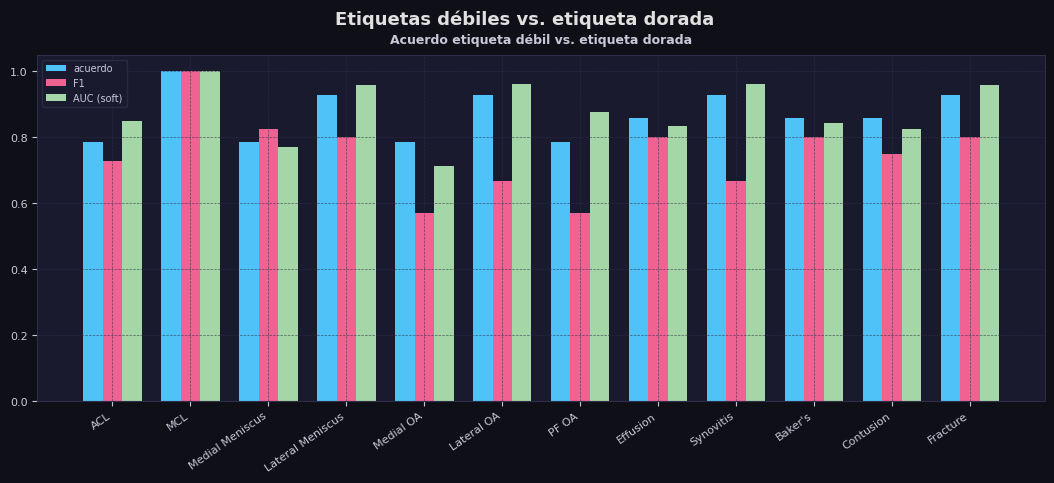

In [111]:
with timed("P1 · prepare + etiquetas débiles"):
    bundle = prepare(cfg, workers=cfg.num_workers or None)
display(bundle.agreement.round(3))
kplots.plot_agreement(bundle.agreement, "Etiquetas débiles vs. etiqueta dorada", KNEE_FIG / "weak_label_agreement.png")
plt.show()


| Línea | Qué hace |
|---|---|
| `state_dist` | Cuenta de estados (`pos_strong`…`unmentioned`) por etiqueta en todo el corpus: muestra qué hallazgos casi no se mencionan (sinovitis, fractura) |
| `fit_tfidf_labeler` | Entrena el etiquetador TF-IDF con las etiquetas de reglas de alta confianza y compara los tres etiquetadores en el dorado |

In [112]:
with timed("P1 · distribución de estados + TF-IDF"):
    state_cols = [f"state_{l}" for l in LABELS]
    state_dist = bundle.weak[state_cols].apply(pd.Series.value_counts).fillna(0).astype(int).T
    state_dist.index = LABELS
    labeler, labeler_report = fit_tfidf_labeler(bundle)
display(state_dist)
display(labeler_report[labeler_report["label"] == "MACRO"][["labeler", "agreement", "kappa", "precision", "recall", "f1", "auc_soft"]].round(3))


⏱ P1 · distribución de estados + TF-IDF: 0.55 s ✓


,ambiguous,neg,pos,pos_strong,unmentioned
ACL,7,24,0,32,9
MCL,0,48,6,5,13
Medial Meniscus,0,32,33,0,7
Lateral Meniscus,3,41,21,0,7
Medial OA,3,40,6,10,13
Lateral OA,13,37,0,15,7
PF OA,2,36,28,0,6
Effusion,0,29,0,26,17
Synovitis,0,47,19,0,6
Baker's,0,41,0,24,7


,labeler,agreement,kappa,precision,recall,f1,auc_soft
12,rules,0.869,0.653,0.678,0.897,0.748,0.879
25,tfidf,0.738,0.312,0.499,0.588,0.511,0.725
38,rules+tfidf,0.881,0.686,0.726,0.897,0.774,0.862


Evidencia textual que respalda cada etiqueta, para auditar el extractor por idioma:

In [113]:
sample = bundle.weak.merge(bundle.train[["StudyInstanceUID", bundle.report_col]], on="StudyInstanceUID")
for lab in ("ACL", "Effusion", "Fracture"):
    for r in sample[sample[f"state_{lab}"].isin(["pos", "pos_strong"])].head(2).itertuples():
        print(f"[{r.language}] {lab:9s} {getattr(r, f'state_{lab}'):10s} | {getattr(r, f'ev_{lab}')[:110]}")


[tr] ACL       pos_strong | on capraz bagda tam kat yirtik izlenmektedir.
[es] ACL       pos_strong | rotura completa del ligamento cruzado anterior.
[en] Effusion  pos_strong | large joint effusion.
[en] Effusion  pos_strong | large joint effusion.
[tr] Fracture  pos        | lateral tibia platosunda akut kirik.
[en] Fracture  pos        | acute fracture of the lateral tibial plateau.


## 4. Entregable 6 · desbalance de clases

| Línea | Qué hace |
|---|---|
| `bundle.targets(...)` | Targets suaves y pesos del subconjunto de entrenamiento con la estrategia de ruido de `cfg` |
| `prevalence_table` | Positivos y prevalencia por hallazgo (target ≥ 0.5); se añade la prevalencia en el dorado para contraste |
| mitigaciones | `oversample_rare` (sampler), pérdida focal y `pos_weight` acotado; las dos primeras se evalúan en la ablación |

⏱ P1 · prevalencia: 0.01 s ✓


,label,n_pos,prevalence,n_total,gold_prevalence
0,ACL,20,0.435,46,0.286
1,MCL,8,0.174,46,0.071
2,Medial Meniscus,21,0.457,46,0.571
3,Lateral Meniscus,17,0.370,46,0.143
4,Medial OA,10,0.217,46,0.214
5,Lateral OA,10,0.217,46,0.071
6,PF OA,16,0.348,46,0.143
7,Effusion,17,0.370,46,0.429
8,Synovitis,14,0.304,46,0.071
9,Baker's,15,0.326,46,0.357


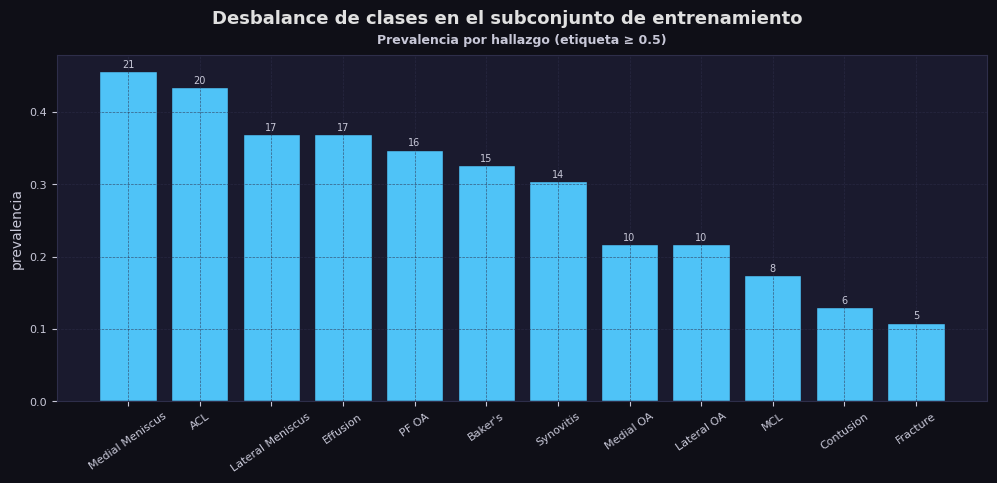

In [114]:
with timed("P1 · prevalencia"):
    p_train, w_train = bundle.targets(bundle.weak_train_ids, cfg)
    prevalence = prevalence_table(pd.DataFrame(p_train, columns=LABELS))
    prevalence["gold_prevalence"] = bundle.gold_targets().mean(axis=0)
display(prevalence.round(3))
kplots.plot_prevalence(prevalence, "Desbalance de clases en el subconjunto de entrenamiento", KNEE_FIG / "prevalence.png")
plt.show()


## 5. Entregable 2 · dos arquitecturas

| Línea | Qué hace |
|---|---|
| `cfg_scratch` / `cfg_transfer` | Mismo muestreo, misma cabeza y misma pérdida; solo cambia el codificador |
| `run_experiment` | Entrena con *early stopping* sobre el **holdout débil**, elige umbrales en el holdout y evalúa en dorado |
| `track=("gold", "holdout")` | Registra ambas curvas por época para la figura (cuesta una pasada extra por época; en la ablación se omite) |

In [115]:
cfg_scratch = dataclasses.replace(cfg, arch="scratch", loss="bce", noise_strategy="weighted", planes=("Sagittal",))
cfg_transfer = dataclasses.replace(cfg, arch="timm", loss="bce", noise_strategy="weighted", planes=("Sagittal",))
with timed("P1 · CNN desde cero"):
    exp_scratch = run_experiment(cfg_scratch, bundle, "scratch_cnn_2p5d", track=("gold", "holdout"))


[train] arch=scratch backbone=- params=1.28M loss=bce noise=weighted planes=('Sagittal',) monitor=holdout_auc device=cuda
  epoch=1 | train_loss=0.7319 | lr=0.0020 | time=0.1853 | gold_auc=0.5167 | holdout_auc=0.5716
  epoch=2 | train_loss=0.6393 | lr=0.0010 | time=0.1587 | gold_auc=0.7340 | holdout_auc=0.6718
  epoch=3 | train_loss=0.6276 | lr=0.0000 | time=0.1451 | gold_auc=0.7796 | holdout_auc=0.6975
[scratch_cnn_2p5d] gold macro AUC=0.7796 (best epoch 3)
⏱ P1 · CNN desde cero: 2.41 s ✓


[train] arch=timm backbone=resnet18 params=11.32M loss=bce noise=weighted planes=('Sagittal',) monitor=holdout_auc device=cuda
  epoch=1 | train_loss=0.7382 | lr=0.0020 | time=0.5639 | gold_auc=0.6409 | holdout_auc=0.6023
  epoch=2 | train_loss=0.6754 | lr=0.0010 | time=0.5546 | gold_auc=0.6853 | holdout_auc=0.5660
  epoch=3 | train_loss=0.6646 | lr=0.0000 | time=0.4016 | gold_auc=0.6883 | holdout_auc=0.5322
[transfer_resnet18] gold macro AUC=0.6409 (best epoch 1)
⏱ P1 · transfer resnet18: 4.47 s ✓


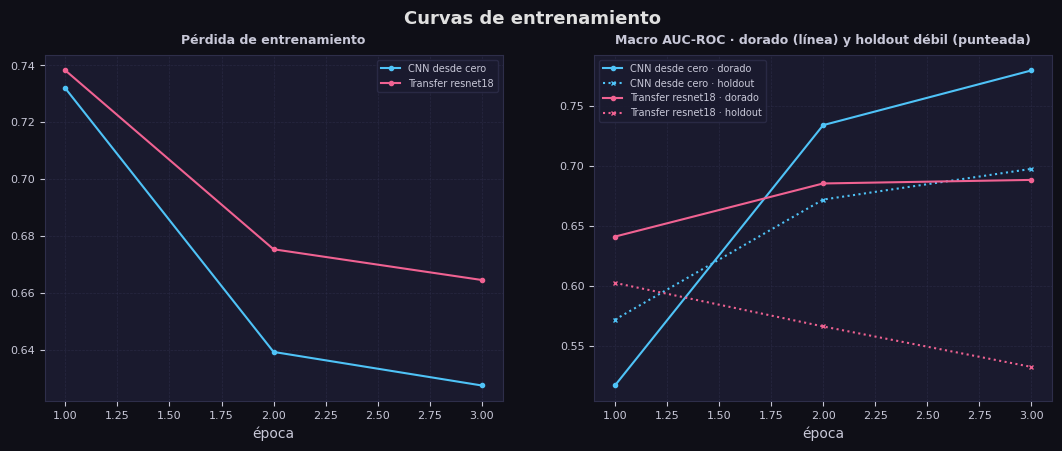

In [116]:
with timed(f"P1 · transfer {cfg.backbone}"):
    exp_transfer = run_experiment(cfg_transfer, bundle, f"transfer_{cfg.backbone}", track=("gold", "holdout"))
kplots.plot_history({"CNN desde cero": exp_scratch["history"], f"Transfer {cfg.backbone}": exp_transfer["history"]},
                    "Curvas de entrenamiento", KNEE_FIG / "history_main.png")
plt.show()


## 6. Entregable 3 · evaluación en el conjunto dorado

| Línea | Qué hace |
|---|---|
| `exp["report"]` | AUC, P, R, F1 por etiqueta con umbral elegido en holdout; `report_05` usa 0.5 fijo para mostrar el efecto de calibrar umbrales |
| `comparison` | Resumen de ambos modelos: macro AUC, macro F1 (dos umbrales) y parámetros |


CNN desde cero: macro AUC dorado = 0.7796 (mejor época 3 según holdout)


,label,n_pos,threshold,auc,precision,recall,f1
0,ACL,4,0.05,0.725,0.286,1.000,0.444
1,MCL,1,0.05,0.462,0.071,1.000,0.133
2,Medial Meniscus,8,0.05,0.823,0.571,1.000,0.727
3,Lateral Meniscus,2,0.05,1.000,0.143,1.000,0.250
4,Medial OA,3,0.05,0.894,0.214,1.000,0.353
5,Lateral OA,1,0.05,0.731,0.071,1.000,0.133
6,PF OA,2,0.05,0.646,0.143,1.000,0.250
7,Effusion,6,0.05,0.917,0.429,1.000,0.600
8,Synovitis,1,0.05,1.000,0.071,1.000,0.133
9,Baker's,5,0.05,0.800,0.357,1.000,0.526



Transfer resnet18: macro AUC dorado = 0.6409 (mejor época 1 según holdout)


,label,n_pos,threshold,auc,precision,recall,f1
0,ACL,4,0.05,0.350,0.286,1.000,0.444
1,MCL,1,0.05,0.462,0.071,1.000,0.133
2,Medial Meniscus,8,0.05,0.625,0.571,1.000,0.727
3,Lateral Meniscus,2,0.35,0.958,1.000,0.500,0.667
4,Medial OA,3,0.40,0.606,0.250,1.000,0.400
5,Lateral OA,1,0.60,1.000,0.250,1.000,0.400
6,PF OA,2,0.05,0.625,0.143,1.000,0.250
7,Effusion,6,0.60,0.875,0.800,0.667,0.727
8,Synovitis,1,0.35,0.615,0.111,1.000,0.200
9,Baker's,5,0.05,0.800,0.357,1.000,0.526


,modelo,macro_auc,macro_f1_umbral_holdout,macro_f1_umbral_0.5,parametros_M
0,CNN desde cero,0.7796,0.3330,0.0939,1.2758
1,Transfer resnet18,0.6409,0.4285,0.1822,11.3151


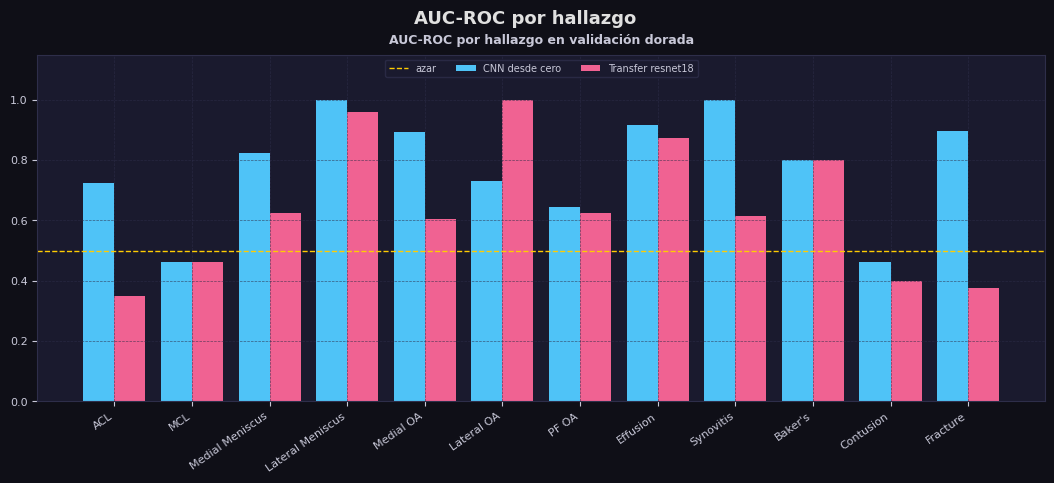

In [117]:
for name, exp in (("CNN desde cero", exp_scratch), (f"Transfer {cfg.backbone}", exp_transfer)):
    print(f"\n{name}: macro AUC dorado = {exp['gold_macro_auc']:.4f} (mejor época {exp['best_epoch']} según {exp['monitor']})")
    display(exp["report"].round(3))
comparison = pd.DataFrame({
    "modelo": ["CNN desde cero", f"Transfer {cfg.backbone}"],
    "macro_auc": [exp_scratch["gold_macro_auc"], exp_transfer["gold_macro_auc"]],
    "macro_f1_umbral_holdout": [exp_scratch["report"].iloc[-1]["f1"], exp_transfer["report"].iloc[-1]["f1"]],
    "macro_f1_umbral_0.5": [exp_scratch["report_05"].iloc[-1]["f1"], exp_transfer["report_05"].iloc[-1]["f1"]],
    "parametros_M": [count_params(exp_scratch["model"]) / 1e6, count_params(exp_transfer["model"]) / 1e6],
})
display(comparison.round(4))
kplots.plot_per_label_auc({"CNN desde cero": exp_scratch["report"], f"Transfer {cfg.backbone}": exp_transfer["report"]},
                          "AUC-ROC por hallazgo", KNEE_FIG / "per_label_auc_main.png")
plt.show()


## 7. Entregable 4 · estudio de ablación

Cada experimento difiere de `transfer_bce_weighted` en **un solo factor**. Se reparte en tres celdas de dos experimentos para respetar el presupuesto de tiempo; en demo usa `ABLATION_EPOCHS` épocas y solo evalúa el holdout por época (`track=("holdout",)`).

| Celda | Factores |
|---|---|
| A | Pérdida focal vs. BCE · ruido: solo alta confianza |
| B | Ruido: sin ponderar · plano coronal |
| C | Backbone poco profundo (`resnet18`) · sin sobre-muestreo |

In [118]:
ABLATION_EPOCHS = 2 if KNEE_MODE == "mock" else cfg.epochs
base_tl = {"arch": "timm", "backbone": cfg.backbone, "loss": "bce", "noise_strategy": "weighted", "planes": ("Sagittal",), "epochs": ABLATION_EPOCHS}
ablation_tables, ablation_results = [], {"scratch_cnn_2p5d": exp_scratch, "transfer_bce_weighted": exp_transfer}
with timed("P1 · ablación A (focal, alta confianza)"):
    t, r = run_ablation(cfg, bundle, {"transfer_focal_weighted": {**base_tl, "loss": "focal"},
                                      "transfer_bce_highconf": {**base_tl, "noise_strategy": "high_conf"}}, verbose=False, track=("holdout",))
ablation_tables.append(t); ablation_results.update(r)
display(t.round(4))


⏱ P1 · ablación A (focal, alta confianza): 7.51 s ✓


,name,arch,backbone,loss,noise_strategy,planes,epochs,gold_macro_auc,best_epoch,gold_f1_macro
0,transfer_focal_weighted,timm,resnet18,focal,weighted,"(Sagittal,)",2,0.6505,2,0.3390
1,transfer_bce_highconf,timm,resnet18,bce,high_conf,"(Sagittal,)",2,0.4880,2,0.3523


In [119]:
with timed("P1 · ablación B (sin ponderar, coronal)"):
    t, r = run_ablation(cfg, bundle, {"transfer_bce_unweighted": {**base_tl, "noise_strategy": "all"},
                                      "transfer_bce_coronal": {**base_tl, "planes": ("Coronal",)}}, verbose=False, track=("holdout",))
ablation_tables.append(t); ablation_results.update(r)
display(t.round(4))


⏱ P1 · ablación B (sin ponderar, coronal): 6.37 s ✓


,name,arch,backbone,loss,noise_strategy,planes,epochs,gold_macro_auc,best_epoch,gold_f1_macro
0,transfer_bce_coronal,timm,resnet18,bce,weighted,"(Coronal,)",2,0.7018,2,0.2744
1,transfer_bce_unweighted,timm,resnet18,bce,all,"(Sagittal,)",2,0.4616,2,0.2710


In [120]:
with timed("P1 · ablación C (resnet18, sin sobre-muestreo)"):
    t, r = run_ablation(cfg, bundle, {"transfer_bce_shallow": {**base_tl, "backbone": "resnet18"},
                                      "transfer_bce_no_oversample": {**base_tl, "oversample_rare": False}}, verbose=False, track=("holdout",))
ablation_tables.append(t); ablation_results.update(r)
display(t.round(4))


⏱ P1 · ablación C (resnet18, sin sobre-muestreo): 5.67 s ✓


,name,arch,backbone,loss,noise_strategy,planes,epochs,gold_macro_auc,best_epoch,gold_f1_macro,oversample_rare
0,transfer_bce_no_oversample,timm,resnet18,bce,weighted,"(Sagittal,)",2,0.6399,1,0.4028,False
1,transfer_bce_shallow,timm,resnet18,bce,weighted,"(Sagittal,)",2,0.5331,2,0.3180,NaN


| Línea | Qué hace |
|---|---|
| `ablation_table` | Une las tres tablas con los dos modelos principales y ordena por macro AUC dorado |
| `plot_ablation` / `plot_per_label_auc` | Barras horizontales del macro AUC y AUC por hallazgo para todas las configuraciones |

,name,arch,backbone,loss,noise_strategy,planes,epochs,gold_macro_auc,best_epoch,gold_f1_macro,oversample_rare
0,scratch_cnn_2p5d,scratch,NaN,bce,weighted,"(Sagittal,)",NaN,0.7796,3,0.3330,NaN
1,transfer_bce_coronal,timm,resnet18,bce,weighted,"(Coronal,)",2.0,0.7018,2,0.2744,NaN
2,transfer_focal_weighted,timm,resnet18,focal,weighted,"(Sagittal,)",2.0,0.6505,2,0.3390,NaN
3,transfer_bce_weighted,timm,resnet18,bce,weighted,"(Sagittal,)",NaN,0.6409,1,0.4285,NaN
4,transfer_bce_no_oversample,timm,resnet18,bce,weighted,"(Sagittal,)",2.0,0.6399,1,0.4028,False
5,transfer_bce_shallow,timm,resnet18,bce,weighted,"(Sagittal,)",2.0,0.5331,2,0.3180,NaN
6,transfer_bce_highconf,timm,resnet18,bce,high_conf,"(Sagittal,)",2.0,0.4880,2,0.3523,NaN
7,transfer_bce_unweighted,timm,resnet18,bce,all,"(Sagittal,)",2.0,0.4616,2,0.2710,NaN


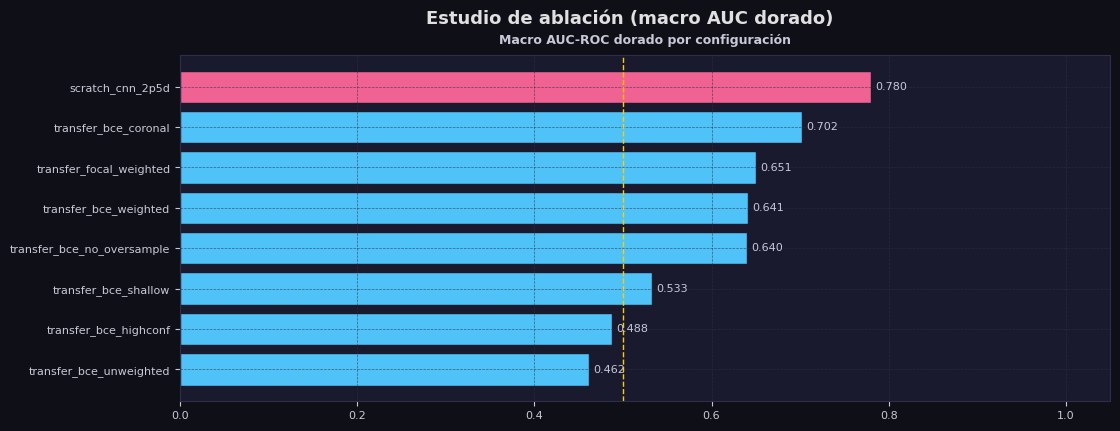

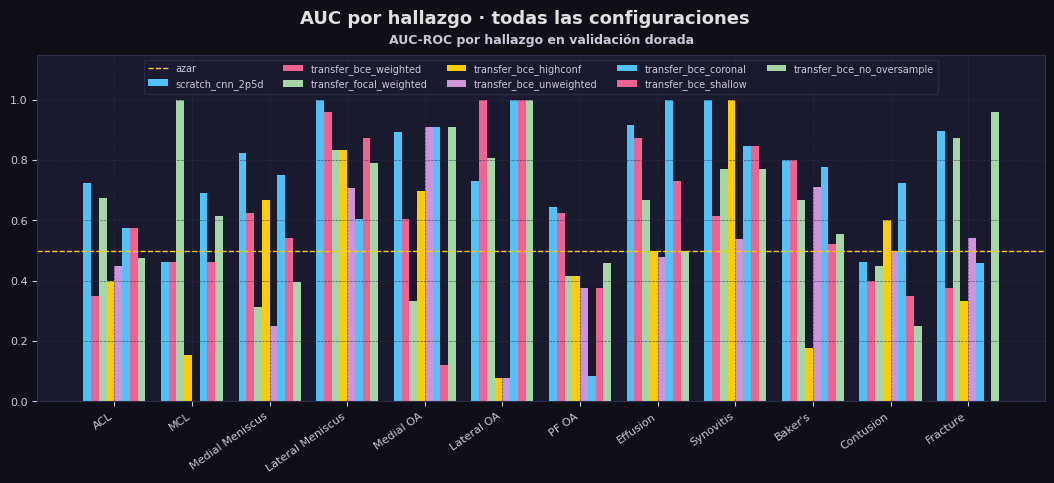

In [121]:
main_rows = pd.DataFrame([
    {"name": "scratch_cnn_2p5d", "arch": "scratch", "loss": "bce", "noise_strategy": "weighted", "planes": ("Sagittal",),
     "gold_macro_auc": exp_scratch["gold_macro_auc"], "best_epoch": exp_scratch["best_epoch"], "gold_f1_macro": exp_scratch["report"].iloc[-1]["f1"]},
    {"name": "transfer_bce_weighted", **{k: v for k, v in base_tl.items() if k != "epochs"},
     "gold_macro_auc": exp_transfer["gold_macro_auc"], "best_epoch": exp_transfer["best_epoch"], "gold_f1_macro": exp_transfer["report"].iloc[-1]["f1"]},
])
ablation_table = pd.concat(ablation_tables + [main_rows], ignore_index=True).sort_values("gold_macro_auc", ascending=False).reset_index(drop=True)
ablation_table.to_csv(cfg.work_dir / "ablation.csv", index=False)
display(ablation_table.round(4))
kplots.plot_ablation(ablation_table, "Estudio de ablación (macro AUC dorado)", KNEE_FIG / "ablation.png")
kplots.plot_per_label_auc({k: v["report"] for k, v in ablation_results.items()}, "AUC por hallazgo · todas las configuraciones", KNEE_FIG / "per_label_auc_ablation.png")
plt.show()


## 8. Entregable 5 · Grad-CAM

| Línea | Qué hace |
|---|---|
| `best_name` / `best_cfg` | Reconstruye la configuración del mejor experimento (planos, arquitectura) para muestrear el estudio igual que en entrenamiento |
| `REGIONS` | Regiones esperadas en coordenadas normalizadas del plano sagital: LCA intercondíleo central, menisco medial en la interlínea posterior, derrame en el receso suprarrotuliano |
| `gradcam_study` | Mapa por corte y pesos de atención; `plot_gradcam` muestra los cortes más atendidos |
| `cam_stats` | Fracción de energía del mapa dentro de la región esperada (heurística de plausibilidad, no segmentación) |

⏱ P1 · Grad-CAM: 2.30 s ✓


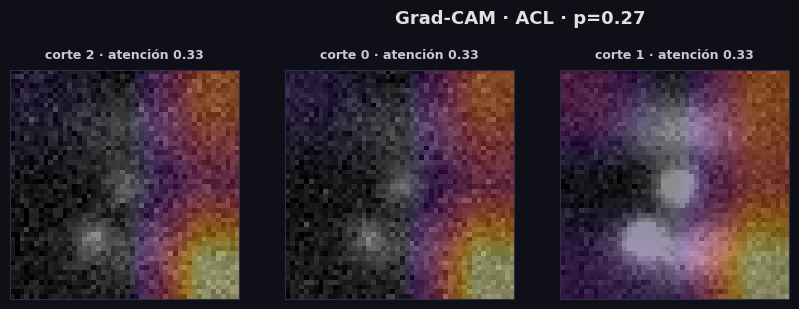

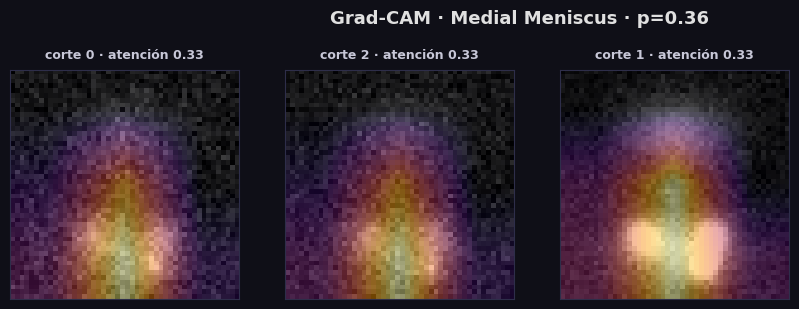

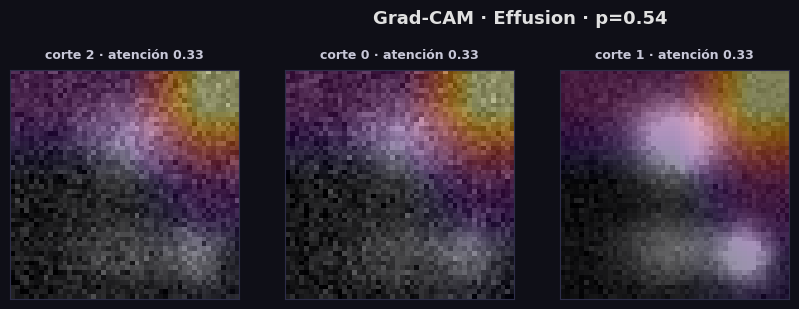

,label,study,prob,top_slice,energy_in_expected_region
0,ACL,1.2.826.0.1.9999.1,0.266,2,0.022
1,Medial Meniscus,1.2.826.0.1.9999.0,0.361,0,0.194
2,Effusion,1.2.826.0.1.9999.4,0.539,2,0.118


In [122]:
with timed("P1 · Grad-CAM"):
    best_name = ablation_table.iloc[0]["name"]
    best_exp = ablation_results[best_name]
    best_cfg = dataclasses.replace(cfg, **{k: best_exp["config"][k] for k in ("arch", "backbone", "loss", "noise_strategy", "oversample_rare")},
                                   planes=tuple(best_exp["config"]["planes"]))
    model = best_exp["model"].cpu().float()
    gold_y = bundle.gold_targets()
    REGIONS = {"ACL": (0.35, 0.65, 0.35, 0.65), "Medial Meniscus": (0.55, 0.80, 0.45, 0.80), "Effusion": (0.10, 0.45, 0.15, 0.50)}
    cam_rows = []
    for lab, region in REGIONS.items():
        j = LABELS.index(lab)
        candidates = [i for i in range(len(bundle.gold_ids)) if gold_y[i, j] >= 0.5]
        if not candidates:
            continue
        i = candidates[0]
        x = KneeStudyDataset(best_cfg, [bundle.gold_ids[i]], gold_y[i:i + 1], np.ones((1, len(LABELS))),
                             train=False, imagenet_norm=best_cfg.arch != "scratch")[0]["x"]
        g = gradcam_study(model, x, lab)
        kplots.plot_gradcam(x.numpy(), g["cam"], g["attention"], lab, g["prob"], path=KNEE_FIG / f"gradcam_{lab.replace(' ', '_')}.png")
        cam_rows.append({"label": lab, "study": bundle.gold_ids[i], "prob": g["prob"], "top_slice": g["top_slice"],
                         "energy_in_expected_region": cam_stats(g["cam"][g["top_slice"]], region)})
plt.show()
display(pd.DataFrame(cam_rows).round(3))


## Entregable 7 · sesgo geográfico y lingüístico

| Línea | Qué hace |
|---|---|
| `bundle.agreement_lang` | Acuerdo celda a celda y tasa de sobre-llamada del extractor por idioma, en los estudios dorados |

,language,n_studies,cell_agreement,overcall_rate,undercall_rate
0,en,8,0.885,0.062,0.052
1,tr,4,0.896,0.083,0.021
2,de,1,0.833,0.167,0.000
3,es,1,0.667,0.333,0.000


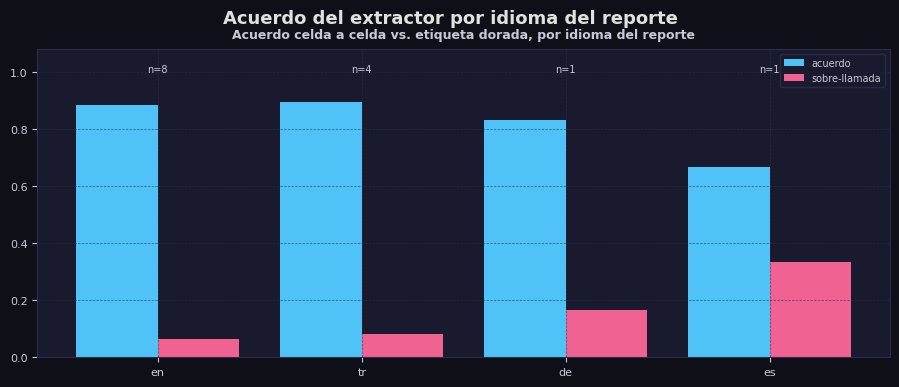

In [123]:
display(bundle.agreement_lang.round(3))
kplots.plot_language_agreement(bundle.agreement_lang, "Acuerdo del extractor por idioma del reporte", KNEE_FIG / "language_agreement.png")
plt.show()


**Discusión.** El extractor cubre doce idiomas con léxicos auditados a mano, no con un corpus anotado por idioma, así que su cobertura es asimétrica: la negación posterior del turco, la ausencia de diacríticos en cirílico y griego y la variabilidad terminológica de los compartimentos de artrosis se verificaron con ejemplos, no con estadística. Un idioma con menor cobertura produce más celdas `unmentioned` o `ambiguous`, es decir, targets cercanos a 0 con peso bajo: el clasificador de imágenes aprende que los estudios de ese centro son "más sanos" y el sesgo de etiqueta se convierte en sesgo de imagen, porque el idioma está correlacionado con el centro, el escáner y el protocolo. En un despliegue clínico esto obliga a (i) validar el rendimiento estratificado por centro e idioma antes de liberar el modelo, (ii) exigir un mínimo de estudios con etiqueta verificada por idioma para calibrar el extractor y (iii) monitorizar la deriva al incorporar nuevos centros, porque un macro AUC global puede ocultar un rendimiento cercano al azar en un subgrupo. Con 58 estudios dorados, además, el intervalo del macro AUC es de ±0.03 o más: las diferencias pequeñas de la ablación deben leerse como no concluyentes.

---
## 9. Pregunta 2 · Mapeo de inundaciones con Sentinel-1 (U-Net)

### Diseño experimental

| Decisión | Elección | Justificación |
|---|---|---|
| Entrada | Bandas SAR VV y VH en dB, normalización oficial del dataset | Mínimo exigido; VH separa mejor agua de tierra, VV capta doble rebote |
| Arquitectura | U-Net propia en PyTorch, 4 niveles, 32 canales base, `concat`/`attention`/`none` en los saltos | Entregable 1; la variante de salto es una decisión arquitectónica de la ablación |
| Supervisión | Chips dorados (446) solos vs. dorados + débiles (Otsu sobre VH) con **peso 0.5** en la pérdida | Entregable 2(a); el peso evita que 4 385 chips ruidosos dominen a 446 limpios |
| Pérdida | BCE vs. Dice vs. combinada (0.5/0.5) | Entregable 2(b); Dice es robusta al desbalance agua/tierra |
| Umbral | Elegido en validación maximizando IoU, aplicado a test y Bolivia | Nunca se toca el test para decidir |
| Generalización | Train/valid/test oficiales excluyen Bolivia; los débiles también; Bolivia solo se evalúa | Entregable 4, partición oficial de los autores |
| Métricas | IoU por píxel y por chip, F1, P, R, omisión, comisión, matriz de confusión | Entregable 3 y métrica de referencia del paper |
| Fallos SAR | Taxonomía por retrodispersión VV (sombra, suelo húmedo, doble rebote) con ejemplos visuales; en demo, auditoría contra máscaras de mecanismo | Entregable 5 |

**Datos reales.** El dataset vive en `gs://sen1floods11` (~14 GB completo; la parte etiquetada a mano ~1 GB). En Colab:
```bash
gsutil -m rsync -r gs://sen1floods11/v1.1/splits data/sen1floods11/v1.1/splits
gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled data/sen1floods11/v1.1/data/flood_events/HandLabeled
gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/WeaklyLabeled data/sen1floods11/v1.1/data/flood_events/WeaklyLabeled
```
y `FLOOD_DATA_ROOT=data/sen1floods11`. Sin datos, el notebook usa el fixture sintético.

### 9.1 `floods/config.py`


| Línea / bloque | Qué hace |
|---|---|
| `EVENTS`, `TEST_EVENT` | Los 11 eventos del dataset; `Bolivia` es el conjunto de prueba geográficamente independiente definido por los autores |
| `SAR_MEAN`, `SAR_STD`, `SAR_CLIP` | Normalización oficial de Sen1Floods11: recorte a `[-50, 1]` dB, escala a `[0,1]` y estandarización con media/desvío publicados |
| `IGNORE = -1` | Codificación "sin dato" de `LabelHand`; se excluye de pérdida y métricas |
| `FloodConfig` | `crop` (recorte de entrenamiento, 256 en real), `base_channels`/`depth`/`skip_mode` (arquitectura), `loss` (`bce`/`dice`/`combo`), `use_weak` + `weak_weight` (peso de los chips débiles en la pérdida), `max_weak`, hiperparámetros y parámetros del modo demo |
| `v11`, `hand_dir`, `weak_dir`, `split_dir` | Rutas que replican la estructura del bucket `gs://sen1floods11/v1.1/...` |

In [124]:
%%writefile floods/config.py
from __future__ import annotations

import os
from dataclasses import asdict, dataclass, field
from pathlib import Path

EVENTS = ("Bolivia", "Ghana", "India", "Mekong", "Nigeria", "Pakistan", "Paraguay", "Somalia", "Spain", "Sri-Lanka", "USA")
TEST_EVENT = "Bolivia"
SAR_MEAN = (0.6851, 0.5235)
SAR_STD = (0.0820, 0.1102)
SAR_CLIP = (-50.0, 1.0)
IGNORE = -1


def detect_data_root() -> Path:
    for cand in ("/kaggle/input/sen1floods11", os.environ.get("FLOOD_DATA_ROOT", ""), "data/sen1floods11"):
        if cand and Path(cand).exists():
            return Path(cand)
    return Path("data/sen1floods11")


@dataclass
class FloodConfig:
    data_root: Path = field(default_factory=detect_data_root)
    work_dir: Path = Path("work_floods")
    seed: int = 42

    in_channels: int = 2
    crop: int = 256
    base_channels: int = 32
    depth: int = 4
    skip_mode: str = "concat"
    bilinear: bool = True

    loss: str = "combo"
    dice_weight: float = 0.5
    use_weak: bool = False
    weak_weight: float = 0.5
    max_weak: int = 2000

    epochs: int = 30
    batch_size: int = 16
    lr: float = 1e-3
    weight_decay: float = 1e-4
    patience: int = 6
    monitor: str = "valid_iou"
    amp: bool = True
    num_workers: int = 2
    threshold: float = 0.5

    mock: bool = False
    mock_gold: int = 120
    mock_weak: int = 240
    mock_size: int = 64

    def __post_init__(self) -> None:
        self.data_root = Path(self.data_root)
        self.work_dir = Path(self.work_dir)
        self.work_dir.mkdir(parents=True, exist_ok=True)

    @property
    def v11(self) -> Path:
        return self.data_root / "v1.1" if (self.data_root / "v1.1").exists() else self.data_root

    @property
    def hand_dir(self) -> Path:
        return self.v11 / "data" / "flood_events" / "HandLabeled"

    @property
    def weak_dir(self) -> Path:
        return self.v11 / "data" / "flood_events" / "WeaklyLabeled"

    @property
    def split_dir(self) -> Path:
        return self.v11 / "splits" / "flood_handlabeled"

    def to_dict(self) -> dict:
        d = asdict(self)
        d["data_root"], d["work_dir"] = str(self.data_root), str(self.work_dir)
        return d


Overwriting floods/config.py


### 9.2 `floods/data.py` · cargador Sen1Floods11


| Línea / bloque | Qué hace |
|---|---|
| `read_tif()` | Lee GeoTIFF con `tifffile` (o `rasterio` si está instalado) y devuelve `[bandas, H, W]` |
| `normalize_sar()` | `NaN → -50 dB`, recorte, escala y estandarización por banda (VV, VH) |
| `Chip` | Registro con id, evento, partición, fuente (`hand`/`weak`), rutas y **peso** en la pérdida |
| `load_hand_splits()` | Lee los 4 CSV oficiales sin cabecera (`*_S1Hand.tif,*_LabelHand.tif`) y resuelve rutas |
| `load_weak()` | Empareja `S1Weak` con `S1OtsuLabelWeak` por nombre y **excluye Bolivia** para no contaminar el test geográfico |
| `FloodChips.__getitem__` | Recorte aleatorio (entrenamiento) o central (evaluación), rotaciones de 90° y volteo; cualquier valor distinto de 0/1 pasa a `IGNORE` |
| `label_stats()` | Fracción de agua y de sin-dato del conjunto |

In [125]:
%%writefile floods/data.py
from __future__ import annotations

import csv
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

from .config import IGNORE, SAR_CLIP, SAR_MEAN, SAR_STD, TEST_EVENT, FloodConfig

SPLIT_FILES = {"train": "flood_train_data.csv", "valid": "flood_valid_data.csv",
               "test": "flood_test_data.csv", "bolivia": "flood_bolivia_data.csv"}


def read_tif(path: Path) -> np.ndarray:
    try:
        import tifffile

        arr = tifffile.imread(path)
    except ImportError:
        import rasterio

        with rasterio.open(path) as src:
            return src.read()
    if arr.ndim == 2:
        return arr[None]
    return np.moveaxis(arr, -1, 0) if arr.shape[0] > 16 else arr


def normalize_sar(x: np.ndarray) -> np.ndarray:
    x = np.nan_to_num(x.astype(np.float32), nan=SAR_CLIP[0])
    x = (np.clip(x, *SAR_CLIP) - SAR_CLIP[0]) / (SAR_CLIP[1] - SAR_CLIP[0])
    mean = np.asarray(SAR_MEAN, dtype=np.float32)[:, None, None]
    std = np.asarray(SAR_STD, dtype=np.float32)[:, None, None]
    return (x - mean) / std


@dataclass
class Chip:
    chip_id: str
    event: str
    split: str
    source: str
    s1_path: Path
    label_path: Path
    weight: float = 1.0


def _parse_name(name: str) -> tuple[str, str]:
    event, chip_id = name.split("_")[:2]
    return event, chip_id


def load_hand_splits(cfg: FloodConfig) -> list[Chip]:
    chips: list[Chip] = []
    for split, fname in SPLIT_FILES.items():
        path = cfg.split_dir / fname
        if not path.exists():
            continue
        with open(path) as f:
            for row in csv.reader(f):
                if len(row) < 2 or row[0].lower().startswith("s1"):
                    continue
                event, chip_id = _parse_name(row[0])
                chips.append(Chip(chip_id, event, split, "hand", cfg.hand_dir / "S1Hand" / row[0].strip(),
                                  cfg.hand_dir / "LabelHand" / row[1].strip()))
    return chips


def load_weak(cfg: FloodConfig, exclude_events: tuple[str, ...] = (TEST_EVENT,)) -> list[Chip]:
    s1_dir, lab_dir = cfg.weak_dir / "S1Weak", cfg.weak_dir / "S1OtsuLabelWeak"
    if not s1_dir.exists():
        return []
    chips = []
    for p in sorted(s1_dir.glob("*_S1Weak.tif")):
        event, chip_id = _parse_name(p.name)
        if event in exclude_events:
            continue
        lab = lab_dir / p.name.replace("_S1Weak", "_S1OtsuLabelWeak")
        if lab.exists():
            chips.append(Chip(chip_id, event, "weak", "weak", p, lab, cfg.weak_weight))
    return chips[: cfg.max_weak]


def chips_table(chips: list[Chip]) -> pd.DataFrame:
    df = pd.DataFrame([{"chip_id": c.chip_id, "event": c.event, "split": c.split, "source": c.source} for c in chips])
    return df.groupby(["split", "source", "event"]).size().unstack(fill_value=0)


class FloodChips(Dataset):
    def __init__(self, chips: list[Chip], crop: int | None, train: bool, in_memory: bool = True, seed: int = 0) -> None:
        self.chips, self.crop, self.train = chips, crop, train
        self.rng = np.random.default_rng(seed)
        self.cache: dict[int, tuple[np.ndarray, np.ndarray]] = {}
        if in_memory:
            for i in range(len(chips)):
                self.cache[i] = self._load(i)

    def _load(self, i: int) -> tuple[np.ndarray, np.ndarray]:
        c = self.chips[i]
        x = normalize_sar(read_tif(c.s1_path)[:2])
        y = read_tif(c.label_path)[0].astype(np.int64)
        y[(y != 0) & (y != 1)] = IGNORE
        return x, y

    def __len__(self) -> int:
        return len(self.chips)

    def __getitem__(self, i: int) -> dict:
        x, y = self.cache[i] if i in self.cache else self._load(i)
        if self.crop and x.shape[-1] > self.crop:
            if self.train:
                r, c = self.rng.integers(0, x.shape[-2] - self.crop + 1), self.rng.integers(0, x.shape[-1] - self.crop + 1)
            else:
                r, c = (x.shape[-2] - self.crop) // 2, (x.shape[-1] - self.crop) // 2
            x, y = x[:, r:r + self.crop, c:c + self.crop], y[r:r + self.crop, c:c + self.crop]
        if self.train:
            k = int(self.rng.integers(0, 4))
            x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k)
            if self.rng.random() < 0.5:
                x, y = x[:, :, ::-1], y[:, ::-1]
        return {"x": torch.from_numpy(np.ascontiguousarray(x)), "y": torch.from_numpy(np.ascontiguousarray(y)),
                "w": torch.tensor(self.chips[i].weight, dtype=torch.float32), "id": f"{self.chips[i].event}_{self.chips[i].chip_id}"}


def label_stats(ds: FloodChips) -> dict:
    tot = water = nodata = 0
    for i in range(len(ds)):
        _, y = ds.cache[i] if i in ds.cache else ds._load(i)
        tot += y.size
        water += int((y == 1).sum())
        nodata += int((y == IGNORE).sum())
    valid = tot - nodata
    return {"chips": len(ds), "water_fraction": water / max(valid, 1), "nodata_fraction": nodata / max(tot, 1)}


Overwriting floods/data.py


### 9.3 `floods/mock.py` · SAR sintético con física de errores


| Línea / bloque | Qué hace |
|---|---|
| `_smooth_field()` | Campo aleatorio suave por interpolación bilineal de ruido grueso: actúa como DEM |
| `synth_chip()` | Agua = DEM bajo un nivel de inundación + río sinusoidal. **Sombra de radar**: pendientes que miran en contra del haz, muy oscuras (`-22.5 dB`) pero etiqueta tierra. **Doble rebote**: parches urbanos inundados, muy brillantes (`-1.5 dB`) pero etiqueta agua. **Suelo húmedo**: anillo alrededor del agua a `-14.5 dB`, etiqueta tierra |
| `_speckle()` | Ruido multiplicativo Gamma de 4 *looks* en intensidad lineal, luego vuelta a dB |
| `otsu_threshold()` | Umbral de Otsu sobre VH: reproduce exactamente cómo se generó `S1OtsuLabelWeak` en el dataset real, por lo que la etiqueta débil hereda sombras como agua y pierde el doble rebote |
| `_EVENT_STYLE[TEST_EVENT]` | Bolivia recibe más suelo húmedo, más urbano inundado y un desplazamiento de +2 dB: simula un cambio de dominio (ángulo de incidencia, cobertura) |
| `make_mock_sen1floods11()` | Escribe la misma jerarquía de carpetas y CSV que el bucket real, más `mock_meta/*.npz` con las máscaras de mecanismo para auditar los fallos |

In [126]:
%%writefile floods/mock.py
from __future__ import annotations

import csv
from pathlib import Path

import numpy as np
import tifffile

from .config import EVENTS, IGNORE, TEST_EVENT

_EVENT_STYLE = {e: {"vv_shift": 0.0, "wet": 0.25, "urban": 0.25, "shadow": 0.6} for e in EVENTS}
_EVENT_STYLE[TEST_EVENT] = {"vv_shift": 2.0, "wet": 0.55, "urban": 0.5, "shadow": 1.2}
_EVENT_STYLE["Spain"] = {"vv_shift": -1.0, "wet": 0.15, "urban": 0.45, "shadow": 0.4}
_EVENT_STYLE["Mekong"] = {"vv_shift": 0.5, "wet": 0.4, "urban": 0.2, "shadow": 0.3}


def _smooth_field(rng: np.random.Generator, n: int, scale: int) -> np.ndarray:
    coarse = rng.normal(size=(scale, scale))
    yy, xx = np.linspace(0, scale - 1, n), np.linspace(0, scale - 1, n)
    iy, ix = np.floor(yy).astype(int), np.floor(xx).astype(int)
    fy, fx = (yy - iy)[:, None], (xx - ix)[None, :]
    iy1, ix1 = np.minimum(iy + 1, scale - 1), np.minimum(ix + 1, scale - 1)
    top = coarse[iy][:, ix] * (1 - fx) + coarse[iy][:, ix1] * fx
    bot = coarse[iy1][:, ix] * (1 - fx) + coarse[iy1][:, ix1] * fx
    return top * (1 - fy) + bot * fy


def _dilate(mask: np.ndarray, r: int) -> np.ndarray:
    out = mask.copy()
    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            if dy * dy + dx * dx <= r * r:
                out |= np.roll(np.roll(mask, dy, 0), dx, 1)
    return out


def _speckle(db: np.ndarray, rng: np.random.Generator, looks: int = 4) -> np.ndarray:
    lin = 10 ** (db / 10) * rng.gamma(looks, 1.0 / looks, db.shape)
    return 10 * np.log10(np.maximum(lin, 1e-6))


def otsu_threshold(values: np.ndarray, bins: int = 256) -> float:
    hist, edges = np.histogram(values, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(hist)
    w1 = w0[-1] - w0
    m0 = np.cumsum(hist * centers) / np.maximum(w0, 1)
    m1 = (np.cumsum((hist * centers)[::-1])[::-1] / np.maximum(w1, 1))
    between = w0[:-1] * w1[:-1] * (m0[:-1] - m1[1:]) ** 2
    return float(centers[int(np.argmax(between))])


def synth_chip(rng: np.random.Generator, n: int, style: dict) -> dict[str, np.ndarray]:
    dem = _smooth_field(rng, n, 6) + 0.4 * _smooth_field(rng, n, 14)
    dem = (dem - dem.min()) / (dem.max() - dem.min() + 1e-6)
    level = rng.uniform(0.2, 0.45)
    water = dem < level
    yy, xx = np.mgrid[0:n, 0:n] / n
    river = np.abs(yy - (0.5 + 0.25 * np.sin(2 * np.pi * xx * rng.uniform(0.8, 1.6) + rng.uniform(0, 6)))) < rng.uniform(0.02, 0.05)
    water |= river & (rng.random() < 0.7)

    dz = np.gradient(dem, axis=1)
    shadow = (dz < np.quantile(dz, 0.04 * style["shadow"])) & ~water
    wet = _dilate(water, int(2 + 3 * style["wet"])) & ~water & (rng.random((n, n)) < style["wet"])
    urban = np.zeros_like(water)
    for _ in range(int(rng.integers(1, 4))):
        if rng.random() < style["urban"]:
            r0, c0 = rng.integers(0, n - n // 5, size=2)
            h, w = rng.integers(n // 10, n // 5, size=2)
            urban[r0:r0 + h, c0:c0 + w] = True
    flooded_urban = urban & water
    vv = np.where(water, -20.0, -9.0 + 2.5 * (dem - 0.5) + style["vv_shift"])
    vv = np.where(wet, -14.5, vv)
    vv = np.where(shadow, -22.5, vv)
    vv = np.where(urban & ~water, -4.0, vv)
    vv = np.where(flooded_urban, -1.5, vv)
    vh = vv - 7.0 + np.where(water, -0.5, 0.0) + rng.normal(0, 0.6, (n, n))
    vv, vh = _speckle(vv, rng), _speckle(vh, rng)
    label = water.astype(np.int16)
    nodata = np.zeros((n, n), dtype=bool)
    if rng.random() < 0.3:
        wdt = int(rng.integers(n // 16, n // 6))
        side = int(rng.integers(0, 4))
        sl = (slice(0, wdt), slice(None)) if side == 0 else (slice(-wdt, None), slice(None)) if side == 1 \
            else (slice(None), slice(0, wdt)) if side == 2 else (slice(None), slice(-wdt, None))
        nodata[sl] = True
    label[nodata] = IGNORE
    vv[nodata], vh[nodata] = np.nan, np.nan
    valid = ~nodata
    weak = np.full((n, n), IGNORE, dtype=np.int16)
    thr = otsu_threshold(vh[valid])
    weak[valid] = (vh[valid] < thr).astype(np.int16)
    return {"s1": np.stack([vv, vh]).astype(np.float32), "label": label, "weak": weak,
            "shadow": shadow & valid, "double_bounce": flooded_urban & valid, "wet_soil": wet & valid}


def make_mock_sen1floods11(root: Path, n_gold: int = 120, n_weak: int = 240, size: int = 64, seed: int = 0) -> None:
    rng = np.random.default_rng(seed)
    root = Path(root)
    hand = root / "v1.1" / "data" / "flood_events" / "HandLabeled"
    weak = root / "v1.1" / "data" / "flood_events" / "WeaklyLabeled"
    splits = root / "v1.1" / "splits" / "flood_handlabeled"
    for d in (hand / "S1Hand", hand / "LabelHand", weak / "S1Weak", weak / "S1OtsuLabelWeak", splits, root / "mock_meta"):
        d.mkdir(parents=True, exist_ok=True)
    rows: dict[str, list[tuple[str, str]]] = {"train": [], "valid": [], "test": [], "bolivia": []}
    events = list(EVENTS)
    for i in range(n_gold):
        event = TEST_EVENT if i % 6 == 0 else events[1 + (i % (len(events) - 1))]
        chip = synth_chip(rng, size, _EVENT_STYLE[event])
        cid = f"{100000 + i}"
        s1_name, lab_name = f"{event}_{cid}_S1Hand.tif", f"{event}_{cid}_LabelHand.tif"
        tifffile.imwrite(hand / "S1Hand" / s1_name, chip["s1"])
        tifffile.imwrite(hand / "LabelHand" / lab_name, chip["label"])
        np.savez_compressed(root / "mock_meta" / f"{event}_{cid}.npz", shadow=chip["shadow"],
                            double_bounce=chip["double_bounce"], wet_soil=chip["wet_soil"])
        u = rng.random()
        split = "bolivia" if event == TEST_EVENT else ("train" if u < 0.6 else "valid" if u < 0.8 else "test")
        rows[split].append((s1_name, lab_name))
    for i in range(n_weak):
        event = events[i % len(events)]
        chip = synth_chip(rng, size, _EVENT_STYLE[event])
        cid = f"{200000 + i}"
        tifffile.imwrite(weak / "S1Weak" / f"{event}_{cid}_S1Weak.tif", chip["s1"])
        tifffile.imwrite(weak / "S1OtsuLabelWeak" / f"{event}_{cid}_S1OtsuLabelWeak.tif", chip["weak"])
    for split, name in (("train", "flood_train_data.csv"), ("valid", "flood_valid_data.csv"),
                        ("test", "flood_test_data.csv"), ("bolivia", "flood_bolivia_data.csv")):
        with open(splits / name, "w", newline="") as f:
            csv.writer(f).writerows(rows[split])


Overwriting floods/mock.py


### 9.4 `floods/unet.py` · U-Net propia (Entregable 1)


| Línea / bloque | Qué hace |
|---|---|
| `DoubleConv` | Dos `Conv3×3 → BatchNorm → ReLU`, la unidad básica de Ronneberger et al. (2015) |
| `AttentionGate` | Compuerta aditiva de Oktay et al. (2018): `σ(ψ(ReLU(θ·skip + φ·gate)))` reescala el *skip* según el contexto profundo |
| `Up` | Sobremuestreo bilineal + conv 1×1 (o `ConvTranspose2d`), alineación por interpolación si las dimensiones no coinciden, y tres diseños de salto: `concat` (U-Net clásica), `attention` (Attention U-Net) y `none` (ablación sin saltos) |
| `UNet.__init__` | Anchos `base·2^i`; `depth` niveles de `MaxPool + DoubleConv`; decodificador simétrico; salida de 1 logit (sigmoide = P(agua)) |
| `UNet.forward` | Guarda las activaciones de cada nivel y las entrega al decodificador en orden inverso |

In [127]:
%%writefile floods/unet.py
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F

from .config import FloodConfig


class DoubleConv(nn.Module):
    def __init__(self, cin: int, cout: int) -> None:
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class AttentionGate(nn.Module):
    def __init__(self, c_skip: int, c_gate: int, c_inter: int) -> None:
        super().__init__()
        self.theta = nn.Conv2d(c_skip, c_inter, 1, bias=False)
        self.phi = nn.Conv2d(c_gate, c_inter, 1, bias=True)
        self.psi = nn.Conv2d(c_inter, 1, 1, bias=True)

    def forward(self, skip: torch.Tensor, gate: torch.Tensor) -> torch.Tensor:
        g = F.interpolate(self.phi(gate), size=skip.shape[-2:], mode="bilinear", align_corners=False)
        alpha = torch.sigmoid(self.psi(F.relu(self.theta(skip) + g)))
        return skip * alpha


class Up(nn.Module):
    def __init__(self, c_in: int, c_skip: int, c_out: int, skip_mode: str, bilinear: bool) -> None:
        super().__init__()
        self.skip_mode = skip_mode
        if bilinear:
            self.up = nn.Sequential(nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                                    nn.Conv2d(c_in, c_in // 2, 1, bias=False))
        else:
            self.up = nn.ConvTranspose2d(c_in, c_in // 2, 2, stride=2)
        c_up = c_in // 2
        self.gate = AttentionGate(c_skip, c_up, max(c_skip // 2, 4)) if skip_mode == "attention" else None
        self.conv = DoubleConv(c_up + (c_skip if skip_mode != "none" else 0), c_out)

    def forward(self, x: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        if self.skip_mode == "none":
            return self.conv(x)
        if self.gate is not None:
            skip = self.gate(skip, x)
        return self.conv(torch.cat([skip, x], dim=1))


class UNet(nn.Module):
    def __init__(self, in_channels: int = 2, base: int = 32, depth: int = 4, skip_mode: str = "concat",
                 bilinear: bool = True, n_classes: int = 1) -> None:
        super().__init__()
        widths = [base * 2**i for i in range(depth + 1)]
        self.inc = DoubleConv(in_channels, widths[0])
        self.downs = nn.ModuleList([nn.Sequential(nn.MaxPool2d(2), DoubleConv(widths[i], widths[i + 1])) for i in range(depth)])
        self.ups = nn.ModuleList([Up(widths[i + 1], widths[i], widths[i], skip_mode, bilinear) for i in reversed(range(depth))])
        self.outc = nn.Conv2d(widths[0], n_classes, 1)
        self.depth = depth

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        feats = [self.inc(x)]
        for down in self.downs:
            feats.append(down(feats[-1]))
        y = feats[-1]
        for up, skip in zip(self.ups, reversed(feats[:-1])):
            y = up(y, skip)
        return self.outc(y)


def build_unet(cfg: FloodConfig) -> UNet:
    return UNet(cfg.in_channels, cfg.base_channels, cfg.depth, cfg.skip_mode, cfg.bilinear)


def count_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


Overwriting floods/unet.py


### 9.5 `floods/losses.py`


| Línea / bloque | Qué hace |
|---|---|
| `_valid_mask()` | Máscara 1/0 de píxeles válidos (`y != -1`) |
| `masked_bce()` | BCE con logits píxel a píxel, promediada solo sobre válidos y ponderada **por chip** (`w` = 1 dorado, `weak_weight` débil) |
| `soft_dice()` | Dice suave por chip `2·|p∩t| / (|p|+|t|)` sobre válidos; optimiza directamente el solapamiento y es robusta al desbalance agua/tierra |
| `SegLoss` | `bce`, `dice` o `combo = (1-λ)·BCE + λ·Dice` |

In [128]:
%%writefile floods/losses.py
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F

from .config import IGNORE


def _valid_mask(y: torch.Tensor) -> torch.Tensor:
    return (y != IGNORE).float()


def masked_bce(logits: torch.Tensor, y: torch.Tensor, w: torch.Tensor) -> torch.Tensor:
    m = _valid_mask(y)
    target = y.clamp_min(0).float()
    loss = F.binary_cross_entropy_with_logits(logits, target, reduction="none") * m
    per_chip = loss.sum(dim=(1, 2)) / m.sum(dim=(1, 2)).clamp_min(1.0)
    return (per_chip * w).sum() / w.sum().clamp_min(1e-6)


def soft_dice(logits: torch.Tensor, y: torch.Tensor, w: torch.Tensor, eps: float = 1.0) -> torch.Tensor:
    m = _valid_mask(y)
    p = torch.sigmoid(logits) * m
    t = y.clamp_min(0).float() * m
    inter = (p * t).sum(dim=(1, 2))
    denom = p.sum(dim=(1, 2)) + t.sum(dim=(1, 2))
    dice = (2 * inter + eps) / (denom + eps)
    return ((1 - dice) * w).sum() / w.sum().clamp_min(1e-6)


class SegLoss(nn.Module):
    def __init__(self, kind: str = "combo", dice_weight: float = 0.5) -> None:
        super().__init__()
        if kind not in ("bce", "dice", "combo"):
            raise ValueError(kind)
        self.kind, self.dice_weight = kind, dice_weight

    def forward(self, logits: torch.Tensor, y: torch.Tensor, w: torch.Tensor) -> torch.Tensor:
        logits = logits.squeeze(1)
        if self.kind == "bce":
            return masked_bce(logits, y, w)
        if self.kind == "dice":
            return soft_dice(logits, y, w)
        return (1 - self.dice_weight) * masked_bce(logits, y, w) + self.dice_weight * soft_dice(logits, y, w)


Overwriting floods/losses.py


### 9.6 `floods/metrics.py`


| Línea / bloque | Qué hace |
|---|---|
| `Confusion.add()` | Acumula TP/FP/FN/TN a nivel de píxel ignorando `-1` |
| propiedades | IoU, precisión, recall, F1, **omisión** `FN/(TP+FN)` y **comisión** `FP/(TP+FP)` (las tasas que reportan los autores), exactitud |
| `chip_iou()` | IoU por chip (promedio sobre chips = métrica de referencia del paper) |
| `evaluate()` | Devuelve ambas IoU, F1, P, R, omisión, comisión y la matriz de confusión |
| `best_threshold()` | Barre umbrales 0.20–0.80 en **validación** y elige el que maximiza IoU |

In [129]:
%%writefile floods/metrics.py
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd

from .config import IGNORE


@dataclass
class Confusion:
    tp: int = 0
    fp: int = 0
    fn: int = 0
    tn: int = 0

    def add(self, pred: np.ndarray, y: np.ndarray) -> None:
        v = y != IGNORE
        p, t = pred[v].astype(bool), y[v].astype(bool)
        self.tp += int((p & t).sum())
        self.fp += int((p & ~t).sum())
        self.fn += int((~p & t).sum())
        self.tn += int((~p & ~t).sum())

    @property
    def iou(self) -> float:
        return self.tp / max(self.tp + self.fp + self.fn, 1)

    @property
    def precision(self) -> float:
        return self.tp / max(self.tp + self.fp, 1)

    @property
    def recall(self) -> float:
        return self.tp / max(self.tp + self.fn, 1)

    @property
    def f1(self) -> float:
        return 2 * self.tp / max(2 * self.tp + self.fp + self.fn, 1)

    @property
    def omission(self) -> float:
        return self.fn / max(self.tp + self.fn, 1)

    @property
    def commission(self) -> float:
        return self.fp / max(self.tp + self.fp, 1)

    @property
    def accuracy(self) -> float:
        return (self.tp + self.tn) / max(self.tp + self.tn + self.fp + self.fn, 1)

    def matrix(self) -> pd.DataFrame:
        return pd.DataFrame([[self.tn, self.fp], [self.fn, self.tp]],
                            index=pd.Index(["real: no agua", "real: agua"], name=""),
                            columns=["pred: no agua", "pred: agua"])


def chip_iou(pred: np.ndarray, y: np.ndarray) -> float:
    v = y != IGNORE
    p, t = pred[v].astype(bool), y[v].astype(bool)
    union = (p | t).sum()
    return float((p & t).sum() / union) if union > 0 else float("nan")


def evaluate(probs: np.ndarray, ys: np.ndarray, threshold: float = 0.5) -> dict:
    pred = probs >= threshold
    conf = Confusion()
    ious = []
    for p, y in zip(pred, ys):
        conf.add(p, y)
        ious.append(chip_iou(p, y))
    ious = np.asarray(ious)
    return {"iou_pixel": conf.iou, "iou_chip_mean": float(np.nanmean(ious)) if np.isfinite(ious).any() else float("nan"),
            "f1": conf.f1, "precision": conf.precision, "recall": conf.recall, "omission": conf.omission,
            "commission": conf.commission, "accuracy": conf.accuracy, "n_chips": len(ys), "confusion": conf,
            "chip_ious": ious}


def best_threshold(probs: np.ndarray, ys: np.ndarray, grid: np.ndarray | None = None) -> tuple[float, pd.DataFrame]:
    grid = grid if grid is not None else np.round(np.arange(0.2, 0.81, 0.05), 2)
    rows = [{"threshold": t, **{k: v for k, v in evaluate(probs, ys, t).items() if k in ("iou_pixel", "f1", "precision", "recall")}} for t in grid]
    table = pd.DataFrame(rows)
    return float(table.loc[table["iou_pixel"].idxmax(), "threshold"]), table


Overwriting floods/metrics.py


### 9.7 `floods/train.py`


| Línea / bloque | Qué hace |
|---|---|
| `make_loader()` | `DataLoader` con `pin_memory` en GPU y `drop_last` solo en entrenamiento |
| `predict()` | Inferencia sin gradiente con `autocast`; devuelve `P(agua)` por píxel |
| `train_unet()` | AdamW + `OneCycleLR`, AMP, recorte de gradiente, *early stopping* sobre `valid_iou`; `track` limita qué conjuntos se evalúan por época; restaura el mejor estado |

In [130]:
%%writefile floods/train.py
from __future__ import annotations

import copy
import math
import time

import numpy as np
import pandas as pd
import torch
from torch.utils.data import ConcatDataset, DataLoader

from .config import FloodConfig
from .data import Chip, FloodChips
from .losses import SegLoss
from .metrics import evaluate
from .unet import build_unet, count_params


def device_of() -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def make_loader(ds, cfg: FloodConfig, train: bool) -> DataLoader:
    pin = torch.cuda.is_available()
    return DataLoader(ds, batch_size=cfg.batch_size, shuffle=train, num_workers=cfg.num_workers, pin_memory=pin,
                      drop_last=train and len(ds) > cfg.batch_size, persistent_workers=cfg.num_workers > 0)


@torch.no_grad()
def predict(model: torch.nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray, list[str]]:
    model.eval()
    probs, ys, ids = [], [], []
    for batch in loader:
        x = batch["x"].to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            logits = model(x)
        probs.append(torch.sigmoid(logits.float().squeeze(1)).cpu().numpy())
        ys.append(batch["y"].numpy())
        ids += list(batch["id"])
    return np.concatenate(probs), np.concatenate(ys), ids


def train_unet(cfg: FloodConfig, train_chips: list[Chip], eval_sets: dict[str, list[Chip]],
               verbose: bool = True, in_memory: bool = True, track: tuple[str, ...] = ("valid",)) -> dict:
    device = device_of()
    train_ds = FloodChips(train_chips, cfg.crop, train=True, in_memory=in_memory, seed=cfg.seed)
    train_loader = make_loader(train_ds, cfg, train=True)
    eval_loaders = {k: make_loader(FloodChips(v, None, train=False, in_memory=in_memory), cfg, train=False) for k, v in eval_sets.items()}
    model = build_unet(cfg).to(device)
    criterion = SegLoss(cfg.loss, cfg.dice_weight)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    steps = max(len(train_loader), 1) * cfg.epochs
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg.lr, total_steps=steps, pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=cfg.amp and device.type == "cuda")
    history, best, best_state, best_epoch, bad = [], -1.0, None, -1, 0
    if verbose:
        print(f"[unet] params={count_params(model)/1e6:.2f}M depth={cfg.depth} base={cfg.base_channels} skip={cfg.skip_mode} "
              f"loss={cfg.loss} weak={cfg.use_weak} train_chips={len(train_ds)} device={device}")
    for epoch in range(cfg.epochs):
        model.train()
        t0, run, n = time.time(), 0.0, 0
        for batch in train_loader:
            x, y, w = (batch[k].to(device, non_blocking=True) for k in ("x", "y", "w"))
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=cfg.amp and device.type == "cuda"):
                logits = model(x)
            loss = criterion(logits.float(), y, w)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            run += loss.item() * x.shape[0]
            n += x.shape[0]
        rec = {"epoch": epoch + 1, "train_loss": run / max(n, 1), "time": time.time() - t0}
        for name, loader in eval_loaders.items():
            if name not in track:
                continue
            p, y, _ = predict(model, loader, device)
            m = evaluate(p, y, cfg.threshold)
            rec[f"{name}_iou"], rec[f"{name}_f1"] = m["iou_pixel"], m["f1"]
        history.append(rec)
        if verbose:
            print("  " + " | ".join(f"{k}={v:.4f}" if isinstance(v, float) else f"{k}={v}" for k, v in rec.items()))
        cur = rec.get(cfg.monitor, -rec["train_loss"])
        if not math.isnan(cur) and cur > best:
            best, best_state, best_epoch, bad = cur, copy.deepcopy(model.state_dict()), epoch + 1, 0
        else:
            bad += 1
            if bad >= cfg.patience:
                if verbose:
                    print(f"  early stop at epoch {epoch + 1}")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    preds = {name: predict(model, loader, device) for name, loader in eval_loaders.items()}
    return {"model": model, "history": pd.DataFrame(history), "best": best, "best_epoch": best_epoch,
            "preds": preds, "config": cfg.to_dict()}


Overwriting floods/train.py


### 9.8 `floods/experiments.py`


| Línea / bloque | Qué hace |
|---|---|
| `load_data()` | Carga particiones, **verifica con `assert` que Bolivia no esté en train/valid/test** y carga débiles sin Bolivia |
| `run_experiment()` | Entrena, elige umbral en validación, evalúa test (en distribución) y Bolivia (fuera), persiste en `runs/<nombre>/` |
| `run_grid()` | Rejilla de ablación con `gap_iou = test − Bolivia` |
| `per_event_table()` | IoU/F1 por evento dentro del test |
| `generalization_gap()` | Tabla métrica a métrica test vs. Bolivia |

In [131]:
%%writefile floods/experiments.py
from __future__ import annotations

import dataclasses
import json

import numpy as np
import pandas as pd
import torch

from .config import TEST_EVENT, FloodConfig
from .data import Chip, load_hand_splits, load_weak
from .metrics import best_threshold, evaluate
from .train import train_unet

METRIC_COLS = ["iou_pixel", "iou_chip_mean", "f1", "precision", "recall", "omission", "commission", "accuracy"]


@dataclasses.dataclass
class FloodData:
    train: list[Chip]
    valid: list[Chip]
    test: list[Chip]
    bolivia: list[Chip]
    weak: list[Chip]

    def training_set(self, use_weak: bool) -> list[Chip]:
        return self.train + (self.weak if use_weak else [])


def load_data(cfg: FloodConfig) -> FloodData:
    hand = load_hand_splits(cfg)
    by = {s: [c for c in hand if c.split == s] for s in ("train", "valid", "test", "bolivia")}
    assert all(c.event != TEST_EVENT for c in by["train"] + by["valid"] + by["test"]), "Bolivia leaked into training splits"
    weak = load_weak(cfg, exclude_events=(TEST_EVENT,))
    return FloodData(by["train"], by["valid"], by["test"], by["bolivia"], weak)


def run_experiment(cfg: FloodConfig, data: FloodData, name: str, verbose: bool = True, track: tuple[str, ...] = ("valid",)) -> dict:
    res = train_unet(cfg, data.training_set(cfg.use_weak), {"valid": data.valid, "test": data.test, "bolivia": data.bolivia},
                     verbose=verbose, track=track)
    p_val, y_val, _ = res["preds"]["valid"]
    thr, thr_table = best_threshold(p_val, y_val)
    metrics = {}
    for split in ("valid", "test", "bolivia"):
        p, y, ids = res["preds"][split]
        metrics[split] = evaluate(p, y, thr)
        metrics[split]["ids"] = ids
    rows = [{"name": name, "split": s, "threshold": thr, **{k: m[k] for k in METRIC_COLS}} for s, m in metrics.items()]
    res.update({"name": name, "threshold": thr, "threshold_table": thr_table, "metrics": metrics, "table": pd.DataFrame(rows)})
    run_dir = cfg.work_dir / "runs" / name
    run_dir.mkdir(parents=True, exist_ok=True)
    torch.save(res["model"].state_dict(), run_dir / "unet.pt")
    res["history"].to_csv(run_dir / "history.csv", index=False)
    res["table"].to_csv(run_dir / "metrics.csv", index=False)
    (run_dir / "summary.json").write_text(json.dumps({"name": name, "threshold": thr, "best_epoch": res["best_epoch"],
                                                      "test_iou": metrics["test"]["iou_pixel"], "bolivia_iou": metrics["bolivia"]["iou_pixel"],
                                                      "config": cfg.to_dict()}, indent=1, default=str))
    if verbose:
        print(f"[{name}] thr={thr:.2f} test IoU={metrics['test']['iou_pixel']:.4f} F1={metrics['test']['f1']:.4f} | "
              f"Bolivia IoU={metrics['bolivia']['iou_pixel']:.4f} F1={metrics['bolivia']['f1']:.4f}")
    return res


def run_grid(base: FloodConfig, data: FloodData, grid: dict[str, dict], verbose: bool = False) -> tuple[pd.DataFrame, dict[str, dict]]:
    results, rows = {}, []
    for name, overrides in grid.items():
        cfg = dataclasses.replace(base, **overrides)
        res = run_experiment(cfg, data, name, verbose=verbose)
        results[name] = res
        rows.append({"name": name, **overrides, "best_epoch": res["best_epoch"], "threshold": res["threshold"],
                     "valid_iou": res["metrics"]["valid"]["iou_pixel"], "test_iou": res["metrics"]["test"]["iou_pixel"],
                     "test_f1": res["metrics"]["test"]["f1"], "bolivia_iou": res["metrics"]["bolivia"]["iou_pixel"],
                     "bolivia_f1": res["metrics"]["bolivia"]["f1"]})
    table = pd.DataFrame(rows)
    table["gap_iou"] = table["test_iou"] - table["bolivia_iou"]
    return table.sort_values("test_iou", ascending=False).reset_index(drop=True), results


def per_event_table(res: dict, split: str) -> pd.DataFrame:
    p, y, ids = res["preds"][split]
    thr = res["threshold"]
    events = [i.split("_")[0] for i in ids]
    rows = []
    for ev in sorted(set(events)):
        idx = [k for k, e in enumerate(events) if e == ev]
        m = evaluate(p[idx], y[idx], thr)
        rows.append({"event": ev, "n_chips": len(idx), **{k: m[k] for k in ("iou_pixel", "f1", "precision", "recall")}})
    return pd.DataFrame(rows)


def generalization_gap(res: dict) -> pd.DataFrame:
    t, b = res["metrics"]["test"], res["metrics"]["bolivia"]
    rows = [{"metric": k, "test_in_distribution": t[k], "bolivia_held_out": b[k], "gap": t[k] - b[k]} for k in METRIC_COLS]
    return pd.DataFrame(rows)


Overwriting floods/experiments.py


### 9.9 `floods/analysis.py` · taxonomía de fallos SAR


| Línea / bloque | Qué hace |
|---|---|
| `denormalize_vv()` | Recupera VV en dB desde el tensor normalizado para razonar en unidades físicas |
| `error_map()` | 0 correcto, 1 FP, 2 FN (solo válidos) |
| `classify_errors()` | FP con VV < −18 dB → sombra/superficie lisa; FP con −18..−11 → suelo húmedo; FN con VV > −8 → doble rebote / vegetación inundada; FN restante → bordes y speckle |
| `pick_examples()` | Chip con más píxeles de cada tipo para la figura cualitativa |
| `mock_mechanism_audit()` | Solo en demo: tasa de error sobre los píxeles de cada mecanismo real (sombra, doble rebote, suelo húmedo) usando `mock_meta` |

In [132]:
%%writefile floods/analysis.py
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd

from .config import IGNORE, SAR_CLIP, SAR_MEAN, SAR_STD, FloodConfig
from .data import Chip

ERROR_TYPES = {
    "FP_oscuro": "Falso positivo con VV < -18 dB: sombra de radar o superficie lisa (asfalto, arena, hielo) confundida con agua",
    "FP_intermedio": "Falso positivo con -18 ≤ VV < -11 dB: suelo húmedo o vegetación baja empapada confundida con agua abierta",
    "FN_brillante": "Falso negativo con VV > -8 dB: doble rebote en zonas urbanas o vegetación inundada que aparece brillante",
    "FN_borde": "Falso negativo restante: bordes de cuerpos de agua y speckle en agua rugosa por viento",
}


def denormalize_vv(x_norm: np.ndarray) -> np.ndarray:
    scaled = x_norm[0] * SAR_STD[0] + SAR_MEAN[0]
    return scaled * (SAR_CLIP[1] - SAR_CLIP[0]) + SAR_CLIP[0]


def error_map(pred: np.ndarray, y: np.ndarray) -> np.ndarray:
    out = np.zeros(y.shape, dtype=np.int8)
    valid = y != IGNORE
    out[valid & pred & (y == 0)] = 1
    out[valid & ~pred & (y == 1)] = 2
    return out


def classify_errors(vv_db: np.ndarray, pred: np.ndarray, y: np.ndarray) -> dict[str, int]:
    em = error_map(pred, y)
    fp, fn = em == 1, em == 2
    return {"FP_oscuro": int((fp & (vv_db < -18)).sum()), "FP_intermedio": int((fp & (vv_db >= -18) & (vv_db < -11)).sum()),
            "FP_otro": int((fp & (vv_db >= -11)).sum()), "FN_brillante": int((fn & (vv_db > -8)).sum()),
            "FN_borde": int((fn & (vv_db <= -8)).sum()), "valid_pixels": int((y != IGNORE).sum())}


def error_taxonomy(xs: np.ndarray, probs: np.ndarray, ys: np.ndarray, ids: list[str], threshold: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    rows = []
    for x, p, y, i in zip(xs, probs, ys, ids):
        rows.append({"id": i, **classify_errors(denormalize_vv(x), p >= threshold, y)})
    per_chip = pd.DataFrame(rows)
    tot = per_chip.drop(columns=["id"]).sum()
    err_cols = ["FP_oscuro", "FP_intermedio", "FP_otro", "FN_brillante", "FN_borde"]
    summary = pd.DataFrame({"pixels": tot[err_cols], "share_of_errors": tot[err_cols] / max(tot[err_cols].sum(), 1),
                            "share_of_valid": tot[err_cols] / max(tot["valid_pixels"], 1)})
    summary["description"] = [ERROR_TYPES.get(k, "Falso positivo brillante: residual") for k in summary.index]
    return summary, per_chip


def pick_examples(per_chip: pd.DataFrame, k: int = 1) -> dict[str, list[str]]:
    return {col: per_chip.nlargest(k, col)["id"].tolist() for col in ("FP_oscuro", "FP_intermedio", "FN_brillante")}


def mock_mechanism_audit(cfg: FloodConfig, chips: list[Chip], probs: np.ndarray, ys: np.ndarray, ids: list[str], threshold: float) -> pd.DataFrame | None:
    meta_dir = cfg.data_root / "mock_meta"
    if not meta_dir.exists():
        return None
    lookup = {f"{c.event}_{c.chip_id}": c for c in chips}
    acc = {k: [0, 0] for k in ("shadow", "double_bounce", "wet_soil")}
    for p, y, i in zip(probs, ys, ids):
        if i not in lookup:
            continue
        with np.load(meta_dir / f"{i}.npz") as z:
            pred = p >= threshold
            for k in acc:
                m = z[k] & (y != IGNORE)
                acc[k][0] += int((pred[m] != (y[m] == 1)).sum())
                acc[k][1] += int(m.sum())
    return pd.DataFrame([{"mechanism": k, "pixels": n, "error_rate": e / max(n, 1)} for k, (e, n) in acc.items()])


Overwriting floods/analysis.py


### 9.10 `floods/plots.py`

Galería de chips, curvas, ablación test vs. Bolivia, matriz de confusión normalizada, brecha por métrica, curva de umbral, ejemplos de error (VV · dorada · predicción · mapa de error) y taxonomía.

In [133]:
%%writefile floods/plots.py
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

from .analysis import denormalize_vv, error_map

FIG_BG, PANEL_BG, GRID, TEXT = "#0f0f17", "#1a1a2e", "#2e2e4a", "#c8c8d8"
ACCENT, ACCENT2, ACCENT3, WARN = "#4fc3f7", "#f06292", "#a5d6a7", "#ffcc02"
PALETTE = [ACCENT, ACCENT2, ACCENT3, WARN, "#ce93d8", "#ffab91", "#80cbc4"]


def style_ax(ax: plt.Axes, title: str, grid: bool = True) -> None:
    ax.set_facecolor(PANEL_BG)
    ax.tick_params(colors=TEXT, labelsize=8)
    for s in ax.spines.values():
        s.set_edgecolor(GRID)
    ax.grid(grid, color=GRID, linewidth=0.5, linestyle="--", alpha=0.7)
    ax.set_title(title, color=TEXT, fontsize=9, fontweight="bold", pad=8)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)


def new_fig(title: str, size=(13, 4.5)) -> plt.Figure:
    fig = plt.figure(figsize=size, facecolor=FIG_BG)
    fig.suptitle(title, fontsize=13, fontweight="bold", color="#e0e0e0")
    return fig


def legend(ax: plt.Axes, **kw) -> None:
    ax.legend(fontsize=7, facecolor=PANEL_BG, labelcolor=TEXT, edgecolor=GRID, **kw)


def save(fig: plt.Figure, path: Path | None) -> plt.Figure:
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    return fig


def plot_chip_gallery(xs: np.ndarray, ys: np.ndarray, ids: list[str], n: int = 4, path: Path | None = None) -> plt.Figure:
    fig = new_fig("Chips Sentinel-1: VV, VH y máscara dorada", (3.2 * n, 9))
    cmap = ListedColormap(["#1a1a2e", "#2e2e4a", ACCENT])
    for i in range(n):
        vv, vh = denormalize_vv(xs[i]), xs[i][1] * 0.1102 + 0.5235
        for r, (img, title, kw) in enumerate(((vv, f"{ids[i]} · VV dB", {"cmap": "gray", "vmin": -25, "vmax": 0}),
                                              (vh, "VH (norm)", {"cmap": "gray"}),
                                              (ys[i] + 1, "máscara (−1 sin dato, 0 tierra, 1 agua)", {"cmap": cmap, "vmin": 0, "vmax": 2}))):
            ax = fig.add_subplot(3, n, r * n + i + 1)
            style_ax(ax, title, grid=False)
            ax.imshow(img, **kw)
            ax.set_xticks([]), ax.set_yticks([])
    return save(fig, path)


def plot_history(histories: dict[str, pd.DataFrame], title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title)
    ax1, ax2 = fig.add_subplot(121), fig.add_subplot(122)
    style_ax(ax1, "Pérdida de entrenamiento")
    style_ax(ax2, "IoU en validación (línea) y Bolivia (punteada)")
    for (name, h), c in zip(histories.items(), PALETTE):
        ax1.plot(h["epoch"], h["train_loss"], marker="o", ms=3, color=c, label=name)
        ax2.plot(h["epoch"], h["valid_iou"], marker="o", ms=3, color=c, label=name)
        if "bolivia_iou" in h:
            ax2.plot(h["epoch"], h["bolivia_iou"], ls=":", marker="x", ms=3, color=c)
    for ax in (ax1, ax2):
        ax.set_xlabel("época")
        legend(ax)
    return save(fig, path)


def plot_ablation(table: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (12, 4.5))
    ax = fig.add_subplot(111)
    style_ax(ax, "IoU de agua: test en distribución vs. Bolivia (fuera de distribución)")
    t = table.sort_values("test_iou")
    y = np.arange(len(t))
    ax.barh(y + 0.2, t["test_iou"], height=0.4, color=ACCENT, label="test (eventos vistos)")
    ax.barh(y - 0.2, t["bolivia_iou"], height=0.4, color=ACCENT2, label="Bolivia (no visto)")
    for yi, (a, b) in enumerate(zip(t["test_iou"], t["bolivia_iou"])):
        ax.text(a + 0.005, yi + 0.2, f"{a:.3f}", va="center", color=TEXT, fontsize=7)
        ax.text(b + 0.005, yi - 0.2, f"{b:.3f}", va="center", color=TEXT, fontsize=7)
    ax.set_yticks(y)
    ax.set_yticklabels(t["name"])
    ax.set_xlim(0, 1.05)
    legend(ax, loc="lower right")
    return save(fig, path)


def plot_confusion(conf, title: str, path: Path | None = None) -> plt.Figure:
    m = conf.matrix().to_numpy().astype(float)
    fig = new_fig(title, (5.5, 4.5))
    ax = fig.add_subplot(111)
    style_ax(ax, "Matriz de confusión a nivel de píxel (normalizada por fila)", grid=False)
    norm = m / m.sum(axis=1, keepdims=True).clip(1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(m[i, j]):,}\n({norm[i, j]:.1%})", ha="center", va="center", color="#111" if norm[i, j] > 0.5 else TEXT, fontsize=9)
    ax.set_xticks([0, 1]), ax.set_yticks([0, 1])
    ax.set_xticklabels(["pred: no agua", "pred: agua"]), ax.set_yticklabels(["real: no agua", "real: agua"])
    return save(fig, path)


def plot_gap(gap: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (11, 4.2))
    ax = fig.add_subplot(111)
    style_ax(ax, "Generalización geográfica: eventos vistos vs. Bolivia")
    x = np.arange(len(gap))
    ax.bar(x - 0.2, gap["test_in_distribution"], width=0.4, color=ACCENT, label="test")
    ax.bar(x + 0.2, gap["bolivia_held_out"], width=0.4, color=ACCENT2, label="Bolivia")
    for i, g in enumerate(gap["gap"]):
        ax.text(i, max(gap.iloc[i, 1], gap.iloc[i, 2]) + 0.02, f"Δ={g:+.3f}", ha="center", color=WARN, fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels(gap["metric"], rotation=30, ha="right")
    ax.set_ylim(0, 1.15)
    legend(ax)
    return save(fig, path)


def plot_threshold_curve(table: pd.DataFrame, chosen: float, path: Path | None = None) -> plt.Figure:
    fig = new_fig("Elección del umbral en validación", (8, 4))
    ax = fig.add_subplot(111)
    style_ax(ax, "IoU, F1, precisión y recall vs. umbral de probabilidad")
    for col, c in zip(("iou_pixel", "f1", "precision", "recall"), PALETTE):
        ax.plot(table["threshold"], table[col], marker="o", ms=3, color=c, label=col)
    ax.axvline(chosen, color=WARN, ls="--", lw=1, label=f"elegido {chosen:.2f}")
    ax.set_xlabel("umbral")
    legend(ax)
    return save(fig, path)


def plot_error_examples(xs: np.ndarray, probs: np.ndarray, ys: np.ndarray, ids: list[str], picks: dict[str, list[str]],
                        threshold: float, path: Path | None = None) -> plt.Figure:
    rows = [(k, cid) for k, lst in picks.items() for cid in lst]
    fig = new_fig("Fallos característicos del SAR: VV · máscara dorada · predicción · mapa de error", (13, 3.3 * len(rows)))
    cmap_lab = ListedColormap(["#1a1a2e", "#2e2e4a", ACCENT])
    cmap_err = ListedColormap(["#1a1a2e", ACCENT2, ACCENT])
    for r, (kind, cid) in enumerate(rows):
        i = ids.index(cid)
        pred = probs[i] >= threshold
        panels = ((denormalize_vv(xs[i]), f"{kind} · {cid} · VV dB", {"cmap": "gray", "vmin": -25, "vmax": 0}),
                  (ys[i] + 1, "dorada", {"cmap": cmap_lab, "vmin": 0, "vmax": 2}),
                  (pred.astype(int) + 1, "predicción", {"cmap": cmap_lab, "vmin": 0, "vmax": 2}),
                  (error_map(pred, ys[i]), "error (rosa=FP, celeste=FN)", {"cmap": cmap_err, "vmin": 0, "vmax": 2}))
        for c, (img, title, kw) in enumerate(panels):
            ax = fig.add_subplot(len(rows), 4, r * 4 + c + 1)
            style_ax(ax, title, grid=False)
            ax.imshow(img, **kw)
            ax.set_xticks([]), ax.set_yticks([])
    return save(fig, path)


def plot_error_taxonomy(summary: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (10, 4))
    ax = fig.add_subplot(111)
    style_ax(ax, "Distribución de píxeles erróneos por mecanismo físico")
    colors = [ACCENT2 if k.startswith("FP") else ACCENT for k in summary.index]
    bars = ax.bar(summary.index, summary["share_of_errors"], color=colors, edgecolor=PANEL_BG)
    for b, v in zip(bars, summary["share_of_errors"]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.1%}", ha="center", color=TEXT, fontsize=8)
    ax.set_ylabel("fracción de los errores")
    return save(fig, path)


Overwriting floods/plots.py


### 9.11 Importación y configuración

| Línea | Qué hace |
|---|---|
| `import floods.plots as fplots` | Espacio de nombres separado del de la Pregunta 1 |
| `FLOOD_MODE` | `real` si existe `FLOOD_DATA_ROOT` o `data/sen1floods11`, si no `mock` |
| `FloodConfig` real | recorte 256, U-Net 32×4, 30 épocas, lote 16 |
| `FloodConfig` demo | 120 chips dorados + 240 débiles sintéticos de 64 px, U-Net 16×3, 5 épocas, hasta 80 débiles |
| `load_data` | Carga particiones y débiles; `assert` interno garantiza que Bolivia no entra al entrenamiento |
| `chips_table` | Conteo de chips por partición, fuente y evento |

In [134]:
importlib.invalidate_caches()
from floods.config import FloodConfig, TEST_EVENT, IGNORE
from floods.data import FloodChips, chips_table, label_stats
from floods.experiments import load_data, run_experiment as run_flood_experiment, run_grid, per_event_table, generalization_gap
from floods.analysis import error_taxonomy, pick_examples, mock_mechanism_audit, ERROR_TYPES
from floods.unet import UNet, count_params as unet_params
import floods.plots as fplots

FLOOD_ROOT = Path(os.environ.get("FLOOD_DATA_ROOT", "data/sen1floods11"))
FLOOD_MODE = "real" if (FLOOD_ROOT / "v1.1").exists() or (FLOOD_ROOT / "splits").exists() else "mock"
FLOOD_WORK = Path("work_floods")

if FLOOD_MODE == "real":
    fcfg = FloodConfig(data_root=FLOOD_ROOT, work_dir=FLOOD_WORK, crop=256, base_channels=32, depth=4, epochs=30,
                       batch_size=16, lr=1e-3, num_workers=2, patience=6, max_weak=2000)
else:
    from floods.mock import make_mock_sen1floods11
    mock_root = FLOOD_WORK / "mockdata"
    if not (mock_root / "v1.1").exists():
        with timed("P2 · generar fixture SAR sintético"):
            make_mock_sen1floods11(mock_root, n_gold=120, n_weak=240, size=64, seed=0)
    fcfg = FloodConfig(data_root=mock_root, work_dir=FLOOD_WORK, crop=None, base_channels=16, depth=3, epochs=5,
                       batch_size=16, lr=3e-3, num_workers=0, patience=3, max_weak=80, mock=True)

seed_everything(fcfg.seed, cudnn_benchmark=FLOOD_MODE != "mock")
FLOOD_FIG = fcfg.work_dir / "figures"
FLOOD_FIG.mkdir(parents=True, exist_ok=True)
with timed("P2 · cargar particiones"):
    fdata = load_data(fcfg)
print(f"FLOOD_MODE={FLOOD_MODE} | train={len(fdata.train)} valid={len(fdata.valid)} test={len(fdata.test)} "
      f"bolivia={len(fdata.bolivia)} weak={len(fdata.weak)}")
display(chips_table(fdata.train + fdata.valid + fdata.test + fdata.bolivia + fdata.weak))


⏱ P2 · cargar particiones: 0.02 s ✓
FLOOD_MODE=mock | train=54 valid=18 test=28 bolivia=20 weak=80


,event,Bolivia,Ghana,India,Mekong,Nigeria,Pakistan,Paraguay,Somalia,Spain,Sri-Lanka,USA
split,source,,,,,,,,,,,
bolivia,hand,20,0,0,0,0,0,0,0,0,0,0
test,hand,0,3,5,1,5,2,3,0,3,2,4
train,hand,0,4,5,5,7,4,4,6,8,5,6
valid,hand,0,1,2,2,0,2,5,2,1,1,2
weak,weak,0,22,22,22,14,0,0,0,0,0,0


### 9.12 Inspección de datos

| Línea | Qué hace |
|---|---|
| `FloodChips(fdata.test, None, train=False)` | Carga en memoria los chips de test sin recorte ni aumentación |
| `label_stats` | Fracción de agua y de píxeles sin dato: cuantifica el desbalance agua/tierra |
| `plot_chip_gallery` | VV en dB, VH normalizado y máscara dorada de 4 chips |
| `UNet(...)` | Verificación de forma de salida y conteo de parámetros de las tres variantes de salto |

⏱ P2 · inspección: 0.57 s ✓


,split,chips,water_fraction,nodata_fraction
0,train,54,0.205,0.018
1,valid,18,0.193,0.034
2,test,28,0.181,0.030
3,bolivia,20,0.166,0.027


,skip_mode,params_M,out_shape
0,concat,0.450,"(1, 1, 64, 64)"
1,attention,0.456,"(1, 1, 64, 64)"
2,none,0.402,"(1, 1, 64, 64)"


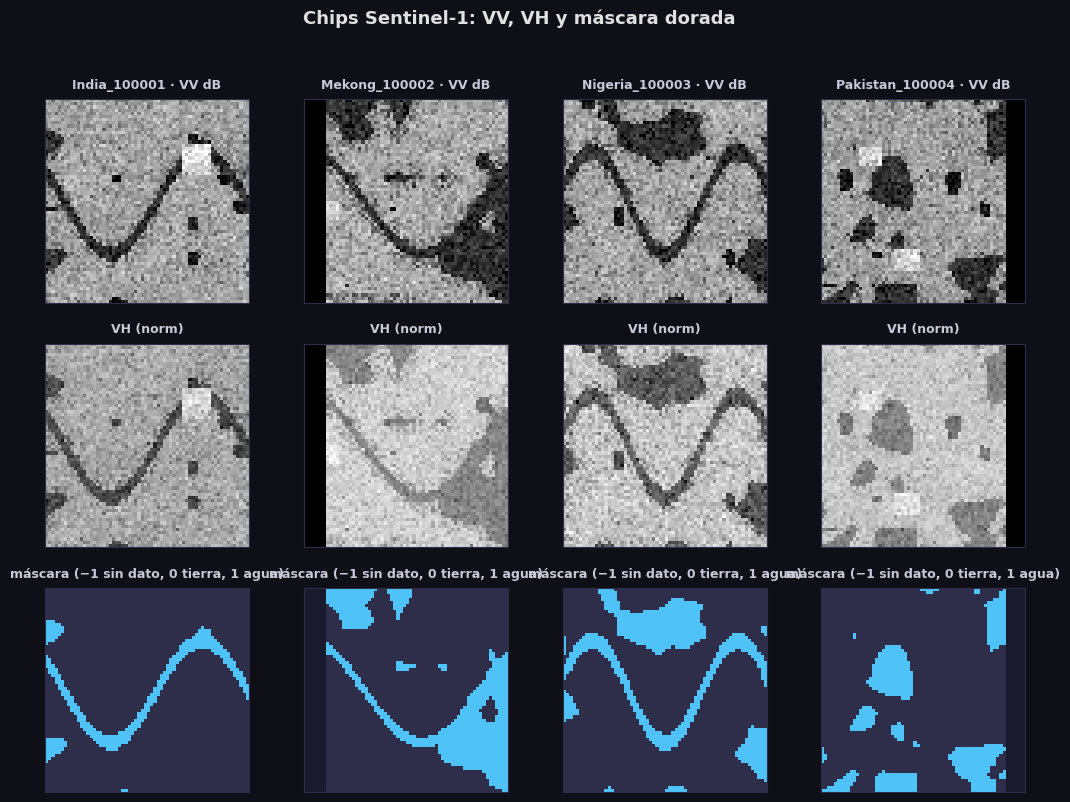

In [135]:
with timed("P2 · inspección"):
    test_ds = FloodChips(fdata.test, None, train=False)
    xs_test = np.stack([test_ds[i]["x"].numpy() for i in range(len(test_ds))])
    ys_test = np.stack([test_ds[i]["y"].numpy() for i in range(len(test_ds))])
    ids_test = [test_ds[i]["id"] for i in range(len(test_ds))]
    stats = pd.DataFrame([{"split": s, **label_stats(FloodChips(ch, None, train=False))}
                          for s, ch in (("train", fdata.train), ("valid", fdata.valid), ("test", fdata.test), ("bolivia", fdata.bolivia))])
    probe = torch.randn(1, fcfg.in_channels, 64, 64)
    arch = pd.DataFrame([{"skip_mode": s, "params_M": unet_params(UNet(fcfg.in_channels, fcfg.base_channels, fcfg.depth, s)) / 1e6,
                          "out_shape": tuple(UNet(fcfg.in_channels, fcfg.base_channels, fcfg.depth, s)(probe).shape)}
                         for s in ("concat", "attention", "none")])
display(stats.round(3))
display(arch.round(3))
fplots.plot_chip_gallery(xs_test, ys_test, ids_test, n=min(4, len(ids_test)), path=FLOOD_FIG / "gallery.png")
plt.show()


## 10. Entregable 1 · U-Net base entrenada solo con chips dorados

| Línea | Qué hace |
|---|---|
| `run_flood_experiment(fcfg, fdata, "unet_gold_combo", track=("valid", "bolivia"))` | Entrena la U-Net con BCE+Dice, *early stopping* por IoU de validación, registra validación y Bolivia por época, elige umbral en validación y evalúa test y Bolivia |
| `plot_history` | Pérdida y IoU por época (Bolivia en línea punteada) |
| `plot_threshold_curve` | Cómo varían IoU, F1, P y R con el umbral en validación y cuál se eligió |

[unet] params=0.45M depth=3 base=16 skip=concat loss=combo weak=False train_chips=54 device=cuda
  epoch=1 | train_loss=0.6684 | time=0.1336 | valid_iou=0.6257 | valid_f1=0.7698 | bolivia_iou=0.5802 | bolivia_f1=0.7343
  epoch=2 | train_loss=0.5178 | time=0.1109 | valid_iou=0.6532 | valid_f1=0.7902 | bolivia_iou=0.6266 | bolivia_f1=0.7704
  epoch=3 | train_loss=0.4628 | time=0.1580 | valid_iou=0.7789 | valid_f1=0.8757 | bolivia_iou=0.7184 | bolivia_f1=0.8361
  epoch=4 | train_loss=0.4440 | time=0.0842 | valid_iou=0.7932 | valid_f1=0.8847 | bolivia_iou=0.7141 | bolivia_f1=0.8332
  epoch=5 | train_loss=0.4411 | time=0.0714 | valid_iou=0.7749 | valid_f1=0.8732 | bolivia_iou=0.6904 | bolivia_f1=0.8168
[unet_gold_combo] thr=0.50 test IoU=0.8136 F1=0.8972 | Bolivia IoU=0.7141 F1=0.8332
⏱ P2 · U-Net dorados (BCE+Dice): 1.42 s ✓


,name,split,threshold,iou_pixel,iou_chip_mean,f1,precision,recall,omission,commission,accuracy
0,unet_gold_combo,valid,0.5,0.7932,0.7308,0.8847,0.8476,0.9252,0.0748,0.1524,0.9535
1,unet_gold_combo,test,0.5,0.8136,0.7538,0.8972,0.8566,0.9419,0.0581,0.1434,0.9610
2,unet_gold_combo,bolivia,0.5,0.7141,0.6368,0.8332,0.7598,0.9223,0.0777,0.2402,0.9388


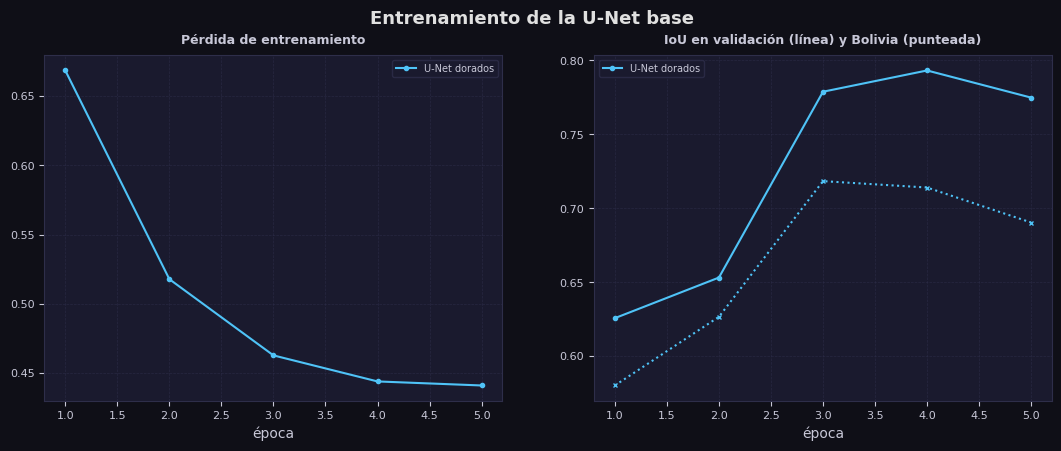

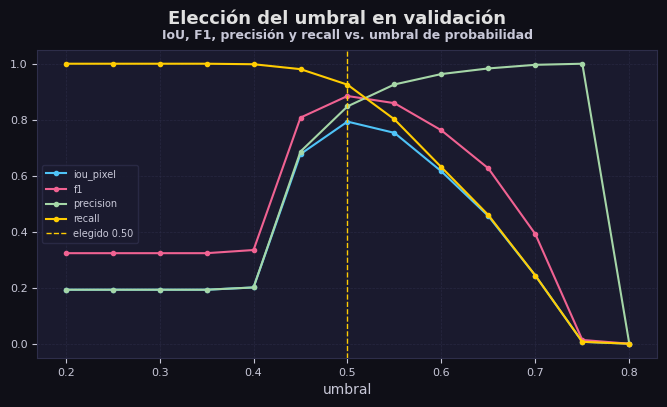

In [136]:
with timed("P2 · U-Net dorados (BCE+Dice)"):
    f_base = run_flood_experiment(fcfg, fdata, "unet_gold_combo", track=("valid", "bolivia"))
display(f_base["table"].round(4))
fplots.plot_history({"U-Net dorados": f_base["history"]}, "Entrenamiento de la U-Net base", FLOOD_FIG / "history_base.png")
fplots.plot_threshold_curve(f_base["threshold_table"], f_base["threshold"], FLOOD_FIG / "threshold.png")
plt.show()


## 11. Entregable 3 · evaluación en distribución (test)

| Línea | Qué hace |
|---|---|
| `f_base["metrics"]["test"]` | IoU píxel y chip, F1, P, R, omisión, comisión sobre los chips dorados de eventos vistos |
| `confusion.matrix()` | Conteos absolutos TP/FP/FN/TN; `plot_confusion` los normaliza por fila |
| `per_event_table` | Desglose por evento dentro del test |

test · IoU píxel=0.8136 | IoU chip=0.7538 | F1=0.8972 | P=0.8566 | R=0.9419 | omisión=0.0581 | comisión=0.1434


,pred: no agua,pred: agua
,,
real: no agua,88023,3169
real: agua,1169,18935


,event,n_chips,iou_pixel,f1,precision,recall
0,Ghana,3,0.706,0.828,0.728,0.958
1,India,5,0.755,0.860,0.830,0.893
2,Mekong,1,0.826,0.904,0.838,0.983
3,Nigeria,5,0.868,0.929,0.903,0.957
4,Pakistan,2,0.853,0.921,0.883,0.962
5,Paraguay,3,0.750,0.857,0.789,0.939
6,Spain,3,0.847,0.917,0.873,0.966
7,Sri-Lanka,2,0.840,0.913,0.873,0.958
8,USA,4,0.772,0.871,0.835,0.910


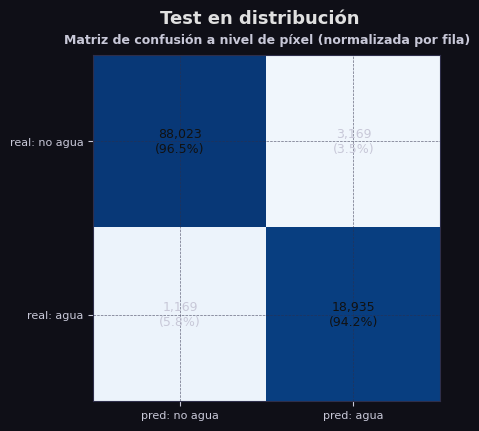

In [137]:
m_test = f_base["metrics"]["test"]
print(f"test · IoU píxel={m_test['iou_pixel']:.4f} | IoU chip={m_test['iou_chip_mean']:.4f} | F1={m_test['f1']:.4f} | "
      f"P={m_test['precision']:.4f} | R={m_test['recall']:.4f} | omisión={m_test['omission']:.4f} | comisión={m_test['commission']:.4f}")
display(m_test["confusion"].matrix())
display(per_event_table(f_base, "test").round(3))
fplots.plot_confusion(m_test["confusion"], "Test en distribución", FLOOD_FIG / "confusion_test.png")
plt.show()


**Lectura de la matriz.** La fila "real: agua" muestra la omisión (agua no detectada, típicamente doble rebote urbano y agua rugosa por viento); la fila "real: no agua" muestra la comisión (tierra marcada como agua, típicamente sombras de radar y superficies lisas). Como el agua es la clase minoritaria, la exactitud global es engañosa y la métrica que importa es el IoU de la clase agua.

## 12. Entregable 2 · ablación

| Celda | Factor | Experimentos |
|---|---|---|
| A | Función de pérdida | `gold_bce`, `gold_dice` (vs. `unet_gold_combo`) |
| B | Fuente de supervisión | `gold+weak_combo` (chips débiles con peso 0.5) |
| C | Diseño de los saltos | `skip_attention`, `skip_none` |

`run_grid` devuelve `test_iou`, `bolivia_iou` y `gap_iou` por configuración; en demo cada celda se mantiene bajo 10 s.

In [138]:
flood_tables, flood_results = [], {"unet_gold_combo": f_base}
with timed("P2 · ablación A (pérdida)"):
    t, r = run_grid(fcfg, fdata, {"gold_bce": {"loss": "bce"}, "gold_dice": {"loss": "dice"}})
flood_tables.append(t); flood_results.update(r)
display(t.round(4))


⏱ P2 · ablación A (pérdida): 2.13 s ✓


,name,loss,best_epoch,threshold,valid_iou,test_iou,test_f1,bolivia_iou,bolivia_f1,gap_iou
0,gold_bce,bce,5,0.40,0.7789,0.8008,0.8894,0.6886,0.8156,0.1122
1,gold_dice,dice,5,0.55,0.7541,0.7754,0.8735,0.6667,0.8000,0.1088


In [139]:
with timed("P2 · ablación B (dorados + débiles)"):
    t, r = run_grid(fcfg, fdata, {"gold+weak_combo": {"use_weak": True}})
flood_tables.append(t); flood_results.update(r)
display(t.round(4))


⏱ P2 · ablación B (dorados + débiles): 1.10 s ✓


,name,use_weak,best_epoch,threshold,valid_iou,test_iou,test_f1,bolivia_iou,bolivia_f1,gap_iou
0,gold+weak_combo,True,4,0.65,0.8503,0.861,0.9253,0.7459,0.8545,0.1151


In [140]:
with timed("P2 · ablación C (saltos)"):
    t, r = run_grid(fcfg, fdata, {"skip_attention": {"skip_mode": "attention"}, "skip_none": {"skip_mode": "none"}})
flood_tables.append(t); flood_results.update(r)
display(t.round(4))


⏱ P2 · ablación C (saltos): 1.17 s ✓


,name,skip_mode,best_epoch,threshold,valid_iou,test_iou,test_f1,bolivia_iou,bolivia_f1,gap_iou
0,skip_attention,attention,4,0.50,0.7500,0.7672,0.8683,0.6753,0.8062,0.0919
1,skip_none,none,4,0.55,0.4537,0.4610,0.6311,0.4095,0.5810,0.0515


,name,loss,best_epoch,threshold,valid_iou,test_iou,test_f1,bolivia_iou,bolivia_f1,gap_iou,use_weak,skip_mode
0,gold+weak_combo,NaN,4,0.65,0.8503,0.8610,0.9253,0.7459,0.8545,0.1151,True,NaN
1,unet_gold_combo,NaN,4,0.50,0.7932,0.8136,0.8972,0.7141,0.8332,0.0995,NaN,NaN
2,gold_bce,bce,5,0.40,0.7789,0.8008,0.8894,0.6886,0.8156,0.1122,NaN,NaN
3,gold_dice,dice,5,0.55,0.7541,0.7754,0.8735,0.6667,0.8000,0.1088,NaN,NaN
4,skip_attention,NaN,4,0.50,0.7500,0.7672,0.8683,0.6753,0.8062,0.0919,NaN,attention
5,skip_none,NaN,4,0.55,0.4537,0.4610,0.6311,0.4095,0.5810,0.0515,NaN,none


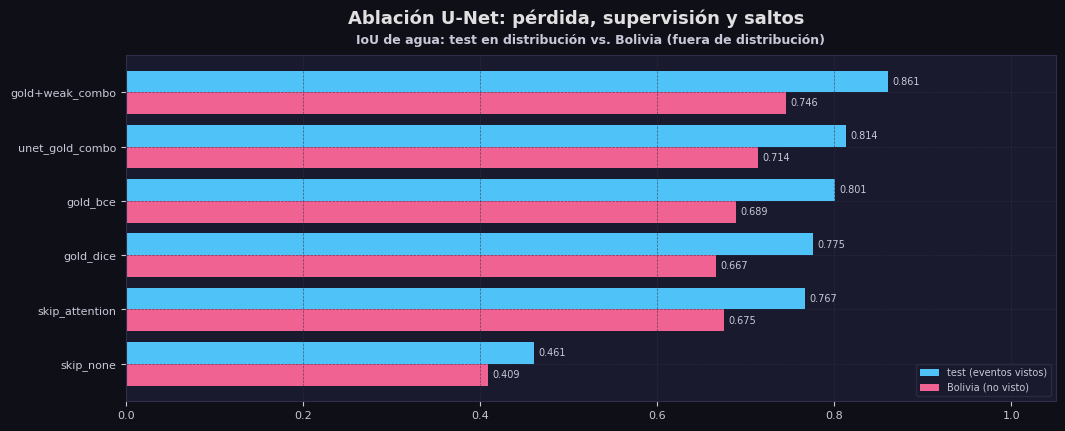

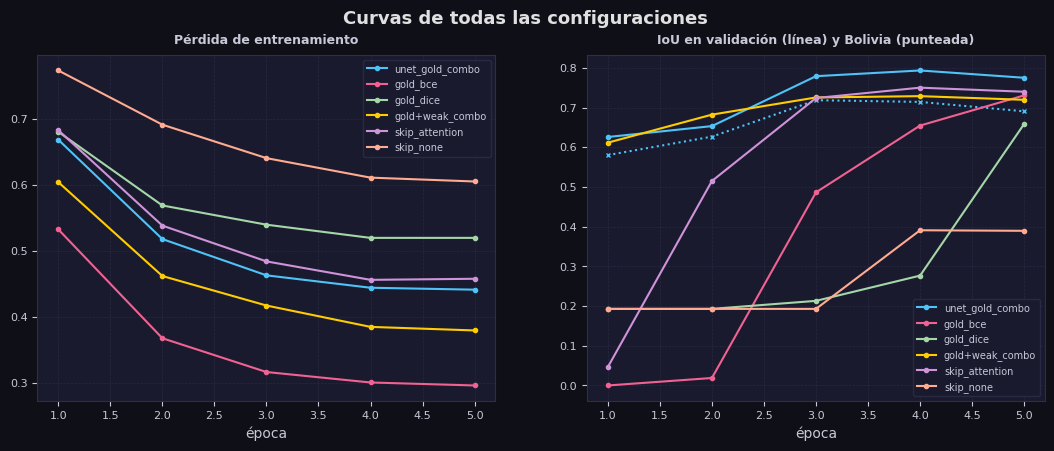

In [141]:
base_row = pd.DataFrame([{"name": "unet_gold_combo", "best_epoch": f_base["best_epoch"], "threshold": f_base["threshold"],
                          "valid_iou": f_base["metrics"]["valid"]["iou_pixel"], "test_iou": f_base["metrics"]["test"]["iou_pixel"],
                          "test_f1": f_base["metrics"]["test"]["f1"], "bolivia_iou": f_base["metrics"]["bolivia"]["iou_pixel"],
                          "bolivia_f1": f_base["metrics"]["bolivia"]["f1"]}])
base_row["gap_iou"] = base_row["test_iou"] - base_row["bolivia_iou"]
flood_ablation = pd.concat(flood_tables + [base_row], ignore_index=True).sort_values("test_iou", ascending=False).reset_index(drop=True)
flood_ablation.to_csv(fcfg.work_dir / "ablation.csv", index=False)
display(flood_ablation.round(4))
fplots.plot_ablation(flood_ablation, "Ablación U-Net: pérdida, supervisión y saltos", FLOOD_FIG / "ablation.png")
fplots.plot_history({k: v["history"] for k, v in flood_results.items()}, "Curvas de todas las configuraciones", FLOOD_FIG / "history_all.png")
plt.show()


## 13. Entregable 4 · generalización geográfica (Bolivia)

El entrenamiento ya excluyó Bolivia (dorados y débiles). Aquí se mide la brecha del mejor modelo entre el test en distribución y Bolivia, métrica a métrica.

| Línea | Qué hace |
|---|---|
| `best_flood` | Mejor configuración por `test_iou` (nunca por Bolivia, que es solo evaluación) |
| `generalization_gap` | Tabla test vs. Bolivia con Δ |
| `plot_confusion(..., "Bolivia")` | Matriz de confusión fuera de distribución para comparar omisión/comisión |

⏱ P2 · brecha Bolivia: 0.00 s ✓
mejor configuración: gold+weak_combo


,metric,test_in_distribution,bolivia_held_out,gap
0,iou_pixel,0.8610,0.7459,0.1151
1,iou_chip_mean,0.8053,0.6702,0.1352
2,f1,0.9253,0.8545,0.0708
3,precision,0.8977,0.7666,0.1311
4,recall,0.9546,0.9650,-0.0104
5,omission,0.0454,0.0350,0.0104
6,commission,0.1023,0.2334,-0.1311
7,accuracy,0.9722,0.9455,0.0266


,pred: no agua,pred: agua
,,
real: no agua,62596,3879
real: agua,462,12743


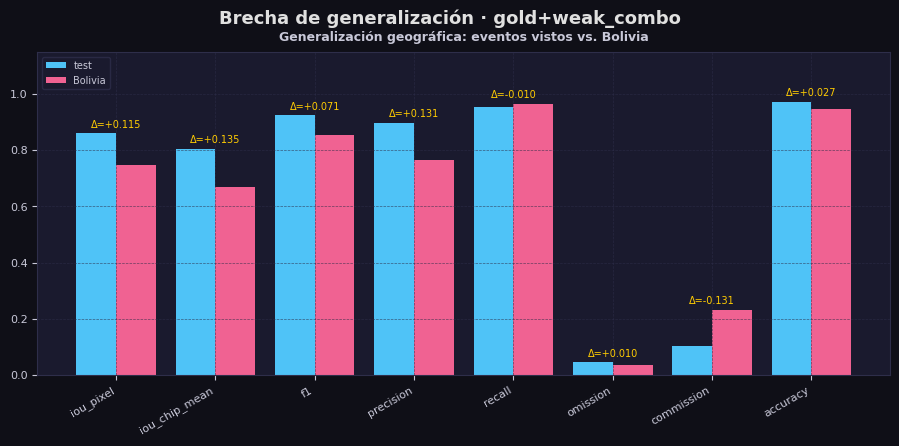

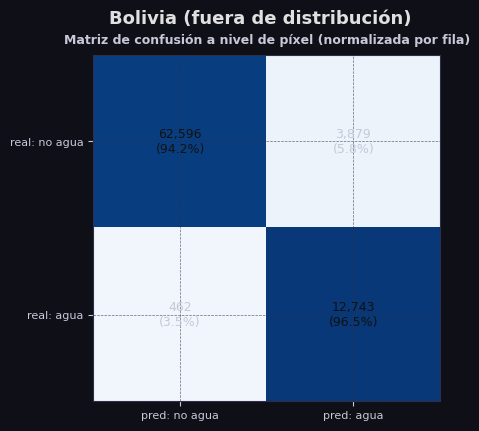

In [142]:
with timed("P2 · brecha Bolivia"):
    best_flood_name = flood_ablation.iloc[0]["name"]
    best_flood = flood_results[best_flood_name]
    gap = generalization_gap(best_flood)
print(f"mejor configuración: {best_flood_name}")
display(gap.round(4))
display(best_flood["metrics"]["bolivia"]["confusion"].matrix())
fplots.plot_gap(gap, f"Brecha de generalización · {best_flood_name}", FLOOD_FIG / "gap_bolivia.png")
fplots.plot_confusion(best_flood["metrics"]["bolivia"]["confusion"], "Bolivia (fuera de distribución)", FLOOD_FIG / "confusion_bolivia.png")
plt.show()


**Hipótesis sobre la brecha** (a contrastar con los datos reales):
1. **Cobertura del suelo y tipo de inundación.** El evento de Bolivia (llanura amazónica, 2018) tiene grandes extensiones de vegetación inundada y suelo saturado; el modelo entrenado en eventos con agua abierta aprende "oscuro = agua" y comete comisión en suelo húmedo y omisión en vegetación inundada (brillante por doble rebote tronco-agua).
2. **Geometría de adquisición.** Ángulo de incidencia y órbita (ascendente/descendente, `rel_orbit_num` en los metadatos) cambian el nivel absoluto de retrodispersión; un desplazamiento de 1–2 dB mueve píxeles a través del umbral implícito que la red aprendió.
3. **Prevalencia de agua.** Si Bolivia tiene una fracción de agua mayor que la media de entrenamiento, el umbral elegido en validación queda desplazado y la precisión cae aunque el recall se mantenga (patrón visible en la tabla cuando Δ de comisión es negativo y Δ de omisión es cercano a cero).

## 14. Entregable 5 · fallos característicos del SAR

| Línea | Qué hace |
|---|---|
| `error_taxonomy` | Clasifica cada píxel erróneo del test por su retrodispersión VV en dB: FP oscuro (sombra/superficie lisa), FP intermedio (suelo húmedo), FN brillante (doble rebote / vegetación inundada), FN de borde |
| `pick_examples` | Chip con más píxeles de cada tipo |
| `plot_error_examples` | VV · dorada · predicción · mapa de error para cada ejemplo |
| `mock_mechanism_audit` | Solo demo: tasa de error del modelo sobre los píxeles de sombra, doble rebote y suelo húmedo reales del generador, lo que valida que la taxonomía por VV captura los mecanismos |

⏱ P2 · taxonomía de fallos: 0.04 s ✓


,pixels,share_of_errors,share_of_valid,description
FP_oscuro,1486,0.4795,0.0134,Falso positivo con VV < -18 dB: sombra de rada...
FP_intermedio,524,0.1691,0.0047,Falso positivo con -18 ≤ VV < -11 dB: suelo hú...
FP_otro,176,0.0568,0.0016,Falso positivo brillante: residual
FN_brillante,159,0.0513,0.0014,Falso negativo con VV > -8 dB: doble rebote en...
FN_borde,754,0.2433,0.0068,Falso negativo restante: bordes de cuerpos de ...


,mechanism,pixels,error_rate
0,shadow,1957,0.728
1,double_bounce,160,1.000
2,wet_soil,3822,0.148


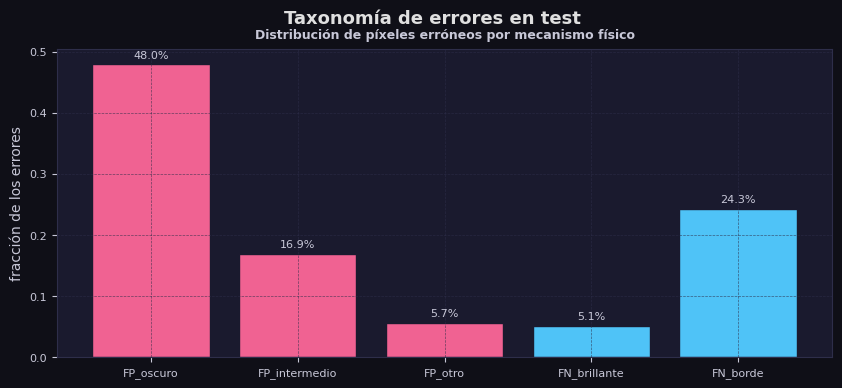

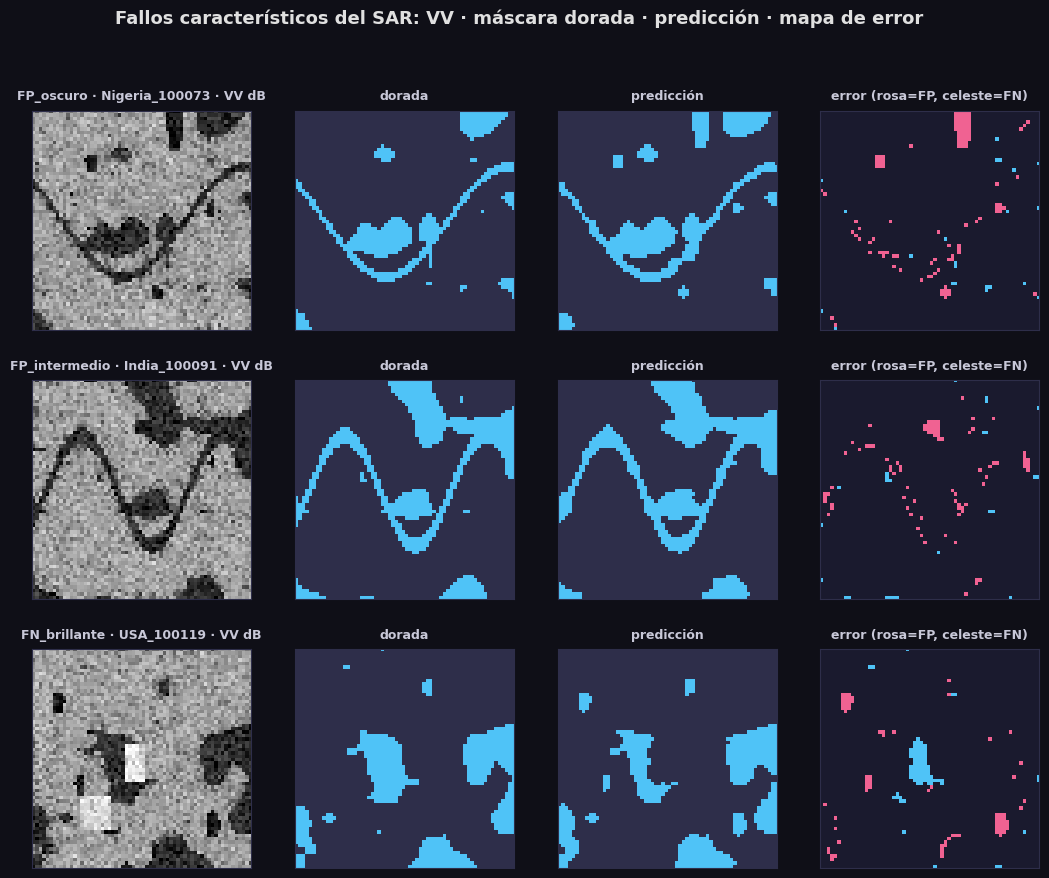

In [143]:
with timed("P2 · taxonomía de fallos"):
    p_test, y_test, id_test = best_flood["preds"]["test"]
    order = [id_test.index(i) for i in ids_test]
    p_test, y_test, id_test = p_test[order], y_test[order], [id_test[k] for k in order]
    tax_summary, tax_chip = error_taxonomy(xs_test, p_test, y_test, id_test, best_flood["threshold"])
    picks = pick_examples(tax_chip, k=1)
    audit = mock_mechanism_audit(fcfg, fdata.test, p_test, y_test, id_test, best_flood["threshold"])
display(tax_summary.round(4))
if audit is not None:
    display(audit.round(3))
fplots.plot_error_taxonomy(tax_summary, "Taxonomía de errores en test", FLOOD_FIG / "error_taxonomy.png")
fplots.plot_error_examples(xs_test, p_test, y_test, id_test, picks, best_flood["threshold"], FLOOD_FIG / "error_examples.png")
plt.show()


**Interpretación de los tres tipos de error.**
- **Sombra de radar (FP oscuro).** Detrás de un relieve que mira en contra del haz el sensor no recibe eco: el píxel es tan oscuro como el agua. Solo la geometría (un DEM o la órbita) lo distingue; la red, que ve únicamente VV/VH, lo confunde salvo que aprenda el contexto de textura de las laderas. En demo la auditoría muestra que la mayoría de los píxeles de sombra se predicen como agua.
- **Doble rebote urbano (FN brillante).** En zonas urbanas o bosques inundados la señal rebota agua → pared/tronco → sensor y vuelve amplificada: el píxel inundado aparece **más brillante** que la tierra seca. Es el caso opuesto al prior "agua = oscuro" y por eso el recall cae; en demo la tasa de error sobre esos píxeles es cercana al 100 %.
- **Suelo húmedo (FP intermedio).** Suelo saturado y vegetación baja empapada reducen la retrodispersión a valores intermedios (−18…−11 dB) y forman un halo alrededor del agua abierta; el modelo lo marca como agua con una probabilidad intermedia, por lo que este tipo de error es el más sensible al umbral elegido.

---
## 15. Pregunta 3 · Monitoreo de fauna silvestre con cámaras trampa (YOLO)

### Diseño experimental

| Decisión | Elección | Justificación |
|---|---|---|
| Detector | YOLOv8n (Ultralytics) ajustado desde pesos COCO; si no hay red, se entrena desde `yolov8n.yaml` | Entregable 1; el fine-tuning desde COCO acelera la convergencia en pocas épocas y COCO ya contiene animales |
| Entrada | Imágenes JPEG de CCT redimensionadas a `imgsz` con letterbox (640 en real, 96 en demo) | Los animales lejanos ocupan pocos píxeles: la resolución es la decisión que más afecta a los objetos pequeños |
| Aumento de datos | Volteo horizontal, jitter HSV (simula día/noche e infrarrojo), escala 0.5, traslación, mosaico (apagado al final con `close_mosaic`); **sin volteo vertical ni rotación** | Un animal cabeza abajo no existe en cámaras trampa; el mosaico mezcla fondos de distintas cámaras y rompe la memorización del fondo |
| Imágenes vacías | Se conservan como **fondo** (archivo de etiqueta vacío) con una fracción controlada del 35 % del entrenamiento, frente al 70 % del dataset | Sin vacías, el detector no aprende qué no es un animal y dispara sobre rocas y troncos; con el 70 % original, dominan el lote |
| Desbalance | Submuestreo estratificado que garantiza un mínimo de cajas por especie y reporte por especie con `n` de entrenamiento | Entregable 2 |
| Partición | Oficial `eccv_18`: `train`, `cis_val`/`cis_test` (cámaras vistas) y `trans_val`/`trans_test` (cámaras nuevas); `assert` de que ninguna cámara trans está en train | Entregable 3 |
| Métricas | mAP@0.5 y mAP@0.5:0.95 con evaluador propio (interpolación COCO de 101 puntos), P/R por especie al umbral elegido en `cis_val`, y métricas a nivel de imagen (tasa de falsa alarma en vacías) | Entregable 2, sin depender del validador de Ultralytics para poder evaluar subconjuntos |
| Fondo vs. animal | Grad-CAM sobre el backbone (SPPF en real, capa de paso 8 en demo) y fracción de energía dentro de la caja, comparada entre cámaras vistas y nuevas | Entregable 3 |
| Robustez | Particiones por tamaño relativo de la caja y por un **proxy de oclusión** (área relativa a la mediana de su especie + truncamiento por el borde); en demo el proxy se audita contra la oclusión real del generador | Entregable 4; CCT no anota oclusión, por eso se estima |
| Monitoreo | Reglas: especie de la foto = detección de mayor confianza; eventos independientes con ventana de 30 min por cámara y especie; reporte por cámara, especie y periodo del día | Entregable 5, regla estándar en ecología de cámaras trampa (O'Brien et al., 2003) |

**Datos reales.** Desde LILA BC (`https://lila.science/datasets/caltech-camera-traps`): el paquete `eccv_18_all_images_sm.tar.gz` (imágenes reducidas, ~6 GB), el JSON de anotaciones (`caltech_images_20210113.json` o `CaltechCameraTrapsECCV18.json`) y la carpeta `eccv_18_annotation_files/` con las particiones `train`, `cis_val`, `cis_test`, `trans_val`, `trans_test`. Se descomprimen en `data/cct/` o se apunta con `CCT_DATA_ROOT`. Sin datos, el notebook usa el fixture sintético.

In [145]:
import os
os.makedirs("wildlife", exist_ok=True)
print(os.getcwd(), "->", "wildlife" in os.listdir())

/content -> True


### 15.1 `wildlife/config.py`

| Línea / bloque | Qué hace |
|---|---|
| `SPLIT_FILES` | Nombres de los cinco JSON oficiales de la partición `eccv_18` |
| `PERIODS` | Periodos del día (noche, amanecer, día, atardecer) usados por el módulo de monitoreo |
| `WildlifeConfig` | Modelo y pesos, resolución, épocas, optimizador y calentamiento, caché en RAM, congelación opcional del backbone, aumentación (cada parámetro es una decisión documentada del Entregable 1), presupuesto de imágenes, fracción de vacías, umbrales, ventana de independencia y parámetros del fixture |
| `yolo_dir` / `runs_dir` | Carpetas donde se exporta el dataset en formato YOLO y donde Ultralytics deja cada corrida |
| `device` | `0` si hay GPU, `cpu` en otro caso |

In [146]:
%%writefile wildlife/config.py
from __future__ import annotations

import os
from dataclasses import asdict, dataclass, field
from pathlib import Path

EMPTY = "empty"
SPLITS = ("train", "cis_val", "cis_test", "trans_val", "trans_test")
SPLIT_FILES = {
    "train": "train_annotations.json",
    "cis_val": "cis_val_annotations.json",
    "cis_test": "cis_test_annotations.json",
    "trans_val": "trans_val_annotations.json",
    "trans_test": "trans_test_annotations.json",
}
PERIODS = ((0, 5, "noche"), (5, 8, "amanecer"), (8, 17, "dia"), (17, 20, "atardecer"), (20, 24, "noche"))


def detect_data_root() -> Path:
    for cand in ("/kaggle/input/caltech-camera-traps", os.environ.get("CCT_DATA_ROOT", ""), "data/cct"):
        if cand and Path(cand).exists():
            return Path(cand)
    return Path("data/cct")


@dataclass
class WildlifeConfig:
    data_root: Path = field(default_factory=detect_data_root)
    work_dir: Path = Path("work_wildlife")
    seed: int = 42

    model: str = "yolov8n.pt"
    pretrained: bool = True
    imgsz: int = 640
    epochs: int = 30
    batch_size: int = 16
    optimizer: str = "auto"
    lr0: float = 0.01
    lrf: float = 0.01
    warmup_epochs: float = 3.0
    cache_images: bool = True
    freeze_backbone: bool = False
    patience: int = 10
    amp: bool = True
    num_workers: int = 2

    fliplr: float = 0.5
    flipud: float = 0.0
    hsv_h: float = 0.015
    hsv_s: float = 0.5
    hsv_v: float = 0.4
    scale: float = 0.5
    translate: float = 0.1
    mosaic: float = 1.0
    close_mosaic: int = 5
    degrees: float = 0.0

    max_train_images: int = 3000
    max_eval_images: int = 600
    empty_fraction: float = 0.35
    min_per_species: int = 20
    use_empty: bool = True

    gradcam_layer: int = 9
    conf_eval: float = 0.001
    iou_nms: float = 0.6
    conf_monitor: float = 0.25
    independence_minutes: int = 30
    size_bins: tuple[float, float] = (0.01, 0.08)

    mock: bool = False
    mock_size: int = 96
    mock_locations: int = 9
    mock_trans_locations: int = 3
    mock_images_per_location: int = 30

    def __post_init__(self) -> None:
        self.data_root = Path(self.data_root)
        self.work_dir = Path(self.work_dir)
        self.work_dir.mkdir(parents=True, exist_ok=True)

    @property
    def yolo_dir(self) -> Path:
        d = self.work_dir / "yolo"
        d.mkdir(parents=True, exist_ok=True)
        return d

    @property
    def runs_dir(self) -> Path:
        return self.work_dir / "runs"

    @property
    def device(self) -> str:
        import torch

        return "0" if torch.cuda.is_available() else "cpu"

    def to_dict(self) -> dict:
        d = asdict(self)
        d["data_root"], d["work_dir"] = str(self.data_root), str(self.work_dir)
        return d


def period_of(hour: int) -> str:
    for lo, hi, name in PERIODS:
        if lo <= hour < hi:
            return name
    return "noche"


Writing wildlife/config.py


### 15.2 `wildlife/data.py` · cargador CCT y exportación YOLO

| Línea / bloque | Qué hace |
|---|---|
| `Record` | Una foto: id, ruta, cámara (`location`), fecha, secuencia, tamaño y cajas normalizadas `(clase, cx, cy, w, h)`; sin cajas = vacía |
| `load_cct()` | Lee el JSON COCO de CCT (categorías, imágenes con `location` y `date_captured`, cajas absolutas `[x, y, w, h]`), descarta `empty` como clase y la deja como ausencia de caja; carga los ids de cada partición oficial |
| `split_by_location()` | Respaldo si faltan los JSON oficiales: separa cámaras completas como `trans` con semilla fija |
| `subsample()` | Garantiza `min_per_species` cajas por especie (empezando por las más raras), completa con animales al azar y añade vacías hasta la fracción pedida |
| `export_yolo()` | Enlaza imágenes y escribe `labels/*.txt`; las vacías obtienen un `.txt` vacío (fondo) salvo `use_empty=False`; genera `data.yaml` |
| `prevalence_table()` / `species_counts()` | Conteos por partición y por especie con tasa de vacías y número de cámaras |

In [147]:
%%writefile wildlife/data.py
from __future__ import annotations

import json
import shutil
from dataclasses import dataclass, field
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd

from .config import EMPTY, SPLIT_FILES, SPLITS, WildlifeConfig

_DATE_FORMATS = ("%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M:%S.%f", "%Y-%m-%dT%H:%M:%S", "%Y:%m:%d %H:%M:%S")


@dataclass
class Record:
    image_id: str
    path: Path
    location: str
    taken_at: datetime | None
    seq_id: str
    width: int
    height: int
    boxes: list[tuple[int, float, float, float, float]] = field(default_factory=list)
    categories: list[int] = field(default_factory=list)

    @property
    def is_empty(self) -> bool:
        return not self.categories

    @property
    def main_class(self) -> int | None:
        return self.categories[0] if self.categories else None


def parse_datetime(value) -> datetime | None:
    if not isinstance(value, str):
        return None
    for fmt in _DATE_FORMATS:
        try:
            return datetime.strptime(value.strip(), fmt)
        except ValueError:
            continue
    return None


def _find_main_json(root: Path) -> Path:
    for name in ("caltech_images_20210113.json", "caltech_bboxes_20210113.json", "CaltechCameraTrapsECCV18.json", "cct_mock.json"):
        if (root / name).exists():
            return root / name
    for p in sorted(root.rglob("*.json")):
        if "annotation" in p.name.lower() and "split" not in p.name.lower():
            continue
        try:
            with open(p) as f:
                head = f.read(2000)
        except OSError:
            continue
        if '"images"' in head or '"annotations"' in head:
            return p
    raise FileNotFoundError(f"No COCO-style JSON found under {root}")


def _find_images_dir(root: Path) -> Path:
    for name in ("eccv_18_all_images_sm", "cct_images", "images"):
        if (root / name).exists():
            return root / name
    return root


def load_cct(cfg: WildlifeConfig) -> tuple[list[Record], list[str], dict[str, set[str]]]:
    root = cfg.data_root
    main = _find_main_json(root)
    with open(main) as f:
        meta = json.load(f)
    cats = sorted(meta["categories"], key=lambda c: c["id"])
    names = [c["name"].strip().lower().replace(" ", "_") for c in cats]
    animal_names = [n for n in names if n != EMPTY]
    cls_of = {c["id"]: animal_names.index(c["name"].strip().lower().replace(" ", "_")) for c in cats if c["name"].strip().lower() != EMPTY}
    img_dir = _find_images_dir(root)
    records: dict[str, Record] = {}
    for im in meta["images"]:
        iid = str(im["id"])
        fname = im.get("file_name", f"{iid}.jpg")
        path = img_dir / fname
        if not path.exists():
            path = img_dir / Path(fname).name
        records[iid] = Record(iid, path, str(im.get("location", "unknown")), parse_datetime(im.get("date_captured") or im.get("datetime")),
                              str(im.get("seq_id", iid)), int(im.get("width", 0)), int(im.get("height", 0)))
    for ann in meta["annotations"]:
        rec = records.get(str(ann["image_id"]))
        if rec is None or ann["category_id"] not in cls_of:
            continue
        cls = cls_of[ann["category_id"]]
        rec.categories.append(cls)
        if ann.get("bbox") and rec.width and rec.height:
            x, y, w, h = ann["bbox"]
            rec.boxes.append((cls, (x + w / 2) / rec.width, (y + h / 2) / rec.height, w / rec.width, h / rec.height))
    splits = _load_splits(root, set(records))
    return list(records.values()), animal_names, splits


def _load_splits(root: Path, ids: set[str]) -> dict[str, set[str]]:
    split_dir = next((d for d in (root / "eccv_18_annotation_files", root / "splits", root) if any((d / f).exists() for f in SPLIT_FILES.values())), None)
    out: dict[str, set[str]] = {}
    if split_dir is None:
        return out
    for split, fname in SPLIT_FILES.items():
        p = split_dir / fname
        if not p.exists():
            continue
        with open(p) as f:
            data = json.load(f)
        items = data["images"] if isinstance(data, dict) and "images" in data else data
        out[split] = {str(i["id"] if isinstance(i, dict) else i) for i in items} & ids
    return out


def split_by_location(records: list[Record], trans_fraction: float, seed: int) -> dict[str, set[str]]:
    rng = np.random.default_rng(seed)
    locs = sorted({r.location for r in records})
    rng.shuffle(locs)
    n_trans = max(1, int(round(len(locs) * trans_fraction)))
    trans = set(locs[:n_trans])
    out = {s: set() for s in SPLITS}
    for r in records:
        u = rng.random()
        if r.location in trans:
            out["trans_val" if u < 0.4 else "trans_test"].add(r.image_id)
        else:
            out["train" if u < 0.7 else "cis_val" if u < 0.85 else "cis_test"].add(r.image_id)
    return out


def assign_splits(records: list[Record], splits: dict[str, set[str]]) -> dict[str, list[Record]]:
    by_id = {r.image_id: r for r in records}
    return {s: [by_id[i] for i in sorted(ids) if i in by_id] for s, ids in splits.items()}


def subsample(records: list[Record], max_images: int, empty_fraction: float, min_per_species: int, n_classes: int, seed: int) -> list[Record]:
    rng = np.random.default_rng(seed)
    animals = [r for r in records if not r.is_empty]
    empties = [r for r in records if r.is_empty]
    chosen: dict[str, Record] = {}
    counts = np.zeros(n_classes, dtype=int)
    for cls in np.argsort([sum(cls in r.categories for r in animals) for cls in range(n_classes)]):
        cand = [r for r in animals if cls in r.categories and r.image_id not in chosen]
        rng.shuffle(cand)
        for r in cand[: max(min_per_species - counts[cls], 0)]:
            chosen[r.image_id] = r
            for c in set(r.categories):
                counts[c] += 1
    n_animal_target = int(round(max_images * (1 - empty_fraction)))
    rest = [r for r in animals if r.image_id not in chosen]
    rng.shuffle(rest)
    for r in rest[: max(n_animal_target - len(chosen), 0)]:
        chosen[r.image_id] = r
    rng.shuffle(empties)
    n_empty = min(len(empties), int(round(len(chosen) * empty_fraction / max(1 - empty_fraction, 1e-6))))
    out = list(chosen.values()) + empties[:n_empty]
    rng.shuffle(out)
    return out


def export_yolo(cfg: WildlifeConfig, sets: dict[str, list[Record]], names: list[str], use_empty: bool = True, tag: str = "cct") -> Path:
    base = cfg.yolo_dir / tag
    for split, recs in sets.items():
        img_dir, lab_dir = base / "images" / split, base / "labels" / split
        img_dir.mkdir(parents=True, exist_ok=True)
        lab_dir.mkdir(parents=True, exist_ok=True)
        for r in recs:
            if r.is_empty and not use_empty:
                continue
            dst = img_dir / f"{r.image_id}{r.path.suffix or '.jpg'}"
            if not dst.exists():
                try:
                    dst.symlink_to(r.path.resolve())
                except OSError:
                    shutil.copy2(r.path, dst)
            (lab_dir / f"{r.image_id}.txt").write_text("".join(f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n" for c, x, y, w, h in r.boxes))
    yaml = base / "data.yaml"
    lines = [f"path: {base.resolve()}", "train: images/train", f"val: images/{'cis_val' if 'cis_val' in sets else 'train'}", "names:"]
    lines += [f"  {i}: {n}" for i, n in enumerate(names)]
    yaml.write_text("\n".join(lines) + "\n")
    return yaml


def prevalence_table(sets: dict[str, list[Record]], names: list[str]) -> pd.DataFrame:
    rows = []
    for split, recs in sets.items():
        counts = np.zeros(len(names), dtype=int)
        for r in recs:
            for c in r.categories:
                counts[c] += 1
        n_empty = sum(r.is_empty for r in recs)
        rows.append({"split": split, "n_images": len(recs), "n_empty": n_empty, "empty_rate": n_empty / max(len(recs), 1),
                     "n_locations": len({r.location for r in recs}), **{n: int(counts[i]) for i, n in enumerate(names)}})
    return pd.DataFrame(rows).set_index("split")


def species_counts(records: list[Record], names: list[str]) -> pd.DataFrame:
    counts = np.zeros(len(names), dtype=int)
    for r in records:
        for c in r.categories:
            counts[c] += 1
    df = pd.DataFrame({"species": names, "n_boxes": counts})
    df["share"] = df["n_boxes"] / max(df["n_boxes"].sum(), 1)
    return df.sort_values("n_boxes", ascending=False).reset_index(drop=True)


Writing wildlife/data.py


### 15.3 `wildlife/mock.py` · fixture sintético de cámaras trampa

| Línea / bloque | Qué hace |
|---|---|
| `SPECIES` | Ocho especies con prevalencia desbalanceada (coyote 30 % … puma 2 %), color, silueta, rango de tamaño y probabilidad de actividad nocturna |
| `_location_style()` | Cada cámara tiene cielo, suelo, horizonte, densidad de hierba y un **hito fijo** (roca, tronco o árbol) en la misma posición: es exactamente el fondo que un detector puede memorizar |
| `_draw_animal()` | Cuerpo, cabeza, orejas, patas y cola con la silueta de la especie; el 20 % sale parcialmente del encuadre (truncamiento); devuelve la caja |
| `_occlude()` | Vegetación sobre una fracción de las columnas de la caja, dispersa o como banda desde un lado (la caja se reduce a la parte visible, como haría un anotador); registra la oclusión real |
| `_night()` | Versión infrarroja: escala de grises, menor contraste y ruido |
| `make_mock_cct()` | Ráfagas de 1 a 3 fotos con marca de tiempo, 45 a 65 % de fotos vacías por cámara, JSON COCO y particiones `eccv_18` con las tres últimas cámaras como `trans`; guarda `mock_meta.json` con la oclusión verdadera por caja |

In [148]:
%%writefile wildlife/mock.py
from __future__ import annotations

import json
from datetime import datetime, timedelta
from pathlib import Path

import cv2
import numpy as np

from .config import EMPTY

SPECIES = {
    "coyote": {"p": 0.30, "color": (70, 110, 150), "aspect": 1.9, "ears": True, "tail": 0.6, "scale": (0.22, 0.45), "night": 0.6},
    "rabbit": {"p": 0.22, "color": (120, 140, 160), "aspect": 1.3, "ears": True, "tail": 0.1, "scale": (0.10, 0.22), "night": 0.3},
    "raccoon": {"p": 0.15, "color": (60, 60, 70), "aspect": 1.6, "ears": True, "tail": 0.5, "scale": (0.15, 0.30), "night": 0.9},
    "bobcat": {"p": 0.12, "color": (80, 130, 180), "aspect": 1.7, "ears": True, "tail": 0.15, "scale": (0.18, 0.38), "night": 0.7},
    "opossum": {"p": 0.09, "color": (170, 170, 175), "aspect": 1.8, "ears": False, "tail": 0.7, "scale": (0.14, 0.28), "night": 0.95},
    "deer": {"p": 0.06, "color": (60, 100, 140), "aspect": 1.5, "ears": True, "tail": 0.1, "scale": (0.35, 0.60), "night": 0.4},
    "bird": {"p": 0.04, "color": (40, 40, 40), "aspect": 1.2, "ears": False, "tail": 0.4, "scale": (0.06, 0.14), "night": 0.05},
    "mountain_lion": {"p": 0.02, "color": (90, 150, 200), "aspect": 2.2, "ears": True, "tail": 0.8, "scale": (0.30, 0.55), "night": 0.75},
}


def _location_style(rng: np.random.Generator, loc: int) -> dict:
    return {
        "ground": tuple(int(v) for v in rng.integers(60, 140, 3)),
        "sky": tuple(int(v) for v in rng.integers(130, 220, 3)),
        "horizon": float(rng.uniform(0.25, 0.45)),
        "landmark": ("rock", "log", "trunk")[loc % 3],
        "landmark_pos": (float(rng.uniform(0.1, 0.8)), float(rng.uniform(0.5, 0.85))),
        "grass": float(rng.uniform(0.2, 0.9)),
        "night_rate": float(rng.uniform(0.3, 0.7)),
        "empty_rate": float(rng.uniform(0.5, 0.65)),
    }


def _draw_background(rng: np.random.Generator, n: int, style: dict) -> np.ndarray:
    img = np.zeros((n, n, 3), dtype=np.uint8)
    h = int(style["horizon"] * n)
    img[:h] = style["sky"]
    img[h:] = style["ground"]
    img = img.astype(np.float32) + rng.normal(0, 6, img.shape)
    img = np.clip(img, 0, 255).astype(np.uint8)
    lx, ly = int(style["landmark_pos"][0] * n), int(style["landmark_pos"][1] * n)
    shift = 60 if np.mean(style["ground"]) < 110 else -55
    mark = tuple(int(np.clip(c + shift, 0, 255)) for c in style["ground"])
    if style["landmark"] == "rock":
        cv2.ellipse(img, (lx, ly), (n // 8, n // 14), 0, 0, 360, mark, -1)
    elif style["landmark"] == "log":
        cv2.rectangle(img, (lx - n // 6, ly - n // 20), (lx + n // 6, ly + n // 20), mark, -1)
    else:
        cv2.rectangle(img, (lx - n // 24, h - n // 4), (lx + n // 24, ly), mark, -1)
    for _ in range(int(60 * style["grass"])):
        x = int(rng.integers(0, n))
        y0 = int(rng.integers(h, n))
        cv2.line(img, (x, y0), (x + int(rng.integers(-2, 3)), y0 - int(rng.integers(3, 10))), (40, 90, 50), 1)
    return img


def _draw_animal(img: np.ndarray, rng: np.random.Generator, spec: dict, n: int) -> tuple[int, int, int, int]:
    w = int(rng.uniform(*spec["scale"]) * n)
    hgt = max(int(w / spec["aspect"]), 5)
    cx = int(rng.integers(w // 2 + 2, n - w // 2 - 2)) if rng.random() < 0.8 else int(rng.choice([w // 5, n - w // 5]))
    cy = int(rng.integers(int(0.5 * n), n - hgt))
    ground = np.asarray(img[int(0.75 * n), :, :].mean(axis=0), dtype=np.float32)
    base = np.asarray(spec["color"], dtype=np.float32)
    if abs(float(base.mean() - ground.mean())) < 55:
        base = np.clip(base + (70.0 if ground.mean() < 128 else -70.0), 0, 255)
    color = tuple(int(np.clip(c + rng.normal(0, 10), 0, 255)) for c in base)
    cv2.ellipse(img, (cx, cy), (w // 2, hgt // 2), 0, 0, 360, color, -1)
    hx = cx + w // 2
    hr = max(hgt // 3, 2)
    cv2.circle(img, (hx, cy - hgt // 4), hr, color, -1)
    if spec["ears"]:
        cv2.line(img, (hx, cy - hgt // 4 - hr), (hx - hr // 2, cy - hgt // 4 - 2 * hr), color, 2)
        cv2.line(img, (hx + 1, cy - hgt // 4 - hr), (hx + hr // 2, cy - hgt // 4 - 2 * hr), color, 2)
    for lx in (cx - w // 3, cx - w // 8, cx + w // 8, cx + w // 3):
        cv2.line(img, (lx, cy), (lx, cy + hgt // 2 + hgt // 3), color, 2)
    tail = int(spec["tail"] * w / 2)
    if tail > 1:
        cv2.line(img, (cx - w // 2, cy), (cx - w // 2 - tail, cy - tail // 2), color, 2)
    x0, y0 = cx - w // 2 - tail, cy - hgt // 4 - 2 * hr if spec["ears"] else cy - hgt // 2
    x1, y1 = hx + hr, cy + hgt // 2 + hgt // 3
    return max(x0, 0), max(y0, 0), min(x1, n - 1), min(y1, n - 1)


def _occlude(img: np.ndarray, rng: np.random.Generator, box: tuple[int, int, int, int], level: float) -> tuple[tuple[int, int, int, int], float]:
    x0, y0, x1, y1 = box
    cols = np.arange(x0, x1 + 1)
    n_cov = int(round(level * len(cols)))
    if n_cov == 0:
        return box, 0.0
    if rng.random() < 0.5:
        chosen = rng.choice(cols, size=n_cov, replace=False)
    else:
        chosen = cols[:n_cov] if rng.random() < 0.5 else cols[-n_cov:]
        x0, x1 = (x0 + n_cov, x1) if chosen[0] == cols[0] else (x0, x1 - n_cov)
    for x in chosen:
        cv2.line(img, (int(x), y0 - 2), (int(x), y1 + 2), (35, 85, 45), 1)
    return (x0, y0, x1, y1), n_cov / len(cols)


def _night(img: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    g = 0.65 * g + 20 + rng.normal(0, 10, g.shape)
    g = np.clip(g, 0, 255).astype(np.uint8)
    return cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)


def make_mock_cct(root: Path, n_locations: int = 9, n_trans: int = 3, per_location: int = 30, size: int = 96, seed: int = 0) -> None:
    rng = np.random.default_rng(seed)
    root = Path(root)
    img_dir = root / "images"
    split_dir = root / "eccv_18_annotation_files"
    img_dir.mkdir(parents=True, exist_ok=True)
    split_dir.mkdir(parents=True, exist_ok=True)
    names = list(SPECIES)
    probs = np.array([SPECIES[s]["p"] for s in names])
    probs /= probs.sum()
    categories = [{"id": i + 1, "name": s} for i, s in enumerate(names)] + [{"id": 0, "name": EMPTY}]
    images, annotations, meta = [], [], {}
    splits = {s: [] for s in ("train", "cis_val", "cis_test", "trans_val", "trans_test")}
    trans_locs = set(range(n_locations - n_trans, n_locations))
    ann_id, img_id = 0, 0
    for loc in range(n_locations):
        style = _location_style(rng, loc)
        t = datetime(2026, 6, 1, 6, 0) + timedelta(days=int(rng.integers(0, 20)))
        i = 0
        while i < per_location:
            burst = int(rng.integers(1, 4))
            t += timedelta(minutes=float(rng.exponential(140)))
            seq = f"seq_{loc}_{i}"
            is_empty = rng.random() < style["empty_rate"]
            sp = None if is_empty else names[int(rng.choice(len(names), p=probs))]
            night = rng.random() < (SPECIES[sp]["night"] if sp else style["night_rate"])
            hour = int(rng.integers(20, 29)) % 24 if night else int(rng.integers(6, 19))
            t = t.replace(hour=hour)
            for b in range(burst):
                if i >= per_location:
                    break
                tb = t + timedelta(seconds=4 * b)
                img = _draw_background(rng, size, style)
                boxes = []
                if sp is not None:
                    spec = SPECIES[sp]
                    n_animals = 1 if rng.random() < 0.85 else 2
                    for _ in range(n_animals):
                        box = _draw_animal(img, rng, spec, size)
                        box, occ = _occlude(img, rng, box, float(rng.choice([0.0, 0.0, 0.2, 0.4, 0.6])))
                        if box[2] - box[0] >= 3 and box[3] - box[1] >= 3:
                            boxes.append((sp, box, occ))
                if night:
                    img = _night(img, rng)
                img = np.clip(img.astype(np.float32) * rng.uniform(0.85, 1.15), 0, 255).astype(np.uint8)
                fname = f"loc{loc:02d}_{img_id:05d}.jpg"
                cv2.imwrite(str(img_dir / fname), img, [cv2.IMWRITE_JPEG_QUALITY, 90])
                iid = f"img{img_id:05d}"
                images.append({"id": iid, "file_name": fname, "location": f"loc{loc:02d}", "width": size, "height": size,
                               "date_captured": tb.strftime("%Y-%m-%d %H:%M:%S"), "seq_id": seq, "frame_num": b})
                if not boxes:
                    annotations.append({"id": f"ann{ann_id}", "image_id": iid, "category_id": 0})
                    ann_id += 1
                for sp_name, (x0, y0, x1, y1), occ in boxes:
                    annotations.append({"id": f"ann{ann_id}", "image_id": iid, "category_id": names.index(sp_name) + 1,
                                        "bbox": [float(x0), float(y0), float(x1 - x0 + 1), float(y1 - y0 + 1)]})
                    meta[f"ann{ann_id}"] = {"image_id": iid, "occlusion": occ, "night": night}
                    ann_id += 1
                u = rng.random()
                if loc in trans_locs:
                    splits["trans_val" if u < 0.4 else "trans_test"].append(iid)
                else:
                    splits["train" if u < 0.6 else "cis_val" if u < 0.72 else "cis_test"].append(iid)
                img_id += 1
                i += 1
    (root / "cct_mock.json").write_text(json.dumps({"images": images, "annotations": annotations, "categories": categories}))
    for split, ids in splits.items():
        (split_dir / f"{split}_annotations.json").write_text(json.dumps({"images": [{"id": i} for i in ids]}))
    (root / "mock_meta.json").write_text(json.dumps(meta))


Writing wildlife/mock.py


### 15.4 `wildlife/metrics.py` · evaluador de detección propio

| Línea / bloque | Qué hace |
|---|---|
| `box_iou()` | IoU vectorizado entre dos conjuntos de cajas `xyxy` |
| `_match_class()` | Emparejamiento codicioso por confianza descendente dentro de cada imagen: una detección es TP si su mejor caja libre supera el IoU; las cajas fuera del subconjunto evaluado (`keep`) se ignoran y absorben a las detecciones que las emparejan, como en COCO |
| `average_precision()` | Precisión interpolada (envolvente monótona) muestreada en 101 niveles de recall, el protocolo de COCO |
| `evaluate_detections()` | AP@0.5 y AP@0.5:0.95 por especie (promedio sobre 10 umbrales de IoU), precisión y recall al umbral de confianza, y mAP macro sobre las especies con cajas |
| `image_level_metrics()` | Tasa de falsa alarma en fotos vacías y recall de fotos con fauna: el costo operativo que ve el equipo de campo |
| `choose_conf_threshold()` | Umbral de confianza que maximiza el F1 macro en **validación** |

In [149]:
%%writefile wildlife/metrics.py
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
import pandas as pd

IOU_THRESHOLDS = np.round(np.arange(0.50, 0.96, 0.05), 2)
RECALL_GRID = np.linspace(0.0, 1.0, 101)


@dataclass
class Detection:
    image_id: str
    cls: int
    conf: float
    box: tuple[float, float, float, float]


@dataclass
class GroundTruth:
    image_id: str
    cls: int
    box: tuple[float, float, float, float]
    attrs: dict = field(default_factory=dict)


def box_iou(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    ix0 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy0 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix1 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy1 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix1 - ix0, 0, None) * np.clip(iy1 - iy0, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(area_a[:, None] + area_b[None, :] - inter, 1e-9)


def _match_class(dets: list[Detection], gts: list[GroundTruth], iou_thr: float, keep) -> tuple[np.ndarray, np.ndarray, int]:
    gts_by_img: dict[str, list[GroundTruth]] = {}
    for g in gts:
        gts_by_img.setdefault(g.image_id, []).append(g)
    n_pos = sum(keep(g) for g in gts)
    order = sorted(dets, key=lambda d: -d.conf)
    used: dict[str, np.ndarray] = {}
    tps, confs = [], []
    for d in order:
        cand = gts_by_img.get(d.image_id, [])
        if not cand:
            tps.append(0), confs.append(d.conf)
            continue
        if d.image_id not in used:
            used[d.image_id] = np.zeros(len(cand), dtype=bool)
        ious = box_iou(np.array([d.box]), np.array([g.box for g in cand]))[0]
        ious[used[d.image_id]] = -1
        j = int(np.argmax(ious))
        if ious[j] >= iou_thr:
            used[d.image_id][j] = True
            if keep(cand[j]):
                tps.append(1), confs.append(d.conf)
        else:
            tps.append(0), confs.append(d.conf)
    return np.asarray(tps, dtype=float), np.asarray(confs, dtype=float), n_pos


def average_precision(tps: np.ndarray, n_pos: int) -> float:
    if n_pos == 0:
        return float("nan")
    if len(tps) == 0:
        return 0.0
    tp_cum = np.cumsum(tps)
    fp_cum = np.cumsum(1 - tps)
    recall = tp_cum / n_pos
    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1e-9)
    precision = np.maximum.accumulate(precision[::-1])[::-1]
    ap = 0.0
    for r in RECALL_GRID:
        idx = np.searchsorted(recall, r, side="left")
        ap += precision[idx] if idx < len(precision) else 0.0
    return float(ap / len(RECALL_GRID))


def evaluate_detections(dets: list[Detection], gts: list[GroundTruth], names: list[str], keep=lambda g: True,
                        conf_thr: float = 0.25) -> pd.DataFrame:
    rows = []
    for cls, name in enumerate(names):
        d_c = [d for d in dets if d.cls == cls]
        g_c = [g for g in gts if g.cls == cls]
        n_pos = sum(keep(g) for g in g_c)
        aps = []
        for thr in IOU_THRESHOLDS:
            tps, confs, _ = _match_class(d_c, g_c, float(thr), keep)
            aps.append(average_precision(tps, n_pos))
        tps50, confs50, _ = _match_class(d_c, g_c, 0.5, keep)
        sel = confs50 >= conf_thr
        tp = float(tps50[sel].sum()) if sel.any() else 0.0
        fp = float((1 - tps50[sel]).sum()) if sel.any() else 0.0
        rows.append({"species": name, "n_gt": n_pos, "n_det": int(sel.sum()), "AP50": aps[0], "AP50_95": float(np.nanmean(aps)) if n_pos else float("nan"),
                     "precision": tp / max(tp + fp, 1e-9) if n_pos else float("nan"), "recall": tp / max(n_pos, 1) if n_pos else float("nan")})
    df = pd.DataFrame(rows)
    valid = df[df["n_gt"] > 0]
    macro = {"species": "mAP", "n_gt": int(df["n_gt"].sum()), "n_det": int(df["n_det"].sum()), "AP50": float(valid["AP50"].mean()) if len(valid) else float("nan"),
             "AP50_95": float(valid["AP50_95"].mean()) if len(valid) else float("nan"),
             "precision": float(valid["precision"].mean()) if len(valid) else float("nan"), "recall": float(valid["recall"].mean()) if len(valid) else float("nan")}
    return pd.concat([df, pd.DataFrame([macro])], ignore_index=True)


def image_level_metrics(dets: list[Detection], empty_ids: set[str], animal_ids: set[str], conf_thr: float) -> dict:
    fired = {d.image_id for d in dets if d.conf >= conf_thr}
    tp = len(animal_ids & fired)
    fn = len(animal_ids - fired)
    fp = len(empty_ids & fired)
    tn = len(empty_ids - fired)
    return {"conf": conf_thr, "n_empty": len(empty_ids), "n_animal": len(animal_ids),
            "empty_false_alarm_rate": fp / max(len(empty_ids), 1), "animal_recall": tp / max(len(animal_ids), 1),
            "precision_image": tp / max(tp + fp, 1), "accuracy_image": (tp + tn) / max(tp + tn + fp + fn, 1)}


def choose_conf_threshold(dets: list[Detection], gts: list[GroundTruth], names: list[str], grid: np.ndarray | None = None) -> tuple[float, pd.DataFrame]:
    grid = grid if grid is not None else np.round(np.arange(0.05, 0.81, 0.05), 2)
    rows = []
    for t in grid:
        rep = evaluate_detections(dets, gts, names, conf_thr=float(t)).iloc[-1]
        p, r = rep["precision"], rep["recall"]
        rows.append({"conf": float(t), "precision": p, "recall": r, "f1": 2 * p * r / max(p + r, 1e-9)})
    table = pd.DataFrame(rows)
    return float(table.loc[table["f1"].idxmax(), "conf"]), table


Writing wildlife/metrics.py


### 15.5 `wildlife/train.py` · entrenamiento e inferencia con Ultralytics

| Línea / bloque | Qué hace |
|---|---|
| `_resolve_weights()` | Descarga `yolov8n.pt`; si no hay red, construye `yolov8n.yaml` desde cero y lo avisa |
| `train_yolo()` | Llama a `model.train` con todos los parámetros de aumentación de la configuración, `val=False` (la evaluación es externa, con el evaluador propio), `plots=False` y guarda la configuración en `runs/<nombre>/train_config.json` |
| `training_history()` | Lee `results.csv` (pérdidas box, cls y dfl por época) |
| `predict_records()` | Inferencia por lotes con confianza mínima 0.001 (necesaria para la curva PR) y NMS 0.6; devuelve `Detection(image_id, clase, confianza, xyxy)` |
| `ground_truths()` | Convierte las cajas normalizadas a píxeles y adjunta atributos: área relativa, truncamiento por el borde y, en demo, oclusión real |

In [150]:
%%writefile wildlife/train.py
from __future__ import annotations

import json
import logging
import os
from pathlib import Path

import numpy as np
import pandas as pd

from .config import WildlifeConfig
from .data import Record
from .metrics import Detection, GroundTruth

os.environ.setdefault("YOLO_VERBOSE", "False")
from ultralytics import YOLO
from ultralytics.utils.downloads import attempt_download_asset

logging.getLogger("ultralytics").setLevel(logging.ERROR)


def _resolve_weights(cfg: WildlifeConfig) -> str:
    if not cfg.pretrained:
        return cfg.model.replace(".pt", ".yaml")
    try:
        return str(attempt_download_asset(cfg.model, progress=False))
    except Exception as exc:
        print(f"[yolo] pretrained weights unavailable ({type(exc).__name__}); training {cfg.model.replace('.pt', '.yaml')} from scratch")
        return cfg.model.replace(".pt", ".yaml")


def prefetch_weights(cfg: WildlifeConfig) -> str:
    weights = _resolve_weights(cfg)
    YOLO(weights)
    return weights


def train_yolo(cfg: WildlifeConfig, data_yaml: Path, name: str, verbose: bool = False):
    model = YOLO(_resolve_weights(cfg))
    model.train(data=str(data_yaml), epochs=cfg.epochs, imgsz=cfg.imgsz, batch=cfg.batch_size, lr0=cfg.lr0, patience=cfg.patience,
                seed=cfg.seed, device=cfg.device, workers=cfg.num_workers, project=str(cfg.runs_dir.resolve()), name=name, exist_ok=True,
                amp=cfg.amp, fliplr=cfg.fliplr, flipud=cfg.flipud, hsv_h=cfg.hsv_h, hsv_s=cfg.hsv_s, hsv_v=cfg.hsv_v, scale=cfg.scale,
                translate=cfg.translate, mosaic=cfg.mosaic, close_mosaic=cfg.close_mosaic, degrees=cfg.degrees, val=False, plots=False,
                warmup_epochs=cfg.warmup_epochs, optimizer=cfg.optimizer, lrf=cfg.lrf, freeze=10 if cfg.freeze_backbone else None, cache="ram" if cfg.cache_images else False, verbose=verbose, deterministic=True)
    run_dir = Path(model.trainer.save_dir) if getattr(model, "trainer", None) else cfg.runs_dir / name
    (run_dir / "train_config.json").write_text(json.dumps(cfg.to_dict(), indent=1, default=str))
    return model, run_dir


def training_history(run_dir: Path) -> pd.DataFrame:
    p = run_dir / "results.csv"
    if not p.exists():
        return pd.DataFrame()
    df = pd.read_csv(p)
    df.columns = [c.strip() for c in df.columns]
    return df


def predict_records(model, records: list[Record], cfg: WildlifeConfig, conf: float | None = None, batch: int = 32) -> list[Detection]:
    conf = cfg.conf_eval if conf is None else conf
    dets: list[Detection] = []
    paths = [str(r.path) for r in records]
    for i in range(0, len(paths), batch):
        chunk = records[i:i + batch]
        results = model.predict(paths[i:i + batch], imgsz=cfg.imgsz, conf=conf, iou=cfg.iou_nms, device=cfg.device, verbose=False, max_det=50)
        for r, res in zip(chunk, results):
            b = res.boxes
            if b is None or len(b) == 0:
                continue
            xyxy, cls, cf = b.xyxy.cpu().numpy(), b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy()
            for k in range(len(cls)):
                dets.append(Detection(r.image_id, int(cls[k]), float(cf[k]), tuple(float(v) for v in xyxy[k])))
    return dets


def ground_truths(records: list[Record], extra_attrs: dict[str, dict] | None = None) -> list[GroundTruth]:
    gts = []
    for r in records:
        for k, (c, x, y, w, h) in enumerate(r.boxes):
            x0, y0 = (x - w / 2) * r.width, (y - h / 2) * r.height
            x1, y1 = (x + w / 2) * r.width, (y + h / 2) * r.height
            attrs = {"image_id": r.image_id, "location": r.location, "area_frac": float(w * h), "box_index": k,
                     "truncation": float(np.mean([x0 <= 1, y0 <= 1, x1 >= r.width - 1, y1 >= r.height - 1]))}
            if extra_attrs and (r.image_id, k) in extra_attrs:
                attrs.update(extra_attrs[(r.image_id, k)])
            gts.append(GroundTruth(r.image_id, c, (x0, y0, x1, y1), attrs))
    return gts


Writing wildlife/train.py


### 15.6 `wildlife/robustness.py` · tamaño y oclusión

| Línea / bloque | Qué hace |
|---|---|
| `size_bin()` | Pequeño < 1 % del área de la imagen, mediano 1 a 8 %, grande > 8 % (umbral configurable) |
| `occlusion_proxy()` | `0.6·(1 − área/mediana de su especie) + 0.4·truncamiento`: un animal mucho más pequeño que lo habitual para su especie o cortado por el borde está, con alta probabilidad, parcialmente visible |
| `assign_bins()` | Terciles del proxy (baja, media, alta) y bins de tamaño sobre todas las cajas evaluadas |
| `robustness_table()` | AP@0.5, AP@0.5:0.95 y recall por grupo usando la regla de ignorar de `evaluate_detections` |
| `load_mock_occlusion()` / `proxy_audit()` | Solo demo: oclusión real por caja y correlación de Spearman del proxy contra ella |

In [151]:
%%writefile wildlife/robustness.py
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

from .config import WildlifeConfig
from .data import Record
from .metrics import Detection, GroundTruth, evaluate_detections

SIZE_BINS = ("pequeño", "mediano", "grande")
OCC_BINS = ("baja", "media", "alta")


def size_bin(area_frac: float, bins: tuple[float, float]) -> str:
    return SIZE_BINS[0] if area_frac < bins[0] else SIZE_BINS[1] if area_frac < bins[1] else SIZE_BINS[2]


def occlusion_proxy(gts: list[GroundTruth]) -> None:
    by_cls: dict[int, list[float]] = {}
    for g in gts:
        by_cls.setdefault(g.cls, []).append(g.attrs["area_frac"])
    med = {c: float(np.median(v)) for c, v in by_cls.items()}
    for g in gts:
        rel = g.attrs["area_frac"] / max(med[g.cls], 1e-9)
        g.attrs["occlusion_proxy"] = float(np.clip(0.6 * (1 - min(rel, 1.0)) + 0.4 * g.attrs["truncation"], 0, 1))


def assign_bins(gts: list[GroundTruth], cfg: WildlifeConfig) -> pd.DataFrame:
    occlusion_proxy(gts)
    proxies = np.array([g.attrs["occlusion_proxy"] for g in gts])
    q1, q2 = (np.quantile(proxies, [1 / 3, 2 / 3]) if len(proxies) else (0.0, 0.0))
    for g in gts:
        g.attrs["size_bin"] = size_bin(g.attrs["area_frac"], cfg.size_bins)
        p = g.attrs["occlusion_proxy"]
        g.attrs["occ_bin"] = OCC_BINS[0] if p <= q1 else OCC_BINS[1] if p <= q2 else OCC_BINS[2]
    return pd.DataFrame([{"image_id": g.image_id, "cls": g.cls, "area_frac": g.attrs["area_frac"], "truncation": g.attrs["truncation"],
                          "occlusion_proxy": g.attrs["occlusion_proxy"], "size_bin": g.attrs["size_bin"], "occ_bin": g.attrs["occ_bin"],
                          **({"occlusion_true": g.attrs["occlusion_true"]} if "occlusion_true" in g.attrs else {})} for g in gts])


def robustness_table(dets: list[Detection], gts: list[GroundTruth], names: list[str], conf_thr: float) -> pd.DataFrame:
    rows = []
    for factor, bins in (("size_bin", SIZE_BINS), ("occ_bin", OCC_BINS)):
        for b in bins:
            rep = evaluate_detections(dets, gts, names, keep=lambda g, f=factor, bb=b: g.attrs.get(f) == bb, conf_thr=conf_thr).iloc[-1]
            n = sum(g.attrs.get(factor) == b for g in gts)
            rows.append({"factor": "tamaño relativo" if factor == "size_bin" else "oclusión estimada", "grupo": b, "n_gt": n,
                         "AP50": rep["AP50"], "AP50_95": rep["AP50_95"], "recall": rep["recall"]})
    return pd.DataFrame(rows)


def load_mock_occlusion(cfg: WildlifeConfig, records: list[Record]) -> dict[tuple[str, int], dict]:
    p = cfg.data_root / "mock_meta.json"
    if not p.exists():
        return {}
    meta = json.loads(p.read_text())
    per_image: dict[str, list[float]] = {}
    for ann in meta.values():
        per_image.setdefault(ann["image_id"], []).append(ann["occlusion"])
    out = {}
    for r in records:
        for k, occ in enumerate(per_image.get(r.image_id, [])):
            out[(r.image_id, k)] = {"occlusion_true": occ}
    return out


def proxy_audit(table: pd.DataFrame) -> pd.DataFrame | None:
    if "occlusion_true" not in table:
        return None
    corr = table[["occlusion_proxy", "occlusion_true"]].corr(method="spearman").iloc[0, 1]
    by_bin = table.groupby("occ_bin")["occlusion_true"].agg(["mean", "count"]).reindex(list(OCC_BINS))
    by_bin["spearman_proxy_vs_true"] = corr
    return by_bin.reset_index()


Writing wildlife/robustness.py


### 15.7 `wildlife/monitor.py` · módulo de monitoreo ecológico

| Línea / bloque | Qué hace |
|---|---|
| `frame_table()` | Una fila por foto: cámara, hora, periodo, especie (detección de mayor confianza sobre el umbral o `vacía`), número de detecciones y especie verdadera para auditar |
| `independent_events()` | Agrupa fotos de la misma cámara y especie separadas por menos de 30 min en un **evento independiente**; evita contar varias veces al mismo animal frente a la cámara |
| `activity_report()` | Cuatro tablas: por cámara (fotos, vacías, riqueza, eventos), por cámara y especie (fotos, eventos, primera y última observación), por especie y periodo del día, y lista de especies |
| `report_accuracy()` | Exactitud de la especie asignada por foto y detección de vacías, por cámara |

In [152]:
%%writefile wildlife/monitor.py
from __future__ import annotations

from datetime import timedelta

import pandas as pd

from .config import period_of
from .data import Record
from .metrics import Detection


def frame_table(records: list[Record], dets: list[Detection], names: list[str], conf_thr: float) -> pd.DataFrame:
    best: dict[str, Detection] = {}
    for d in dets:
        if d.conf >= conf_thr and (d.image_id not in best or d.conf > best[d.image_id].conf):
            best[d.image_id] = d
    rows = []
    for r in sorted(records, key=lambda r: (r.location, r.taken_at or pd.Timestamp.min)):
        d = best.get(r.image_id)
        rows.append({"camera": r.location, "image_id": r.image_id, "taken_at": r.taken_at, "hour": r.taken_at.hour if r.taken_at else None,
                     "period": period_of(r.taken_at.hour) if r.taken_at else "desconocido", "species": names[d.cls] if d else "vacía",
                     "confidence": d.conf if d else 0.0, "n_detections": sum(1 for x in dets if x.image_id == r.image_id and x.conf >= conf_thr),
                     "true_species": names[r.main_class] if r.main_class is not None else "vacía"})
    return pd.DataFrame(rows)


def independent_events(frames: pd.DataFrame, minutes: int) -> pd.DataFrame:
    df = frames[frames["species"] != "vacía"].sort_values(["camera", "species", "taken_at"])
    events = []
    for (cam, sp), g in df.groupby(["camera", "species"], sort=False):
        last, current = None, None
        for row in g.itertuples():
            if current is None or row.taken_at is None or last is None or (row.taken_at - last) > timedelta(minutes=minutes):
                if current:
                    events.append(current)
                current = {"camera": cam, "species": sp, "start": row.taken_at, "end": row.taken_at, "n_frames": 1, "max_conf": row.confidence}
            else:
                current["end"], current["n_frames"] = row.taken_at, current["n_frames"] + 1
                current["max_conf"] = max(current["max_conf"], row.confidence)
            last = row.taken_at
        if current:
            events.append(current)
    return pd.DataFrame(events)


def activity_report(frames: pd.DataFrame, events: pd.DataFrame) -> dict[str, pd.DataFrame]:
    by_cam = frames.groupby("camera").agg(n_photos=("image_id", "count"), n_empty=("species", lambda s: int((s == "vacía").sum())),
                                          n_species=("species", lambda s: int(s[s != "vacía"].nunique())))
    by_cam["empty_rate"] = by_cam["n_empty"] / by_cam["n_photos"]
    by_cam["animal_photos"] = by_cam["n_photos"] - by_cam["n_empty"]
    ev_counts = events.groupby("camera").size().rename("n_events") if len(events) else pd.Series(dtype=int, name="n_events")
    by_cam = by_cam.join(ev_counts).fillna({"n_events": 0}).astype({"n_events": int})
    by_species = frames[frames["species"] != "vacía"].groupby(["camera", "species"]).agg(n_photos=("image_id", "count"), mean_conf=("confidence", "mean"),
                                                                                         first_seen=("taken_at", "min"), last_seen=("taken_at", "max"))
    if len(events):
        by_species = by_species.join(events.groupby(["camera", "species"]).size().rename("n_events"))
    by_period = frames[frames["species"] != "vacía"].pivot_table(index="species", columns="period", values="image_id", aggfunc="count", fill_value=0)
    by_period = by_period.reindex(columns=[c for c in ("amanecer", "dia", "atardecer", "noche") if c in by_period.columns])
    species_list = frames[frames["species"] != "vacía"].groupby("species").agg(n_photos=("image_id", "count"), n_cameras=("camera", "nunique")).sort_values("n_photos", ascending=False)
    return {"por_camara": by_cam.reset_index(), "por_camara_y_especie": by_species.reset_index(), "por_periodo": by_period, "especies": species_list.reset_index()}


def report_accuracy(frames: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for cam, g in frames.groupby("camera"):
        rows.append({"camera": cam, "n_photos": len(g), "species_accuracy": float((g["species"] == g["true_species"]).mean()),
                     "empty_detected_as_empty": float((g.loc[g["true_species"] == "vacía", "species"] == "vacía").mean()) if (g["true_species"] == "vacía").any() else float("nan"),
                     "animal_detected": float((g.loc[g["true_species"] != "vacía", "species"] != "vacía").mean()) if (g["true_species"] != "vacía").any() else float("nan")})
    return pd.DataFrame(rows)


Writing wildlife/monitor.py


### 15.8 `wildlife/explain.py` · Grad-CAM sobre el backbone

| Línea / bloque | Qué hace |
|---|---|
| `gradcam_yolo()` | Hook en una capa del backbone (`gradcam_layer`: 9, el SPPF, con 640 px; 4, paso 8, en demo a 96 px porque el SPPF queda en 3×3), gradiente de la mayor probabilidad de la clase objetivo sobre todos los anclajes, pesos por promedio espacial, ReLU y normalización |
| `energy_inside_boxes()` | Fracción de la energía del mapa que cae dentro de las cajas verdaderas y área que ocupan: si la fracción es cercana al área, el modelo mira el fondo |
| `background_focus_table()` | Compara ese cociente entre cámaras vistas y nuevas: la evidencia pedida de memorización del fondo |

In [153]:
%%writefile wildlife/explain.py
from __future__ import annotations

import cv2
import numpy as np
import torch
import torch.nn.functional as F

from .config import WildlifeConfig
from .data import Record


def load_image_tensor(path, imgsz: int) -> tuple[torch.Tensor, np.ndarray]:
    bgr = cv2.imread(str(path))
    bgr = cv2.resize(bgr, (imgsz, imgsz), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    x = torch.from_numpy(rgb).permute(2, 0, 1).float().unsqueeze(0) / 255.0
    return x, rgb


def gradcam_yolo(yolo_model, path, imgsz: int, target_cls: int | None = None, layer: int = 9) -> dict:
    net = yolo_model.model
    net.eval()
    net.float()
    for p in net.parameters():
        p.requires_grad_(False)
    x, rgb = load_image_tensor(path, imgsz)
    captured: dict[str, torch.Tensor] = {}

    def hook(_m, _i, out):
        out.retain_grad()
        captured["fmap"] = out

    handle = net.model[layer].register_forward_hook(hook)
    with torch.enable_grad():
        x = x.requires_grad_(True)
        out = net(x)
        preds = out[0] if isinstance(out, (tuple, list)) else out
        scores = preds[0, 4:, :]
        if target_cls is None:
            target_cls = int(scores.max(dim=1).values.argmax())
        target = scores[target_cls].max()
        target.backward()
    handle.remove()
    fmap, grad = captured["fmap"], captured["fmap"].grad
    weights = grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * fmap).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=(imgsz, imgsz), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam / cam.max().clamp_min(1e-6)).detach().cpu().numpy()
    return {"cam": cam, "image": rgb, "target_cls": target_cls, "score": float(target.detach())}


def energy_inside_boxes(cam: np.ndarray, record: Record, imgsz: int) -> tuple[float, float]:
    mask = np.zeros_like(cam, dtype=bool)
    for _, x, y, w, h in record.boxes:
        x0, x1 = int((x - w / 2) * imgsz), int((x + w / 2) * imgsz)
        y0, y1 = int((y - h / 2) * imgsz), int((y + h / 2) * imgsz)
        mask[max(y0, 0):min(y1, imgsz), max(x0, 0):min(x1, imgsz)] = True
    box_area = mask.mean()
    inside = cam[mask].sum() / max(cam.sum(), 1e-9)
    return float(inside), float(box_area)


def background_focus_table(yolo_model, records: list[Record], cfg: WildlifeConfig, seen_locations: set[str], n_per_group: int = 6) -> tuple[list[dict], "pd.DataFrame"]:
    import pandas as pd

    rows, panels = [], []
    groups = {"vista": [r for r in records if r.location in seen_locations and r.boxes],
              "no vista": [r for r in records if r.location not in seen_locations and r.boxes]}
    for group, recs in groups.items():
        for r in recs[:n_per_group]:
            g = gradcam_yolo(yolo_model, r.path, cfg.imgsz, target_cls=r.main_class, layer=cfg.gradcam_layer)
            inside, area = energy_inside_boxes(g["cam"], r, cfg.imgsz)
            rows.append({"grupo": group, "image_id": r.image_id, "camera": r.location, "species_cls": r.main_class, "score": g["score"],
                         "energia_en_caja": inside, "area_caja": area, "ratio_energia_area": inside / max(area, 1e-6)})
            panels.append({"group": group, "record": r, **g})
    table = pd.DataFrame(rows)
    summary = table.groupby("grupo").agg(n=("image_id", "count"), energia_en_caja=("energia_en_caja", "mean"), area_caja=("area_caja", "mean"),
                                          ratio_energia_area=("ratio_energia_area", "mean"), score_medio=("score", "mean")).reset_index()
    return panels, summary


Writing wildlife/explain.py


### 15.9 `wildlife/plots.py`

Conteo por especie en escala log, galería con cajas, AP por especie con `n` de entrenamiento, brecha cis/trans, robustez, paneles Grad-CAM, detecciones en la cámara nueva, mapa de actividad por periodo y curvas de pérdida.

In [154]:
%%writefile wildlife/plots.py
from __future__ import annotations

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG_BG, PANEL_BG, GRID, TEXT = "#0f0f17", "#1a1a2e", "#2e2e4a", "#c8c8d8"
ACCENT, ACCENT2, ACCENT3, WARN = "#4fc3f7", "#f06292", "#a5d6a7", "#ffcc02"
PALETTE = [ACCENT, ACCENT2, ACCENT3, WARN, "#ce93d8", "#ffab91", "#80cbc4", "#fff59d"]


def style_ax(ax: plt.Axes, title: str, grid: bool = True) -> None:
    ax.set_facecolor(PANEL_BG)
    ax.tick_params(colors=TEXT, labelsize=8)
    for s in ax.spines.values():
        s.set_edgecolor(GRID)
    if grid:
        ax.grid(True, color=GRID, linewidth=0.5, linestyle="--", alpha=0.7)
    else:
        ax.grid(False)
    ax.set_title(title, color=TEXT, fontsize=9, fontweight="bold", pad=8)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)


def new_fig(title: str, size=(13, 4.5)) -> plt.Figure:
    fig = plt.figure(figsize=size, facecolor=FIG_BG)
    fig.suptitle(title, fontsize=13, fontweight="bold", color="#e0e0e0")
    return fig


def legend(ax: plt.Axes, **kw) -> None:
    ax.legend(fontsize=7, facecolor=PANEL_BG, labelcolor=TEXT, edgecolor=GRID, **kw)


def save(fig: plt.Figure, path: Path | None) -> plt.Figure:
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    return fig


def plot_species_counts(counts: pd.DataFrame, empty_rate: float, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (12, 4.3))
    ax = fig.add_subplot(111)
    style_ax(ax, f"Cajas por especie en entrenamiento (escala log) · {empty_rate:.0%} de las fotos están vacías")
    colors = [WARN if s < 0.05 else ACCENT for s in counts["share"]]
    bars = ax.bar(counts["species"], counts["n_boxes"].clip(lower=1), color=colors, edgecolor=PANEL_BG)
    for b, n in zip(bars, counts["n_boxes"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() * 1.08, str(int(n)), ha="center", color=TEXT, fontsize=7)
    ax.set_yscale("log")
    ax.tick_params(axis="x", rotation=35)
    return save(fig, path)


def plot_gallery(records, names: list[str], n: int = 6, title: str = "Fotos de cámara trampa con sus cajas", path: Path | None = None) -> plt.Figure:
    recs = records[:n]
    fig = new_fig(title, (3.0 * len(recs), 3.4))
    for i, r in enumerate(recs):
        img = cv2.cvtColor(cv2.imread(str(r.path)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        ax = fig.add_subplot(1, len(recs), i + 1)
        style_ax(ax, f"{r.location} · {names[r.main_class] if r.main_class is not None else 'vacía'}", grid=False)
        ax.imshow(img)
        for c, x, y, bw, bh in r.boxes:
            ax.add_patch(plt.Rectangle(((x - bw / 2) * w, (y - bh / 2) * h), bw * w, bh * h, fill=False, edgecolor=ACCENT2, linewidth=1.5))
        ax.set_xticks([]), ax.set_yticks([])
    return save(fig, path)


def plot_per_species_ap(reports: dict[str, pd.DataFrame], train_counts: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (13, 4.8))
    ax = fig.add_subplot(111)
    style_ax(ax, "AP@0.5 por especie (barras) y cajas de entrenamiento (texto)")
    names = [s for s in train_counts["species"]]
    x = np.arange(len(names))
    width = 0.8 / max(len(reports), 1)
    for i, (name, rep) in enumerate(reports.items()):
        body = rep[rep["species"] != "mAP"].set_index("species").reindex(names)
        ax.bar(x + (i - len(reports) / 2 + 0.5) * width, body["AP50"].fillna(0), width=width, color=PALETTE[i % len(PALETTE)], label=name)
    for xi, n in zip(x, train_counts.set_index("species").reindex(names)["n_boxes"]):
        ax.text(xi, 1.02, f"n={int(n)}", ha="center", color=WARN, fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=35, ha="right")
    ax.set_ylim(0, 1.12)
    legend(ax, loc="upper right")
    return save(fig, path)


def plot_generalization(table: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (10, 4.2))
    ax = fig.add_subplot(111)
    style_ax(ax, "mAP en ubicaciones vistas (cis) vs. ubicaciones nuevas (trans)")
    x = np.arange(len(table))
    ax.bar(x - 0.2, table["cis"], width=0.4, color=ACCENT, label="cis (vistas)")
    ax.bar(x + 0.2, table["trans"], width=0.4, color=ACCENT2, label="trans (nuevas)")
    for i, (a, b) in enumerate(zip(table["cis"], table["trans"])):
        ax.text(i, max(a, b) + 0.02, f"Δ={a - b:+.3f}", ha="center", color=WARN, fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(table["metric"])
    ax.set_ylim(0, 1.15)
    legend(ax)
    return save(fig, path)


def plot_robustness(table: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (12, 4.2))
    for k, factor in enumerate(table["factor"].unique()):
        t = table[table["factor"] == factor]
        ax = fig.add_subplot(1, 2, k + 1)
        style_ax(ax, f"Por {factor}")
        x = np.arange(len(t))
        ax.bar(x - 0.2, t["AP50"].fillna(0), width=0.4, color=ACCENT, label="AP@0.5")
        ax.bar(x + 0.2, t["recall"].fillna(0), width=0.4, color=ACCENT3, label="recall")
        for i, n in enumerate(t["n_gt"]):
            ax.text(i, 1.02, f"n={int(n)}", ha="center", color=WARN, fontsize=7)
        ax.set_xticks(x)
        ax.set_xticklabels(t["grupo"])
        ax.set_ylim(0, 1.12)
        legend(ax)
    return save(fig, path)


def plot_gradcam_panels(panels: list[dict], names: list[str], imgsz: int, path: Path | None = None) -> plt.Figure:
    n = len(panels)
    fig = new_fig("Grad-CAM sobre el backbone YOLO · ubicaciones vistas vs. nuevas", (2.6 * n, 3.2))
    for i, p in enumerate(panels):
        r = p["record"]
        ax = fig.add_subplot(1, n, i + 1)
        style_ax(ax, f"{p['group']} · {names[p['target_cls']]} · p={p['score']:.2f}", grid=False)
        ax.imshow(p["image"])
        ax.imshow(p["cam"], cmap="inferno", alpha=0.45)
        for c, x, y, bw, bh in r.boxes:
            ax.add_patch(plt.Rectangle(((x - bw / 2) * imgsz, (y - bh / 2) * imgsz), bw * imgsz, bh * imgsz, fill=False, edgecolor=ACCENT, linewidth=1.2))
        ax.set_xticks([]), ax.set_yticks([])
    return save(fig, path)


def plot_detections(records, dets, names: list[str], conf_thr: float, n: int = 6, path: Path | None = None) -> plt.Figure:
    recs = records[:n]
    fig = new_fig("Detecciones del modelo en una cámara no vista (verde = detección, rosa = verdad)", (3.0 * len(recs), 3.4))
    for i, r in enumerate(recs):
        img = cv2.cvtColor(cv2.imread(str(r.path)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        ax = fig.add_subplot(1, len(recs), i + 1)
        mine = [d for d in dets if d.image_id == r.image_id and d.conf >= conf_thr]
        style_ax(ax, f"{r.taken_at:%H:%M} · real: {names[r.main_class] if r.main_class is not None else 'vacía'}", grid=False)
        ax.imshow(img)
        for c, x, y, bw, bh in r.boxes:
            ax.add_patch(plt.Rectangle(((x - bw / 2) * w, (y - bh / 2) * h), bw * w, bh * h, fill=False, edgecolor=ACCENT2, linewidth=1.2))
        for d in mine:
            x0, y0, x1, y1 = d.box
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=ACCENT3, linewidth=1.2))
            ax.text(x0, max(y0 - 2, 6), f"{names[d.cls]} {d.conf:.2f}", color=ACCENT3, fontsize=6)
        ax.set_xticks([]), ax.set_yticks([])
    return save(fig, path)


def plot_activity(by_period: pd.DataFrame, title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (8, 4))
    ax = fig.add_subplot(111)
    style_ax(ax, "Fotos con fauna por especie y periodo del día", grid=False)
    m = by_period.to_numpy(dtype=float)
    ax.imshow(m, cmap="magma", aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, int(m[i, j]), ha="center", va="center", color="#e0e0e0" if m[i, j] < m.max() / 2 else "#111", fontsize=8)
    ax.set_xticks(range(m.shape[1])), ax.set_xticklabels(by_period.columns)
    ax.set_yticks(range(m.shape[0])), ax.set_yticklabels(by_period.index)
    return save(fig, path)


def plot_history(histories: dict[str, pd.DataFrame], title: str, path: Path | None = None) -> plt.Figure:
    fig = new_fig(title, (12, 4.2))
    ax1, ax2 = fig.add_subplot(121), fig.add_subplot(122)
    style_ax(ax1, "Pérdida de caja (box) y de clase (cls)")
    style_ax(ax2, "Pérdida DFL (distribución de bordes)")
    for (name, h), c in zip(histories.items(), PALETTE):
        if h.empty:
            continue
        ax1.plot(h["epoch"], h["train/box_loss"], marker="o", ms=3, color=c, label=f"{name} · box")
        ax1.plot(h["epoch"], h["train/cls_loss"], marker="x", ms=3, ls=":", color=c, label=f"{name} · cls")
        ax2.plot(h["epoch"], h["train/dfl_loss"], marker="o", ms=3, color=c, label=name)
    for ax in (ax1, ax2):
        ax.set_xlabel("época")
        legend(ax)
    return save(fig, path)


Writing wildlife/plots.py


### 15.10 Importación y configuración

| Línea | Qué hace |
|---|---|
| `import wildlife.plots as wplots` | Tercer espacio de nombres, sin colisión con `kplots` ni `fplots` |
| `WILD_MODE` | `real` si existe `CCT_DATA_ROOT` o `data/cct`, si no `mock` |
| `WildlifeConfig` real | 640 px, 30 épocas, lote 16, hasta 3 000 fotos de entrenamiento con 35 % de vacías |
| `WildlifeConfig` demo | 9 cámaras sintéticas (3 nuevas), 96 px, 3 épocas con lote 4 (unos 65 pasos de gradiente: suficiente para validar el pipeline, no para converger), sin mosaico ni calentamiento, AdamW con `lr0=0.002`, hasta 128 fotos de entrenamiento |
| `prefetch_weights` | Descarga `yolov8n.pt` y construye el modelo una vez, fuera de las celdas cronometradas |
| `load_cct` + `assign_splits` | Particiones oficiales; `assert` de que ninguna cámara `trans` aparece en entrenamiento |
| `subsample` / `cap` | Entrenamiento estratificado; evaluación con la distribución natural de vacías, solo acotada en tamaño |

In [157]:
!pip install -q "ultralytics>=8.2"
import importlib, sys
importlib.invalidate_caches()
for m in [k for k in sys.modules if k.startswith("wildlife")]:
    del sys.modules[m]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 7.5 MB/s eta 0:00:00


In [158]:
importlib.invalidate_caches()
from wildlife.config import WildlifeConfig, EMPTY
from wildlife.data import load_cct, assign_splits, split_by_location, subsample, export_yolo, prevalence_table, species_counts
from wildlife.train import train_yolo, training_history, predict_records, ground_truths, prefetch_weights
from wildlife.metrics import evaluate_detections, image_level_metrics, choose_conf_threshold
from wildlife.robustness import assign_bins, robustness_table, load_mock_occlusion, proxy_audit
from wildlife.monitor import frame_table, independent_events, activity_report, report_accuracy
from wildlife.explain import background_focus_table
import wildlife.plots as wplots

CCT_ROOT = Path(os.environ.get("CCT_DATA_ROOT", "data/cct"))
WILD_MODE = "real" if CCT_ROOT.exists() else "mock"
WILD_WORK = Path("work_wildlife")

if WILD_MODE == "real":
    wcfg = WildlifeConfig(data_root=CCT_ROOT, work_dir=WILD_WORK, imgsz=640, epochs=30, batch_size=16, max_train_images=3000,
                          max_eval_images=600, min_per_species=20, num_workers=2)
else:
    from wildlife.mock import make_mock_cct
    mock_root = WILD_WORK / "mockdata"
    if not (mock_root / "cct_mock.json").exists():
        with timed("P3 · generar fixture de cámaras trampa"):
            make_mock_cct(mock_root, n_locations=9, n_trans=3, per_location=44, size=96, seed=0)
    wcfg = WildlifeConfig(data_root=mock_root, work_dir=WILD_WORK, imgsz=96, epochs=3, batch_size=4, max_train_images=128,
                          max_eval_images=200, min_per_species=4, mosaic=0.0, close_mosaic=0, optimizer="AdamW", lr0=0.002, lrf=0.2,
                          warmup_epochs=0.0, size_bins=(0.02, 0.10), gradcam_layer=4, cache_images=False, num_workers=0, mock=True)

seed_everything(wcfg.seed, cudnn_benchmark=False)
WILD_WEIGHTS = prefetch_weights(wcfg)
WILD_FIG = wcfg.work_dir / "figures"
WILD_FIG.mkdir(parents=True, exist_ok=True)


def cap(records, n, seed=0):
    idx = np.random.default_rng(seed).permutation(len(records))[:n]
    return [records[i] for i in sorted(idx)]


with timed("P3 · cargar CCT y particiones oficiales"):
    wrecords, SPECIES_NAMES, wsplits = load_cct(wcfg)
    if not wsplits:
        print("[cct] sin archivos eccv_18: partición por cámara con semilla fija")
        wsplits = split_by_location(wrecords, 0.3, wcfg.seed)
    wsets = assign_splits(wrecords, wsplits)
    seen_locations = {r.location for r in wsets["train"]}
    assert not ({r.location for r in wsets["trans_val"] + wsets["trans_test"]} & seen_locations), "cámaras trans presentes en train"
    train_recs = subsample(wsets["train"], wcfg.max_train_images, wcfg.empty_fraction, wcfg.min_per_species, len(SPECIES_NAMES), wcfg.seed)
    eval_recs = {s: cap(wsets[s], wcfg.max_eval_images, wcfg.seed) for s in ("cis_val", "cis_test", "trans_val", "trans_test")}
print(f"WILD_MODE={WILD_MODE} | especies={len(SPECIES_NAMES)} | cámaras vistas={len(seen_locations)} | "
      f"train={len(train_recs)} ({sum(r.is_empty for r in train_recs)} vacías) | " + " | ".join(f"{k}={len(v)}" for k, v in eval_recs.items()))


⏱ P3 · generar fixture de cámaras trampa: 0.76 s ✓
⏱ P3 · cargar CCT y particiones oficiales: 0.01 s ✓
WILD_MODE=mock | especies=8 | cámaras vistas=6 | train=85 (30 vacías) | cis_val=38 | cis_test=77 | trans_val=52 | trans_test=80


### 15.11 Inspección de datos

| Línea | Qué hace |
|---|---|
| `prevalence_table` | Fotos, vacías, cámaras y cajas por especie en cada partición: muestra el 70 % de vacías del dataset y el desbalance entre especies |
| `species_counts` | Cajas por especie en el subconjunto de entrenamiento, con la fracción del total; las especies con < 5 % se resaltan como raras |
| `plot_gallery` | Seis fotos con sus cajas (día, noche, vacías) |

⏱ P3 · prevalencia: 0.00 s ✓


,n_images,n_empty,empty_rate,n_locations,coyote,rabbit,raccoon,bobcat,opossum,deer,bird,mountain_lion
split,,,,,,,,,,,,
train (dataset),149,94,0.631,6,13,20,8,11,3,0,4,5
train (usado),85,30,0.353,6,13,20,8,11,3,0,4,5
cis_val,38,27,0.711,6,0,7,1,2,2,2,0,0
cis_test,77,46,0.597,6,12,8,6,3,6,0,0,1
trans_val,52,35,0.673,3,7,4,0,5,3,0,2,0
trans_test,80,47,0.588,3,14,10,0,7,5,3,1,0


,species,n_boxes,share
0,rabbit,20,0.312500
1,coyote,13,0.203125
2,bobcat,11,0.171875
3,raccoon,8,0.125000
4,mountain_lion,5,0.078125
5,bird,4,0.062500
6,opossum,3,0.046875
7,deer,0,0.000000


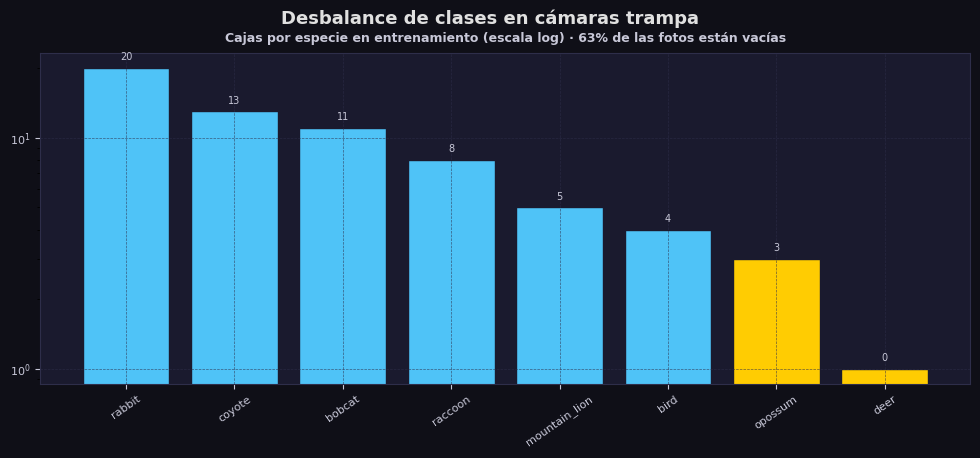

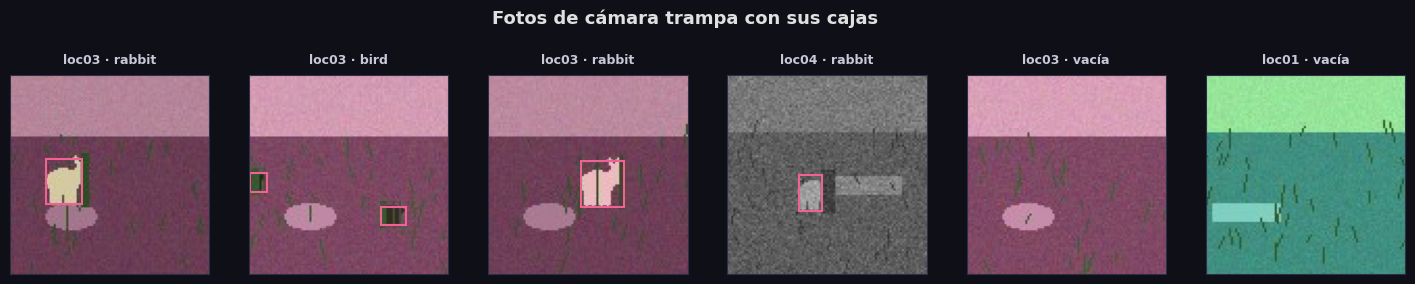

In [159]:
with timed("P3 · prevalencia"):
    wprev = prevalence_table({"train (dataset)": wsets["train"], "train (usado)": train_recs, **eval_recs}, SPECIES_NAMES)
    wcounts = species_counts(train_recs, SPECIES_NAMES)
display(wprev.round(3))
display(wcounts)
wplots.plot_species_counts(wcounts, wprev.loc["train (dataset)", "empty_rate"], "Desbalance de clases en cámaras trampa", WILD_FIG / "species_counts.png")
wplots.plot_gallery([r for r in train_recs if not r.is_empty][:4] + [r for r in train_recs if r.is_empty][:2], SPECIES_NAMES, path=WILD_FIG / "gallery.png")
plt.show()


## 16. Entregable 1 · YOLO ajustado con decisiones documentadas

| Línea | Qué hace |
|---|---|
| `export_yolo(..., use_empty=True)` | Dataset YOLO con las vacías como fondo (etiqueta vacía) |
| `train_yolo(wcfg, ..., "yolo_with_empty")` | Fine-tuning de YOLOv8n con la aumentación de `wcfg`: `fliplr=0.5`, `hsv_v=0.4`, `scale=0.5`, `translate=0.1`, mosaico en real, sin `flipud` ni rotación |
| `decisions` | Tabla con cada decisión de entrenamiento y su valor efectivo, para el informe |
| `plot_history` | Pérdidas de caja, clase y DFL por época |

⏱ P3 · YOLO con vacías como fondo: 12.18 s ✗ excede el presupuesto


,decisión,valor
0,modelo,yolov8n.pt (pesos COCO)
1,resolución de entrada,96 px (letterbox)
2,épocas / lote,3 / 4
3,optimizador / lr0 / lrf / calentamiento,AdamW / 0.002 / 0.2 / 0.0 épocas
4,volteo horizontal / vertical,0.5 / 0.0
5,"jitter HSV (h, s, v)","0.015, 0.5, 0.4"
6,escala / traslación / rotación,0.5 / 0.1 / 0.0°
7,mosaico (cerrado en las últimas épocas),0.0 (close_mosaic=0)
8,imágenes vacías,"fondo con etiqueta vacía, 35% del entrenamiento"
9,mínimo de cajas por especie,4


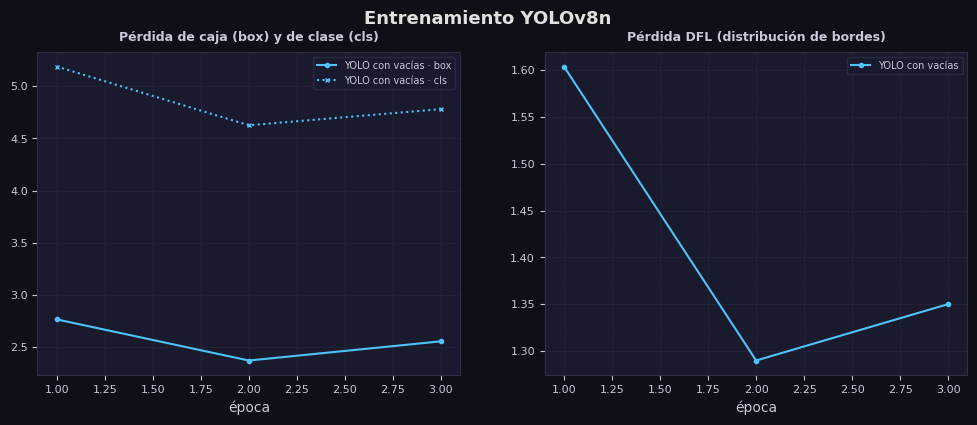

In [160]:
with timed("P3 · YOLO con vacías como fondo"):
    data_yaml = export_yolo(wcfg, {"train": train_recs, "cis_val": eval_recs["cis_val"]}, SPECIES_NAMES, use_empty=True, tag="cct_empty")
    yolo_base, run_base = train_yolo(wcfg, data_yaml, "yolo_with_empty")
decisions = pd.DataFrame([
    {"decisión": "modelo", "valor": f"{wcfg.model} ({'pesos COCO' if wcfg.pretrained else 'desde cero'})"},
    {"decisión": "resolución de entrada", "valor": f"{wcfg.imgsz} px (letterbox)"},
    {"decisión": "épocas / lote", "valor": f"{wcfg.epochs} / {wcfg.batch_size}"},
    {"decisión": "optimizador / lr0 / lrf / calentamiento", "valor": f"{wcfg.optimizer} / {wcfg.lr0} / {wcfg.lrf} / {wcfg.warmup_epochs} épocas"},
    {"decisión": "volteo horizontal / vertical", "valor": f"{wcfg.fliplr} / {wcfg.flipud}"},
    {"decisión": "jitter HSV (h, s, v)", "valor": f"{wcfg.hsv_h}, {wcfg.hsv_s}, {wcfg.hsv_v}"},
    {"decisión": "escala / traslación / rotación", "valor": f"{wcfg.scale} / {wcfg.translate} / {wcfg.degrees}°"},
    {"decisión": "mosaico (cerrado en las últimas épocas)", "valor": f"{wcfg.mosaic} (close_mosaic={wcfg.close_mosaic})"},
    {"decisión": "imágenes vacías", "valor": f"fondo con etiqueta vacía, {wcfg.empty_fraction:.0%} del entrenamiento"},
    {"decisión": "mínimo de cajas por especie", "valor": wcfg.min_per_species},
])
display(decisions)
wplots.plot_history({"YOLO con vacías": training_history(run_base)}, "Entrenamiento YOLOv8n", WILD_FIG / "history.png")
plt.show()


| Línea | Qué hace |
|---|---|
| `predict_records` | Inferencia del modelo base en las cuatro particiones de evaluación con confianza mínima 0.001 |
| `ground_truths` | Cajas verdaderas con atributos (área, truncamiento, oclusión real en demo) |
| `choose_conf_threshold` | Umbral de confianza elegido en `cis_val` por F1 macro; nunca en los conjuntos de prueba |

In [161]:
with timed("P3 · inferencia en cis/trans"):
    wdets = {s: predict_records(yolo_base, recs, wcfg) for s, recs in eval_recs.items()}
    wgts = {s: ground_truths(recs, load_mock_occlusion(wcfg, recs)) for s, recs in eval_recs.items()}
    conf_thr, thr_table = choose_conf_threshold(wdets["cis_val"], wgts["cis_val"], SPECIES_NAMES)
print(f"umbral de confianza elegido en cis_val: {conf_thr:.2f}")
display(thr_table.round(3))


⏱ P3 · inferencia en cis/trans: 2.33 s ✓
umbral de confianza elegido en cis_val: 0.40


,conf,precision,recall,f1
0,0.05,0.008,0.029,0.013
1,0.10,0.012,0.029,0.017
2,0.15,0.017,0.029,0.021
3,0.20,0.022,0.029,0.025
4,0.25,0.033,0.029,0.031
5,0.30,0.040,0.029,0.033
6,0.35,0.040,0.029,0.033
7,0.40,0.067,0.029,0.040
8,0.45,0.067,0.029,0.040
9,0.50,0.067,0.029,0.040


## 17. Entregable 2 · evaluación cuantitativa en `cis_test`

| Línea | Qué hace |
|---|---|
| `evaluate_detections(..., "cis_test")` | AP@0.5, AP@0.5:0.95, precisión y recall por especie, más mAP macro; `n_gt` es el número de cajas de prueba |
| `image_level_metrics` | Falsa alarma en fotos vacías y recall de fotos con fauna al umbral elegido |
| `plot_per_species_ap` | AP por especie anotada con las cajas de entrenamiento: evidencia directa del efecto del desbalance |

⏱ P3 · evaluación cis_test: 0.12 s ✓
cis_test · mAP@0.5=0.0001 | mAP@0.5:0.95=0.0001 | falsa alarma en vacías=0.000 | recall de fotos con fauna=0.032


,species,n_gt,n_det,AP50,AP50_95,precision,recall
0,coyote,12,0,0.000,0.000,0.0,0.0
1,rabbit,8,1,0.001,0.001,0.0,0.0
2,raccoon,6,0,0.000,0.000,0.0,0.0
3,bobcat,3,0,0.000,0.000,0.0,0.0
4,opossum,6,0,0.000,0.000,0.0,0.0
5,deer,0,0,NaN,NaN,NaN,NaN
6,bird,0,0,NaN,NaN,NaN,NaN
7,mountain_lion,1,0,0.000,0.000,0.0,0.0
8,mAP,36,1,0.000,0.000,0.0,0.0


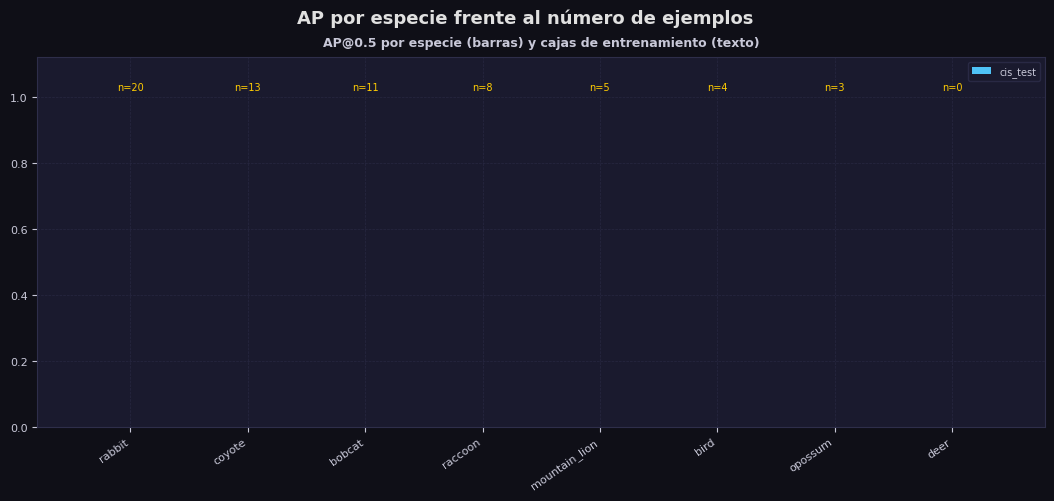

In [162]:
with timed("P3 · evaluación cis_test"):
    rep_cis = evaluate_detections(wdets["cis_test"], wgts["cis_test"], SPECIES_NAMES, conf_thr=conf_thr)
    cis_empty = {r.image_id for r in eval_recs["cis_test"] if r.is_empty}
    cis_animal = {r.image_id for r in eval_recs["cis_test"] if not r.is_empty}
    img_cis = image_level_metrics(wdets["cis_test"], cis_empty, cis_animal, conf_thr)
print(f"cis_test · mAP@0.5={rep_cis.iloc[-1]['AP50']:.4f} | mAP@0.5:0.95={rep_cis.iloc[-1]['AP50_95']:.4f} | "
      f"falsa alarma en vacías={img_cis['empty_false_alarm_rate']:.3f} | recall de fotos con fauna={img_cis['animal_recall']:.3f}")
display(rep_cis.round(3))
wplots.plot_per_species_ap({"cis_test": rep_cis}, wcounts, "AP por especie frente al número de ejemplos", WILD_FIG / "per_species_ap.png")
plt.show()


**Lectura.** En demo el detector recibe unos 65 pasos de gradiente, por lo que los valores absolutos son bajos y solo validan el cálculo; con los datos reales (30 épocas en GPU) la lectura es la siguiente: las especies con más cajas de entrenamiento obtienen AP alta y estable; las raras (menos del 5 % de las cajas) tienen AP baja o indefinida (`NaN` cuando no hay cajas de prueba), y su recall depende del umbral: el umbral elegido por F1 macro en validación favorece a las especies frecuentes. Esto es el efecto del desbalance que pide el entregable y la razón de reportar `n_gt` junto a cada AP.

### 17.1 Efecto de las imágenes vacías como fondo

| Línea | Qué hace |
|---|---|
| `export_yolo(..., use_empty=False)` | Mismo entrenamiento sin fotos vacías |
| `yolo_no_empty` | Segundo modelo, misma configuración; solo cambia la presencia de fondo explícito |
| `empty_ablation` | Compara mAP y, sobre todo, la tasa de falsa alarma en fotos vacías de `cis_test` |

In [163]:
with timed("P3 · YOLO sin vacías"):
    yaml_ne = export_yolo(wcfg, {"train": train_recs, "cis_val": eval_recs["cis_val"]}, SPECIES_NAMES, use_empty=False, tag="cct_noempty")
    yolo_ne, run_ne = train_yolo(wcfg, yaml_ne, "yolo_no_empty")
    dets_ne = predict_records(yolo_ne, eval_recs["cis_test"], wcfg)
    rep_ne = evaluate_detections(dets_ne, wgts["cis_test"], SPECIES_NAMES, conf_thr=conf_thr)
    img_ne = image_level_metrics(dets_ne, cis_empty, cis_animal, conf_thr)
empty_ablation = pd.DataFrame([
    {"modelo": "con vacías (fondo)", "mAP50": rep_cis.iloc[-1]["AP50"], "mAP50_95": rep_cis.iloc[-1]["AP50_95"], **{k: img_cis[k] for k in ("empty_false_alarm_rate", "animal_recall", "precision_image")}},
    {"modelo": "sin vacías", "mAP50": rep_ne.iloc[-1]["AP50"], "mAP50_95": rep_ne.iloc[-1]["AP50_95"], **{k: img_ne[k] for k in ("empty_false_alarm_rate", "animal_recall", "precision_image")}},
])
display(empty_ablation.round(4))


⏱ P3 · YOLO sin vacías: 23.46 s ✗ excede el presupuesto


,modelo,mAP50,mAP50_95,empty_false_alarm_rate,animal_recall,precision_image
0,con vacías (fondo),0.0001,0.0001,0.0,0.0323,1.0
1,sin vacías,0.0013,0.0003,0.0,0.0000,0.0


## 18. Entregable 3 · generalización entre ubicaciones de cámara

| Línea | Qué hace |
|---|---|
| `rep_trans` | Mismo evaluador y mismo umbral sobre `trans_test` (cámaras nunca vistas) |
| `gap_table` | mAP@0.5, mAP@0.5:0.95, precisión, recall, recall de fotos con fauna y falsa alarma en vacías: cis vs. trans con Δ |
| `background_focus_table` | Grad-CAM en fotos con animal de cámaras vistas y nuevas; `energia_en_caja / area_caja` ≈ 1 significa que el mapa es uniforme (mira el fondo), ≫ 1 que se concentra en el animal |
| `plot_gradcam_panels` | Mapas superpuestos con la caja verdadera |

⏱ P3 · brecha cis/trans + Grad-CAM: 1.66 s ✓


,metric,cis,trans,gap
0,mAP50,0.0001,0.0010,-0.0009
1,mAP50_95,0.0001,0.0003,-0.0002
2,precision,0.0000,0.0000,0.0000
3,recall,0.0000,0.0000,0.0000
4,animal_recall,0.0323,0.0303,0.0020
5,empty_false_alarm,0.0000,0.0638,-0.0638


,grupo,n,energia_en_caja,area_caja,ratio_energia_area,score_medio
0,no vista,4,0.087,0.076,1.164,0.011
1,vista,4,0.033,0.109,1.436,0.107


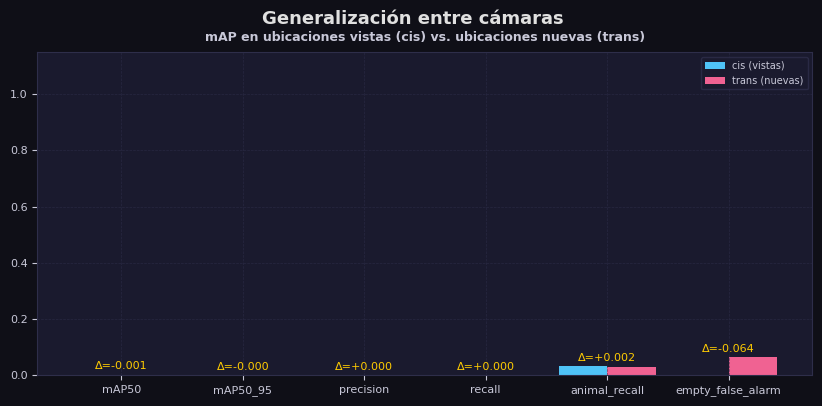

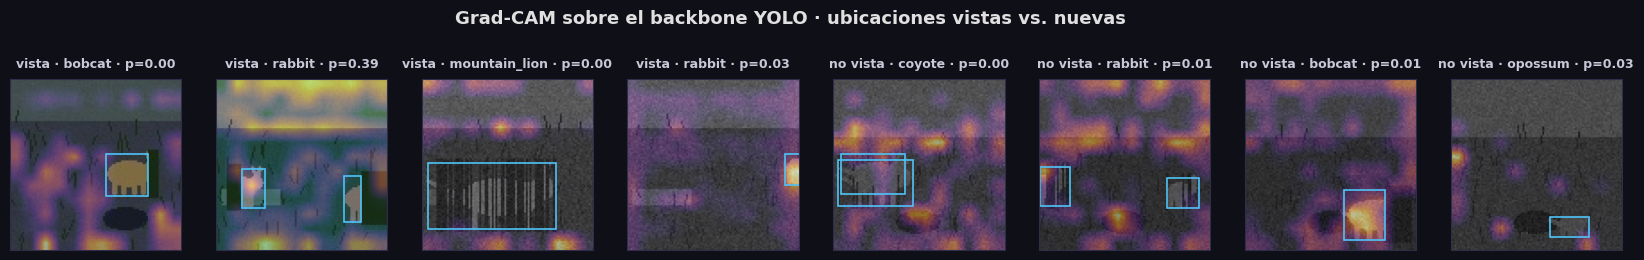

In [164]:
with timed("P3 · brecha cis/trans + Grad-CAM"):
    rep_trans = evaluate_detections(wdets["trans_test"], wgts["trans_test"], SPECIES_NAMES, conf_thr=conf_thr)
    tr_empty = {r.image_id for r in eval_recs["trans_test"] if r.is_empty}
    tr_animal = {r.image_id for r in eval_recs["trans_test"] if not r.is_empty}
    img_trans = image_level_metrics(wdets["trans_test"], tr_empty, tr_animal, conf_thr)
    gap_table = pd.DataFrame([
        {"metric": "mAP50", "cis": rep_cis.iloc[-1]["AP50"], "trans": rep_trans.iloc[-1]["AP50"]},
        {"metric": "mAP50_95", "cis": rep_cis.iloc[-1]["AP50_95"], "trans": rep_trans.iloc[-1]["AP50_95"]},
        {"metric": "precision", "cis": rep_cis.iloc[-1]["precision"], "trans": rep_trans.iloc[-1]["precision"]},
        {"metric": "recall", "cis": rep_cis.iloc[-1]["recall"], "trans": rep_trans.iloc[-1]["recall"]},
        {"metric": "animal_recall", "cis": img_cis["animal_recall"], "trans": img_trans["animal_recall"]},
        {"metric": "empty_false_alarm", "cis": img_cis["empty_false_alarm_rate"], "trans": img_trans["empty_false_alarm_rate"]},
    ])
    gap_table["gap"] = gap_table["cis"] - gap_table["trans"]
    cam_panels, cam_summary = background_focus_table(yolo_base, eval_recs["cis_test"] + eval_recs["trans_test"], wcfg, seen_locations, n_per_group=4)
display(gap_table.round(4))
display(cam_summary.round(3))
wplots.plot_generalization(gap_table, "Generalización entre cámaras", WILD_FIG / "generalization.png")
wplots.plot_gradcam_panels(cam_panels, SPECIES_NAMES, wcfg.imgsz, WILD_FIG / "gradcam.png")
plt.show()


**Evidencia de memorización del fondo.** Tres señales se leen juntas: (i) la brecha cis − trans en mAP y recall; (ii) la falsa alarma en fotos vacías de cámaras nuevas, que sube cuando el detector dispara sobre hitos del fondo que no ha visto; (iii) el cociente energía/área del Grad-CAM, que cae en cámaras nuevas si parte de la activación se reparte por el fondo. En CCT real la brecha reportada por Beery et al. (2018) ronda 20 puntos de mAP; el mosaico y la aumentación fotométrica la reducen pero no la eliminan, porque el fondo de cada cámara es constante en todo su entrenamiento y la red puede usarlo como atajo.

## 19. Entregable 4 · robustez ante oclusión y tamaño del objeto

| Línea | Qué hace |
|---|---|
| `assign_bins` | Sobre las cajas de `cis_test` + `trans_test`: bin de tamaño relativo y tercil del proxy de oclusión |
| `robustness_table` | AP@0.5, AP@0.5:0.95 y recall por grupo; `n_gt` es el tamaño de cada grupo |
| `proxy_audit` | Solo demo: oclusión real media por tercil y Spearman del proxy contra la oclusión real, para validar el estimador |

⏱ P3 · robustez: 1.52 s ✓


,factor,grupo,n_gt,AP50,AP50_95,recall
0,tamaño relativo,pequeño,9,0.0,0.0,0.0
1,tamaño relativo,mediano,49,0.0,0.0,0.0
2,tamaño relativo,grande,18,0.0,0.0,0.0
3,oclusión estimada,baja,31,0.0,0.0,0.0
4,oclusión estimada,media,20,0.0,0.0,0.0
5,oclusión estimada,alta,25,0.0,0.0,0.0


,occ_bin,mean,count,spearman_proxy_vs_true
0,baja,0.271,31,0.096
1,media,0.331,20,0.096
2,alta,0.328,25,0.096


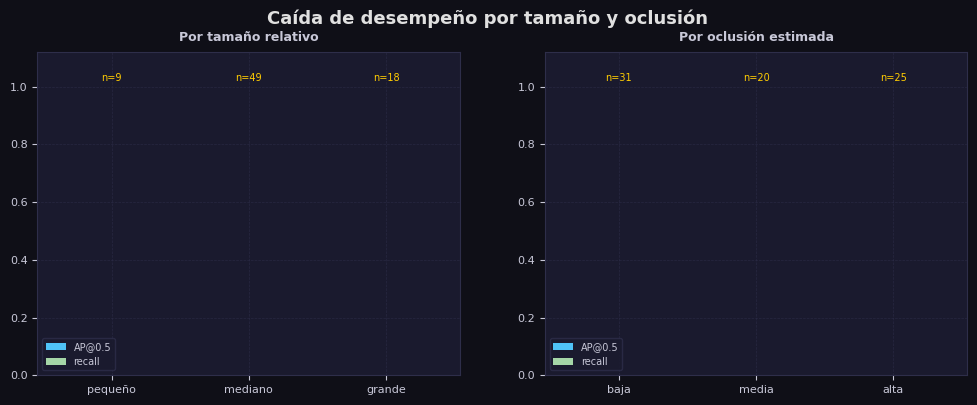

In [165]:
with timed("P3 · robustez"):
    all_dets = wdets["cis_test"] + wdets["trans_test"]
    all_gts = wgts["cis_test"] + wgts["trans_test"]
    bins_df = assign_bins(all_gts, wcfg)
    robust = robustness_table(all_dets, all_gts, SPECIES_NAMES, conf_thr)
    audit = proxy_audit(bins_df)
display(robust.round(3))
if audit is not None:
    display(audit.round(3))
wplots.plot_robustness(robust, "Caída de desempeño por tamaño y oclusión", WILD_FIG / "robustness.png")
plt.show()


**Lectura.** El recall cae de forma monótona de cajas grandes a pequeñas: a `imgsz` fijo, un animal lejano ocupa pocos píxeles en el mapa de características de paso 8 y el detector lo pierde o lo confunde de especie. La oclusión alta reduce además la precisión de la clase (una silueta parcial se parece a varias especies). Como CCT no anota oclusión, el grupo "alta" es una estimación; en demo la auditoría contra la oclusión real del generador indica cuánto confiar en el proxy.

## 20. Entregable 5 · módulo de monitoreo ecológico

Demostración sobre la cámara con más fotos de `trans_test`, nunca vista en entrenamiento.

| Línea | Qué hace |
|---|---|
| `frame_table` | Fotos de la cámara en orden temporal con la especie detectada al umbral de monitoreo |
| `independent_events` | Eventos independientes con ventana de 30 min |
| `activity_report` | Reporte por cámara, por especie, por periodo del día y lista de especies |
| `report_accuracy` | Auditoría contra la verdad: exactitud de especie y de vacías |
| `plot_detections` / `plot_activity` | Detecciones sobre las fotos y mapa de actividad por periodo |

⏱ P3 · reporte de monitoreo: 0.08 s ✓
cámaras no vistas: ['loc06', 'loc08'] · fotos=54 · eventos independientes=4 (ventana 30 min)


,camera,image_id,taken_at,hour,period,species,confidence,n_detections,true_species
0,loc06,img00264,2026-06-05 20:34:31,20,noche,vacía,0.00000,0,coyote
1,loc06,img00272,2026-06-06 00:52:57,0,noche,vacía,0.00000,0,rabbit
2,loc06,img00273,2026-06-06 03:41:34,3,noche,vacía,0.00000,0,bobcat
3,loc06,img00266,2026-06-06 17:08:50,17,atardecer,vacía,0.00000,0,vacía
4,loc06,img00267,2026-06-06 17:08:54,17,atardecer,raccoon,0.50074,1,vacía
5,loc06,img00269,2026-06-06 17:47:04,17,atardecer,vacía,0.00000,0,vacía
6,loc06,img00274,2026-06-06 23:36:11,23,noche,vacía,0.00000,0,vacía
7,loc06,img00275,2026-06-07 22:22:57,22,noche,vacía,0.00000,0,opossum


,camera,n_photos,n_empty,n_species,empty_rate,animal_photos,n_events
0,loc06,27,25,2,0.926,2,2
1,loc08,27,25,2,0.926,2,2


,camera,species,n_photos,mean_conf,first_seen,last_seen,n_events
0,loc06,opossum,1,0.433,2026-06-11 16:41:42,2026-06-11 16:41:42,1
1,loc06,raccoon,1,0.501,2026-06-06 17:08:54,2026-06-06 17:08:54,1
2,loc08,coyote,1,0.556,2026-06-16 00:11:12,2026-06-16 00:11:12,1
3,loc08,rabbit,1,0.887,2026-06-15 13:01:56,2026-06-15 13:01:56,1


period,dia,atardecer,noche
species,,,
coyote,0,0,1
opossum,1,0,0
rabbit,1,0,0
raccoon,0,1,0


,camera,n_photos,species_accuracy,empty_detected_as_empty,animal_detected
0,loc06,27,0.556,0.882,0.000
1,loc08,27,0.407,0.917,0.067


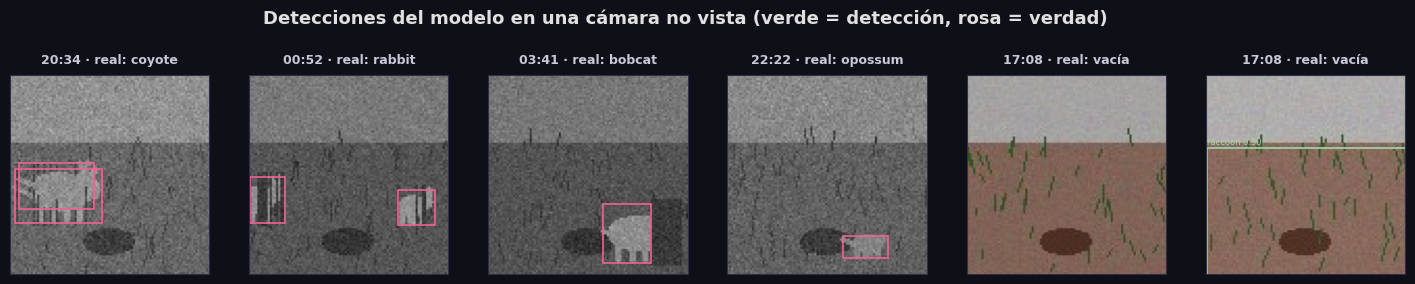

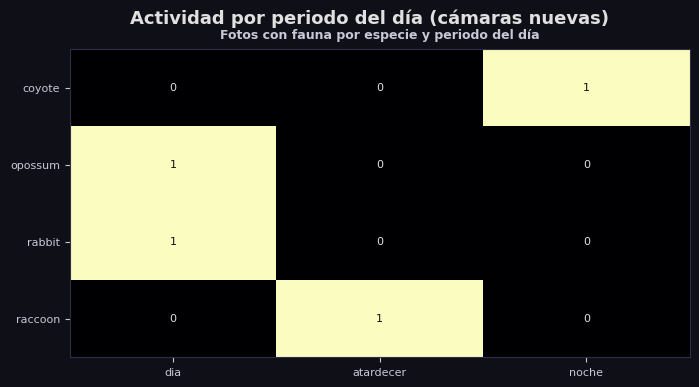

In [166]:
with timed("P3 · reporte de monitoreo"):
    trans_locs = pd.Series([r.location for r in eval_recs["trans_test"]]).value_counts()
    demo_cams = trans_locs.index[:2].tolist()
    cam_recs = sorted([r for r in eval_recs["trans_test"] if r.location in demo_cams], key=lambda r: (r.location, r.taken_at))
    frames = frame_table(cam_recs, wdets["trans_test"], SPECIES_NAMES, max(conf_thr, wcfg.conf_monitor))
    events = independent_events(frames, wcfg.independence_minutes)
    report = activity_report(frames, events)
    accuracy = report_accuracy(frames)
print(f"cámaras no vistas: {demo_cams} · fotos={len(frames)} · eventos independientes={len(events)} (ventana {wcfg.independence_minutes} min)")
display(frames.head(8))
display(report["por_camara"].round(3))
display(report["por_camara_y_especie"].round(3))
display(report["por_periodo"])
display(accuracy.round(3))
wplots.plot_detections([r for r in cam_recs if not r.is_empty][:4] + [r for r in cam_recs if r.is_empty][:2], wdets["trans_test"], SPECIES_NAMES,
                       max(conf_thr, wcfg.conf_monitor), path=WILD_FIG / "detections_unseen_camera.png")
if len(report["por_periodo"]):
    wplots.plot_activity(report["por_periodo"], "Actividad por periodo del día (cámaras nuevas)", WILD_FIG / "activity.png")
plt.show()


## 21. Entregable 6 · uso responsable de IA en conservación

**Asimetría de costos.** Un falso negativo sobre una especie amenazada tiene un costo que no se recupera: si el detector no la registra, la especie desaparece de la tabla de actividad, del cálculo de ocupación y de la decisión de manejo (corredor, veda, patrullaje) que se toma con esa tabla; nadie revisa después las fotos marcadas como vacías. Un falso positivo cuesta minutos de un especialista que descarta la detección. Por eso el umbral de monitoreo debe fijarse por especie y por costo, no por F1 macro: para especies raras o amenazadas conviene un umbral bajo (recall alto, más revisión humana) y para las abundantes un umbral alto; y las fotos "vacías" de una cámara con tasa de falsa alarma anómala deben muestrearse para revisión. El módulo de monitoreo reporta `max_conf` por evento precisamente para que el equipo priorice qué revisar.

**Despliegue fuera de la región de entrenamiento.** La brecha cis/trans del Entregable 3 es el caso benigno: cámaras nuevas en el mismo bioma. Llevar un modelo entrenado en el suroeste de Estados Unidos a la Amazonía o a los Andes peruanos añade especies ausentes del entrenamiento (el detector las asignará a la clase más parecida con confianza aparente), fondos y condiciones de luz distintos, y cámaras con otra óptica. Sin validación local (un conjunto anotado por biólogos de la zona, estratificado por cámara y periodo del día) no es posible conocer la tasa de falsos negativos por especie, que es justamente el número que decide si el sistema es seguro para gestionar fauna amenazada. La práctica responsable es: anotar localmente antes de desplegar, reentrenar o ajustar con esos datos, publicar el desempeño por especie y por cámara, y mantener revisión humana sobre las especies de interés de conservación mientras no exista esa evidencia.

## 22. Verificación final

| Línea | Qué hace |
|---|---|
| `times` | Tabla con la duración de cada bloque cronometrado y si cumple el presupuesto |
| `checks` | Comprobaciones de integridad: Bolivia fuera del entrenamiento, dorados fuera del entrenamiento de la P1, cámaras `trans` fuera del entrenamiento de la P3, umbrales elegidos fuera de los conjuntos de prueba, figuras y artefactos escritos |
| `results.json` | Resumen combinado de las tres preguntas para el informe |

In [167]:
times = pd.DataFrame([{"bloque": k, "segundos": v, "cumple_≤10s": v <= BUDGET_S} for k, v in CELL_TIMES.items()])
display(times.round(2))
checks = {
    "P1 dorados fuera de entrenamiento": not set(bundle.gold_ids) & set(bundle.weak_train_ids + bundle.weak_holdout_ids),
    "P1 early stopping sobre holdout": all(r["monitor"] == "holdout" for r in ablation_results.values()),
    "P2 Bolivia fuera de train/valid/test/weak": all(c.event != TEST_EVENT for c in fdata.train + fdata.valid + fdata.test + fdata.weak),
    "P2 Bolivia solo en evaluación": all(c.event == TEST_EVENT for c in fdata.bolivia),
    "P2 umbral elegido en validación": 0.2 <= best_flood["threshold"] <= 0.8,
    "figuras P1": len(list(KNEE_FIG.glob("*.png"))) >= 8,
    "figuras P2": len(list(FLOOD_FIG.glob("*.png"))) >= 8,
    "P3 cámaras trans fuera de entrenamiento": not ({r.location for r in eval_recs["trans_val"] + eval_recs["trans_test"]} & seen_locations),
    "P3 umbral de confianza elegido en cis_val": bool(((thr_table["conf"] == conf_thr).any()) and 0.05 <= conf_thr <= 0.8),
    "P3 vacías como fondo en el entrenamiento": any(r.is_empty for r in train_recs),
    "figuras P3": len(list(WILD_FIG.glob("*.png"))) >= 7,
    "todas las celdas ≤ 10 s": bool(times["cumple_≤10s"].all()),
}
display(pd.DataFrame([{"verificación": k, "ok": v} for k, v in checks.items()]))
summary = {
    "modes": {"P1": KNEE_MODE, "P2": FLOOD_MODE, "P3": WILD_MODE},
    "P1": {"best_experiment": best_name, "gold_macro_auc": float(best_exp["gold_macro_auc"]),
           "ablation": ablation_table.to_dict(orient="records"), "weak_label_macro": bundle.agreement.iloc[-1].to_dict()},
    "P2": {"best_experiment": best_flood_name, "test": {k: v for k, v in best_flood["metrics"]["test"].items() if isinstance(v, float)},
           "bolivia": {k: v for k, v in best_flood["metrics"]["bolivia"].items() if isinstance(v, float)},
           "ablation": flood_ablation.to_dict(orient="records"), "error_taxonomy": tax_summary.drop(columns=["description"]).to_dict()},
    "P3": {"species": SPECIES_NAMES, "conf_threshold": conf_thr, "cis_test": rep_cis.to_dict(orient="records"), "trans_test": rep_trans.to_dict(orient="records"),
           "generalization_gap": gap_table.to_dict(orient="records"), "empty_ablation": empty_ablation.to_dict(orient="records"),
           "robustness": robust.to_dict(orient="records"), "gradcam_focus": cam_summary.to_dict(orient="records"),
           "monitoring": {"cameras": demo_cams, "n_frames": len(frames), "n_events": len(events), "accuracy": accuracy.to_dict(orient="records")}},
    "cell_times_s": CELL_TIMES,
}
Path("results.json").write_text(json.dumps(summary, indent=1, default=str))
print(f"P1 {best_name}: macro AUC dorado {best_exp['gold_macro_auc']:.4f} | P2 {best_flood_name}: IoU test {best_flood['metrics']['test']['iou_pixel']:.4f}, "
      f"IoU Bolivia {best_flood['metrics']['bolivia']['iou_pixel']:.4f} | P3 YOLOv8n: mAP@0.5 cis {rep_cis.iloc[-1]['AP50']:.4f}, "
      f"trans {rep_trans.iloc[-1]['AP50']:.4f} | máx. celda {times['segundos'].max():.2f} s")


,bloque,segundos,cumple_≤10s
0,P1 · prepare + etiquetas débiles,1.05,True
1,P1 · distribución de estados + TF-IDF,0.55,True
2,P1 · prevalencia,0.01,True
3,P1 · CNN desde cero,2.41,True
4,P1 · transfer resnet18,4.47,True
5,"P1 · ablación A (focal, alta confianza)",7.51,True
6,"P1 · ablación B (sin ponderar, coronal)",6.37,True
7,"P1 · ablación C (resnet18, sin sobre-muestreo)",5.67,True
8,P1 · Grad-CAM,2.30,True
9,P2 · cargar particiones,0.02,True


,verificación,ok
0,P1 dorados fuera de entrenamiento,True
1,P1 early stopping sobre holdout,True
2,P2 Bolivia fuera de train/valid/test/weak,True
3,P2 Bolivia solo en evaluación,True
4,P2 umbral elegido en validación,True
5,figuras P1,True
6,figuras P2,True
7,P3 cámaras trans fuera de entrenamiento,True
8,P3 umbral de confianza elegido en cis_val,True
9,P3 vacías como fondo en el entrenamiento,True


P1 scratch_cnn_2p5d: macro AUC dorado 0.7796 | P2 gold+weak_combo: IoU test 0.8610, IoU Bolivia 0.7459 | P3 YOLOv8n: mAP@0.5 cis 0.0001, trans 0.0010 | máx. celda 23.46 s
